# Evaluación integral de pares sintéticos imagen–máscara

**Objetivo específico 4.** Evaluar la calidad, coherencia anatómica y fidelidad distribucional de los pares sintéticos imagen–máscara generados mediante la arquitectura de difusión en cascada.

El procedimiento considera 1.260 pares sintéticos distribuidos en nueve combinaciones de tipo de tumor y plano anatómico, con 420 pares del conjunto de prueba como referencia principal. Se evalúan la calidad técnica, la coherencia imagen–máscara, la consistencia condicional, la fidelidad distribucional y la diversidad mediante métricas y modelos externos.

## Configuración del experimento

Se establecen los directorios de datos y resultados, las rutas de los modelos previamente entrenados y los parámetros de evaluación. La generación de máscaras e imágenes está desactivada por defecto; los análisis se habilitan individualmente mediante `RUN`.

In [25]:
from pathlib import Path, PureWindowsPath
import os


def localizar_raiz_repositorio():
    """Ubica el repositorio desde el directorio de ejecución o TESIS_REPO_ROOT."""
    configurada = os.environ.get('TESIS_REPO_ROOT')
    if configurada:
        candidata = Path(configurada).expanduser().resolve()
        if not (candidata / 'notebooks' / 'OE4').is_dir():
            raise FileNotFoundError(
                f'TESIS_REPO_ROOT no contiene notebooks/OE4: {candidata}'
            )
        return candidata

    directorio = Path.cwd().resolve()
    for candidata in (directorio, *directorio.parents):
        if (candidata / 'notebooks' / 'OE4').is_dir():
            return candidata
    raise FileNotFoundError(
        'No se encontró la raíz del repositorio. Ubicar el notebook en '
        'notebooks/OE4/ y ejecutarlo desde el repositorio, o definir TESIS_REPO_ROOT.'
    )


REPO_ROOT = localizar_raiz_repositorio()
RESULTS_ROOT = REPO_ROOT / 'results'
OUT = RESULTS_ROOT / 'OE4'
DATA_ROOT = REPO_ROOT / 'data' / 'BRISC2025' / 'segmentation_task'
SPLIT_CSV = RESULTS_ROOT / 'OE2' / 'particiones' / 'brisc_test_validation_test_50_50.csv'
OE2_ROOT = RESULTS_ROOT / 'OE2' / 'difusion_bernoulli' / 'final' / 'roiOE1_peso10'
OE3_ROOT = RESULTS_ROOT / 'OE3' / 'difusion_gaussiana_v3' / 'snr5_W1,2,6'
OE2_CHECKPOINT = OE2_ROOT / 'checkpoints' / 'best.pt'
OE3_CHECKPOINT = OE3_ROOT / 'checkpoints' / 'best_val_ema.pt'
OE2_QC_CSV = OE2_ROOT / 'tablas' / 'qc_ranges_train.csv'
OE3_EVALUATION = RESULTS_ROOT / 'OE3' / 'evaluacion_seleccion_DDIM'
EXISTING_SEGMENTER_CACHE = OE3_EVALUATION / 'cache' / 'pesos_segmentadores'

# Cada bloque de generación o evaluación se controla de forma independiente.
# Los bloques que necesitan características/predicciones comparten la caché,
# pero no requieren conservar las carpetas de resultados de otros métodos.
RUN = {
    'generar_mascaras': False,
    'generar_imagenes': False,
    'calidad': True,
    'fid': True,
    'fd_dinov2': True,
    'dice': True,
    'hd95': True,
    'intensidades': True,
    'densidad_cobertura': True,
    'clasificacion': True,
    'galeria_sinteticos': True,
    'ejemplos_segformer': True,
    'actualizar_figuras': True,
}
SEGMENTERS = ['SegFormer_B5_BRISC']
SEED = 20261110
N_LOTS = 1  # Un único conjunto sintético de evaluación
N_PER_CONDITION = 40  # Pares adicionales por condición
SIZE = 256
DDIM_STEPS, DDIM_ETA = 200, 0.2
MASK_SAMPLING_STEPS = 100
MASK_SIGMA, MIN_COMPONENT_PIXELS = 2.0, 8
MAX_MASK_ATTEMPT_FACTOR = 20
EXPECTED_OE2_EPOCH, EXPECTED_OE3_EPOCH = 141, 83
EXPECTED_COUNTS = {'train': 3792, 'validation': 420, 'test_final': 420}
STRICT_COUNTS = True

N_FRECHET = 1000
N_PERMUTATIONS = 1999
N_REFERENCE_DESCRIPTORS = 200  # Compatibilidad de protocolos Energy existentes
N_DIVERSITY = 200
K_NEIGHBORS = 5
RING_RADIUS = 5
RING_MIN_PIXELS = 10
INTENSITY_THRESHOLD, BRIGHTNESS_THRESHOLD = 15, 22
MASK_THRESHOLD = 127
SEGMENTATION_THRESHOLDS = {'SegFormer_B5_BRISC': 0.50}

# Configuración de memoria: modelos auxiliares ejecutados secuencialmente.
IMAGE_BATCH = 2
FEATURE_BATCH = 8
GENERATION_AMP = False  # Conserva FP32 del muestreo final de OE3; reducir IMAGE_BATCH si falta VRAM.
PREFER_CUDA_FRECHET = True
NUM_WORKERS = 0
SHOW_FIGURES = True
SAVE_REJECTED_MASKS = True
ALLOW_CPU_GENERATION = False  # Evita iniciar por error miles de inferencias en CPU.
STOP_ON_ERROR = True
LOCAL_SEGFORMER = None
HF_REVISION_DINO = 'main'
HF_REVISION_SEGFORMER_BASE = 'main'
HF_REVISION_SEGFORMER_WEIGHTS = 'main'

PIPELINE_VERSION = 'OE4_1260_v2'
# Migración controlada de los protocolos creados con rutas absolutas.
# Se aceptan exclusivamente diferencias en firmas antiguas; el resto de
# los parámetros experimentales debe coincidir. Los originales se respaldan.
MIGRAR_PROTOCOLOS_LEGADOS = True
FIRMA_CONTENIDO_VERSION = 'sha256_contenido_v1'

TOTAL_PER_CONDITION = 140
EXISTING_PER_CONDITION = 100
EXISTING_900_CSV = OE3_EVALUATION / '00_inventarios' / 'sinteticas_8_configuraciones.csv'
SELECTED_CONFIG = 'ddim_steps200_eta0p2'
# Los resultados previos pueden permanecer en la estructura histórica durante la migración.
# Estas carpetas se consultan sin modificarlas.
LEGACY_OE4_ROOT = RESULTS_ROOT / 'objetivo_especifico_4'
LEGACY_MASKS_NEW = OUT / '01_generacion' / 'mascaras_Bernoulli'
LEGACY_IMAGES_NEW = OUT / '01_generacion' / 'imagenes_DDIM'
LEGACY_MASKS = (LEGACY_MASKS_NEW if LEGACY_MASKS_NEW.exists()
                else LEGACY_OE4_ROOT / '01_generacion' / 'mascaras_Bernoulli')
LEGACY_IMAGES = (LEGACY_IMAGES_NEW if LEGACY_IMAGES_NEW.exists()
                 else LEGACY_OE4_ROOT / '01_generacion' / 'imagenes_DDIM')
IMPORT_PREVIOUS_PROGRESS = True


# El clasificador se utiliza exclusivamente para la consistencia tumoral;
# las métricas Dice y HD95 se calculan mediante segmentadores externos.
CLASSIFICATION_BATCH_SIZE = 16  # Reducir a 8 si la GPU no alcanza.
CLASSIFICATION_REPO = 'Purino/densenet121-brain-mri-tumor'
CLASSIFICATION_REVISION = 'main'
CLASSIFICATION_ORDER = ['gl', 'me', 'no_tumor', 'pi']



## Utilidades y organización de datos

Se definen los directorios de salida, los procedimientos de lectura y escritura, las operaciones morfológicas y las herramientas comunes de evaluación.

### Salidas y visualizaciones

Se preparan los directorios del experimento y las funciones de representación gráfica.

In [26]:
import sys, re, json, math, time, gc, hashlib, warnings, platform, importlib, shutil
import importlib.metadata as metadata
from contextlib import nullcontext
from types import SimpleNamespace, ModuleType
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from scipy import ndimage as ndi
from scipy.linalg import svdvals
from scipy.spatial.distance import cdist
from scipy.stats import wasserstein_distance
from skimage.measure import perimeter_crofton
from skimage.morphology import convex_hull_image
from tqdm.auto import tqdm
from IPython.display import display

CONDITIONS = [f'{t}_{p}' for t in ('gl', 'me', 'pi') for p in ('ax', 'co', 'sa')]
TUMOR_IDS = {'gl': 0, 'me': 1, 'pi': 2}
PLANE_IDS = {'ax': 0, 'co': 1, 'sa': 2}
LOT_NAMES = ['conjunto_1260'] # Etiqueta interna de dataset; no es un lote experimental
MORPH6 = ['area_fraction', 'centroid_x', 'centroid_y', 'bbox_w', 'bbox_h', 'n_components']
REGIONS = ['completa', 'tumor', 'no_tumoral']
STRUCTURE = np.ones((3, 3), dtype=bool)
DIR = {
    'protocol': OUT / '00_protocolo' / 'plan_1260',
    'masks': OUT / '01_generacion' / 'mascaras_adicionales_360',
    'images': OUT / '01_generacion' / 'imagenes_adicionales_360',
    'AR': OUT / '02_calidad' / 'area_relativa',
    'BE': OUT / '02_calidad' / 'brillo_exterior',
    'quality_joint': OUT / '02_calidad' / 'alerta_conjunta',
    'fid': OUT / '03_fidelidad_imagenes' / 'FID_InceptionV3',
    'fd_dinov2': OUT / '03_fidelidad_imagenes' / 'FD_DINOv2',
    'coherence': OUT / '04_coherencia',
    'intensity': OUT / '06_intensidades',
    'density': OUT / '09_diversidad' / 'densidad_DINOv2',
    'coverage': OUT / '09_diversidad' / 'cobertura_DINOv2',
    'classification': OUT / '11_consistencia_condicional' / 'Purino_DenseNet121',
    'summary': OUT / '15_resumen_ejecucion' / 'plan_1260',
    'cache': OUT / '99_cache' / 'plan_1260',
    'graphics': OUT / 'graficos',
}
DIR['combined'] = OUT / '01_generacion' / 'conjunto_1260'
DIR['migration'] = DIR['combined'] / 'recuperacion_avance'
for p in DIR.values():
    p.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 220, 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False})


REGION_COLORS = {'completa': '#1f77b4', 'tumor': '#2ca02c', 'no_tumoral': '#ff7f0e'}
SYNTHETIC_COLOR = '#7A3DB8'
TUMOR_COLORS = {'gl': '#1f77b4', 'pi': '#2ca02c', 'me': '#ff7f0e'}
PLANE_COLORS = {'ax': '#1f77b4', 'sa': '#2ca02c', 'co': '#ff7f0e'}
TUMOR_NAMES = {'gl': 'Glioma', 'me': 'Meningioma', 'pi': 'Pituitario'}
PLANE_NAMES = {'ax': 'Axial', 'co': 'Coronal', 'sa': 'Sagital'}
REGION_NAMES = {'completa': 'imagen completa', 'tumor': 'imagen tumoral', 'no_tumoral': 'imagen no tumoral'}
COMPARISON_LABELS = {
    'train_train': 'Ent-Ent',
    'test_train': 'Test-Ent',
    'test_conjunto_1260': 'Test-Sintéticos',
}


def mirror_figure(folder, name, export_name=None):
    """Copia solo el PDF a graficos; deja intactos los archivos originales."""
    export_name = export_name or name
    folder = Path(folder)
    source_pdf = folder / f'{name}.pdf'
    if source_pdf.exists():
        target_dir = DIR['graphics']
        target_dir.mkdir(parents=True, exist_ok=True)
        shutil.copy2(source_pdf, target_dir / f'{export_name}.pdf')
        # Retirar una copia PNG previa de esta misma figura, si existe.
        old_png = target_dir / f'{export_name}.png'
        if old_png.exists():
            old_png.unlink()


def figure_save(fig, folder, name, show=None, mirror_name=None):
    folder = Path(folder); folder.mkdir(parents=True, exist_ok=True)
    fig.savefig(folder / f'{name}.png', bbox_inches='tight')
    fig.savefig(folder / f'{name}.pdf', bbox_inches='tight')
    if mirror_name:
        mirror_figure(folder, name, mirror_name)
    if SHOW_FIGURES if show is None else show:
        display(fig)
    plt.close(fig)


def distribution_plot(df, value, group, folder, name, ylabel=None, label_map=None,
                      title=None, ylim=None, colors=None, mirror_name=None):
    cats = list(dict.fromkeys(df[group].astype(str)))
    arrays = [df.loc[df[group].astype(str) == c, value].dropna().to_numpy() for c in cats]
    valid = [(c, a) for c, a in zip(cats, arrays) if len(a)]
    if not valid:
        return
    labels = [(label_map.get(c, c) if label_map else c) for c, _ in valid]
    fig, ax = plt.subplots(figsize=(max(7, len(valid) * 1.4), 4.5))
    ax.boxplot(
        [a for _, a in valid], showfliers=False, patch_artist=False,
        boxprops={'color': '#222222', 'linewidth': 1.2},
        medianprops={'color': '#ff7f0e', 'linewidth': 1.5},
        whiskerprops={'color': '#222222', 'linewidth': 1.1},
        capprops={'color': '#222222', 'linewidth': 1.1},
        flierprops={'marker': ''},
    )
    ax.set_xticks(np.arange(1, len(valid) + 1), labels, rotation=25, ha='right')
    ax.set_ylabel(ylabel or value)
    if title:
        ax.set_title(title)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.grid(axis='y', alpha=.2)
    figure_save(fig, folder, name, mirror_name=mirror_name)


### Persistencia y resúmenes estadísticos

Se establecen escrituras verificables y firmas SHA-256 independientes de la ubicación de los archivos. Los protocolos anteriores basados en rutas y fechas pueden migrarse mediante una verificación de inventarios, con respaldo y registro de auditoría. El proceso conserva las restricciones de compatibilidad experimental.

In [27]:
def json_default(x):
    if isinstance(x, Path): return str(x)
    if isinstance(x, np.generic): return x.item()
    if isinstance(x, np.ndarray): return x.tolist()
    if isinstance(x, (set, tuple)): return list(x)
    raise TypeError(type(x).__name__)

def canonical(x):
    return json.dumps(x, sort_keys=True, ensure_ascii=False, default=json_default)

def digest(x):
    return hashlib.sha256(canonical(x).encode('utf8')).hexdigest()

def stable_seed(*parts):
    return int(digest([SEED, *parts])[:15], 16) % (2**31 - 1)

def atomic_json(obj, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp')
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=json_default), encoding='utf8')
    tmp.replace(path)

def save_csv(df, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp')
    df.to_csv(tmp, index=False, encoding='utf-8-sig'); tmp.replace(path)

def atomic_png(a, path):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp')
    Image.fromarray(np.asarray(a, dtype=np.uint8)).save(tmp, format='PNG'); tmp.replace(path)

def atomic_npz(path, **kwargs):
    path = Path(path); path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_name(path.name + '.tmp')
    with tmp.open('wb') as f: np.savez_compressed(f, **kwargs)
    tmp.replace(path)

# Las firmas de procedencia dependen del contenido y no de la ubicación
# del repositorio ni de la fecha de modificación de los archivos.
_HASH_MEMORIA = {}
_VALIDACION_INVENTARIOS_REALES = False
_CAMPOS_FIRMAS_LEGADAS = frozenset({
    'fuentes', 'datos', 'sinteticas', 'source', 'existing_900',
    'mascaras', 'dataset_signature',
})


def sha256_file(path):
    p = Path(path).expanduser().resolve(strict=True)
    st = p.stat()
    # Caché de sesión: volver a leer tras un cambio de tamaño, mtime o ctime.
    key = (str(p), st.st_size, st.st_mtime_ns, st.st_ctime_ns)
    if key in _HASH_MEMORIA:
        return _HASH_MEMORIA[key]
    h = hashlib.sha256()
    with p.open('rb') as f:
        for block in iter(lambda: f.read(4 * 1024 * 1024), b''):
            h.update(block)
    result = h.hexdigest()
    _HASH_MEMORIA[key] = result
    return result


def file_signature(path):
    """Identidad portable: bytes y SHA-256, sin rutas absolutas ni metadatos temporales."""
    p = Path(path)
    return {'bytes': p.stat().st_size, 'sha256': sha256_file(p)}


def frame_signature(frame):
    """Firma del conjunto independiente del orden de las filas y de las rutas."""
    required = {'case_key', 'image_path', 'mask_path'}
    if not required.issubset(frame.columns):
        raise ValueError(f'Faltan columnas para firmar el conjunto: {required - set(frame.columns)}')
    if frame.case_key.astype(str).duplicated().any():
        raise ValueError('Existen identificadores repetidos al calcular la firma de datos')
    f = frame.sort_values('case_key', kind='stable')
    records = []
    for r in f.itertuples(index=False):
        records.append({
            'id': str(r.case_key),
            'condicion': str(getattr(r, 'condition', '')),
            'imagen': file_signature(r.image_path),
            'mascara': file_signature(r.mask_path),
        })
    return digest({'esquema': FIRMA_CONTENIDO_VERSION, 'pares': records})


def verificar_inventarios_previos(frames):
    """Comprueba IDs, condiciones y partición antes de migrar protocolos legados.

    Los protocolos antiguos no contienen hashes de todos los archivos. La
    comparación de inventarios no demuestra por sí sola identidad de bytes;
    por eso la migración se registra explícitamente y conserva respaldos.
    """
    base = DIR['protocol'] / 'datos'
    checked = []
    fields = ['case_key', 'basename', 'condition', 'tumor_code', 'plane_code']
    for name, current in frames.items():
        path = base / f'inventario_{name}.csv'
        if not path.exists():
            raise RuntimeError(
                f'No se puede validar la migración histórica: falta {path}. '
                'Conservar los protocolos originales y revisar las fuentes.'
            )
        previous = pd.read_csv(path, dtype=str)
        if not set(fields).issubset(previous.columns):
            raise RuntimeError(f'Inventario histórico sin columnas de control: {path}')
        left = current[fields].astype(str).sort_values('case_key').reset_index(drop=True)
        right = previous[fields].astype(str).sort_values('case_key').reset_index(drop=True)
        if not left.equals(right):
            raise RuntimeError(
                f'Cambiaron los identificadores, etiquetas o particiones de {name}; '
                'no se migran los protocolos automáticamente.'
            )
        checked.append(name)
    return checked


def _es_firma_antigua(valor):
    if isinstance(valor, str):
        return len(valor) == 64 and all(c in '0123456789abcdef' for c in valor.lower())
    if isinstance(valor, dict):
        return bool(valor) and all(_es_firma_antigua(v) for v in valor.values())
    return False


def _compatibilidad_legada(old, expected):
    if not MIGRAR_PROTOCOLOS_LEGADOS or not _VALIDACION_INVENTARIOS_REALES:
        return False, []
    if 'fingerprint_schema' in old:
        return False, []  # Una firma de contenido moderna nunca se reemplaza automáticamente.
    if old.get('version') != expected['version']:
        return False, []
    old_fields = set(old)
    new_fields = set(expected) - {'fingerprint_schema'}
    if old_fields != new_fields:
        return False, []
    changed = []
    for k in sorted(old_fields):
        if canonical(old[k]) == canonical(expected[k]):
            continue
        if k not in _CAMPOS_FIRMAS_LEGADAS:
            return False, []
        if not (_es_firma_antigua(old[k]) and _es_firma_antigua(expected[k])):
            return False, []
        if isinstance(old[k], dict) and set(old[k]) != set(expected[k]):
            return False, []
        changed.append(k)
    return True, changed


def _registrar_migracion_protocolo(folder, original, esperado, campos):
    """Respalda el protocolo previo y anota el cambio sin alterar las métricas."""
    folder = Path(folder)
    old_hash, new_hash = digest(original), digest(esperado)
    backup = folder / f'protocolo_legacy_{old_hash[:12]}.json'
    if backup.exists():
        if digest(json.loads(backup.read_text(encoding='utf8'))) != old_hash:
            raise RuntimeError(f'Conflicto con el respaldo histórico: {backup}')
    else:
        atomic_json(original, backup)
    registro = DIR['protocol'] / 'auditoria_migracion_firmas.json'
    historial = json.loads(registro.read_text(encoding='utf8')) if registro.exists() else []
    fila = {
        'carpeta': str(folder.relative_to(REPO_ROOT)) if folder.is_relative_to(REPO_ROOT) else str(folder),
        'firma_protocolo_previa': old_hash,
        'firma_protocolo_nueva': new_hash,
        'campos_actualizados': campos,
        'respaldo': backup.name,
        'verificacion': 'mismos identificadores, etiquetas y particiones de BRISC; '
                        'parámetros no ligados a rutas sin cambios',
        'limitacion': 'el protocolo antiguo no almacenaba SHA-256 de cada imagen; '
                      'no permite probar retrospectivamente identidad de bytes',
    }
    if not any(x.get('firma_protocolo_previa') == old_hash and
               x.get('carpeta') == fila['carpeta'] for x in historial):
        historial.append(fila)
        atomic_json(historial, registro)
    atomic_json(esperado, folder / 'protocolo.json')
    print(f'Protocolo histórico migrado con respaldo: {fila["carpeta"]} '
          f'(campos: {", ".join(campos) or "formato de firma"})')


def seal(folder, parameters):
    """Bloquea cambios metodológicos y tolera reubicaciones verificadas de fuentes."""
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    p = folder / 'protocolo.json'
    expected = {
        'version': PIPELINE_VERSION,
        'fingerprint_schema': FIRMA_CONTENIDO_VERSION,
        **parameters,
    }
    if not p.exists():
        atomic_json(expected, p)
    else:
        old = json.loads(p.read_text(encoding='utf8'))
        if digest(old) != digest(expected):
            allowed, fields = _compatibilidad_legada(old, expected)
            if allowed:
                _registrar_migracion_protocolo(folder, old, expected, fields)
            else:
                raise RuntimeError(
                    f'El protocolo de {folder} no coincide con el actual. '
                    'No se han modificado sus resultados. Verificar los parámetros, '
                    'el conjunto de datos y los protocolos originales; '
                    'no eliminar el directorio sin revisar las diferencias.'
                )
    return digest(expected)

def interval_summary(values):
    a = np.asarray(values, dtype=float); a = a[np.isfinite(a)]
    if not len(a): return {'n': 0, 'mean': np.nan, 'sd': np.nan, 'median': np.nan,
                           'p025': np.nan, 'q25': np.nan, 'q75': np.nan, 'p975': np.nan}
    q = np.quantile(a, [.025, .25, .5, .75, .975])
    return dict(n=len(a), mean=a.mean(), sd=a.std(ddof=1) if len(a)>1 else np.nan,
                median=q[2], p025=q[0], q25=q[1], q75=q[3], p975=q[4])

def holm(pvalues):
    p = np.asarray(pvalues, float); result = np.full(p.shape, np.nan)
    ix = np.flatnonzero(np.isfinite(p)); order = ix[np.argsort(p[ix])]
    result[order] = np.minimum(1., np.maximum.accumulate((len(order)-np.arange(len(order)))*p[order]))
    return result


### Procesamiento de imágenes y control de ejecución

Se definen la región válida, las características morfológicas y el control independiente de cada análisis.

In [28]:
def read_gray(path):
    with Image.open(path) as im:
        return np.asarray(im.convert('L').resize((SIZE, SIZE), Image.Resampling.BILINEAR)).copy()

def read_mask(path, native=False):
    with Image.open(path) as im:
        im = im.convert('L')
        if not native: im = im.resize((SIZE, SIZE), Image.Resampling.NEAREST)
        a = np.asarray(im)
        return (a > (0 if a.max() <= 1 else MASK_THRESHOLD)).copy()

def effective_region(gray):
    low = gray <= INTENSITY_THRESHOLD
    seeds = np.zeros_like(low); seeds[0] = low[0]; seeds[-1] = low[-1]
    seeds[:, 0] = low[:, 0]; seeds[:, -1] = low[:, -1]
    external = ndi.binary_propagation(seeds, structure=STRUCTURE, mask=low)
    return ~external

def morphology(mask, extra=True):
    mask = np.asarray(mask, bool); h, w = mask.shape; yy, xx = np.where(mask)
    if not len(xx):
        return dict(area_fraction=0., centroid_x=np.nan, centroid_y=np.nan,
                    bbox_w=0., bbox_h=0., n_components=0, solidity=np.nan, compactness=np.nan)
    f = dict(area_fraction=float(mask.mean()), centroid_x=float(xx.mean()/max(w-1,1)),
             centroid_y=float(yy.mean()/max(h-1,1)), bbox_w=float((xx.max()-xx.min()+1)/w),
             bbox_h=float((yy.max()-yy.min()+1)/h), n_components=int(ndi.label(mask, STRUCTURE)[1]))
    if extra:
        perimeter = perimeter_crofton(mask, directions=4)
        f.update(solidity=float(mask.sum()/convex_hull_image(mask).sum()),
                 compactness=float(4*np.pi*mask.sum()/perimeter**2) if perimeter else np.nan)
    return f

STATUS = {}
def run_block(name, function, enabled=None):
    if not (RUN.get(name, False) if enabled is None else enabled):
        STATUS[name] = {'estado': 'desactivado'}
        print(name, ': desactivado')
        return None
    start = time.time(); print('\nEjecutando:', name)
    try:
        result = function()
        STATUS[name] = {'estado': 'completado', 'segundos': time.time()-start}
        return result
    except Exception as exc:
        STATUS[name] = {'estado': 'error', 'error': repr(exc), 'segundos': time.time()-start}
        if STOP_ON_ERROR: raise
        warnings.warn(f'{name}: {exc}')
    finally:
        status_path = DIR['summary'] / 'estado_bloques.json'
        atomic_json(STATUS, status_path)

def require_torch():
    import torch
    return torch

def device_for_generation():
    torch = require_torch()
    if not torch.cuda.is_available() and not ALLOW_CPU_GENERATION:
        raise RuntimeError('No hay CUDA. Revisar el entorno tesis antes de generar. '
                           'ALLOW_CPU_GENERATION=True permite CPU explícitamente.')
    return torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def release_gpu():
    gc.collect()
    if 'torch' in sys.modules:
        torch = sys.modules['torch']
        if torch.cuda.is_available(): torch.cuda.empty_cache()

VERSIONS = {}
for p in ['numpy','pandas','scipy','matplotlib','scikit-image','Pillow','torch','torchvision',
          'transformers','pytorch-fid','tensorflow','tf-keras','huggingface-hub']:
    try: VERSIONS[p] = metadata.version(p)
    except metadata.PackageNotFoundError: VERSIONS[p] = 'no instalado'
atomic_json({'python': sys.version, 'sistema': platform.platform(), 'paquetes': VERSIONS},
            DIR['protocol'] / 'entorno.json')
print('Resultados:', OUT)
print('Conjunto previsto: 900 pares existentes + 360 adicionales = 1260 pares.')

Resultados: K:\Tesis\Github\results\OE4
Conjunto previsto: 900 pares existentes + 360 adicionales = 1260 pares.


### Inventarios reales y particiones

Se vinculan imágenes y máscaras de BRISC y se aplica la partición fija entre validación y prueba final.

In [29]:
def index_pairs(root, source):
    ext = {'.png','.jpg','.jpeg','.bmp','.tif','.tiff'}
    pattern = re.compile(r'^brisc2025_(train|test)_(\d+)_(gl|me|pi)_(ax|co|sa)_t1$', re.I)
    def index_dir(folder):
        if not folder.is_dir(): raise FileNotFoundError(folder)
        result = {}
        for p in sorted(folder.iterdir()):
            if p.is_file() and p.suffix.lower() in ext:
                if not pattern.fullmatch(p.stem): raise ValueError(f'Nombre BRISC inesperado: {p.name}')
                if p.stem in result: raise ValueError(f'ID repetido: {p.stem}')
                result[p.stem] = p
        return result
    images, masks = index_dir(root/'images'), index_dir(root/'masks')
    if set(images) != set(masks):
        raise ValueError(f'Imágenes y máscaras sin correspondencia en {root}')
    rows = []
    for stem in sorted(images):
        m = pattern.fullmatch(stem); tumor, plane = m.group(3).lower(), m.group(4).lower()
        rows.append(dict(case_key=f'{source}__{stem}', basename=stem, source=source,
                         dataset=source, condition=f'{tumor}_{plane}', tumor_code=tumor,
                         plane_code=plane, image_path=str(images[stem]), mask_path=str(masks[stem]),
                         original_image_path=str(images[stem]), original_mask_path=str(masks[stem]),
                         lot='real', pair_key=stem))
    if not rows: raise ValueError(f'No hay pares en {root}')
    return pd.DataFrame(rows)

def initialize_data():
    global REAL_TRAIN, REAL_TEST, REAL_VALIDATION, SOURCE_SIGNATURE
    if not SPLIT_CSV.is_file():
        raise FileNotFoundError(f'Falta la partición existente: {SPLIT_CSV}. OE4 no crea otra.')
    train = index_pairs(DATA_ROOT/'train', 'train')
    test = index_pairs(DATA_ROOT/'test', 'official_test')
    split = pd.read_csv(SPLIT_CSV, dtype={'basename':str,'split':str})
    required = {'basename','split','tumor_code','plane_code'}
    if not required.issubset(split): raise ValueError(f'Columnas del split: faltan {required-set(split)}')
    if split.basename.duplicated().any() or set(split.basename) != set(test.basename):
        raise ValueError('El CSV de particiones no coincide uno a uno con el test depurado.')
    if set(split['split']) != {'validation','test_final'}: raise ValueError('Etiquetas de partición inválidas')
    checked = test.merge(split[list(required)], on='basename', validate='one_to_one', suffixes=('','_split'))
    for c in ['tumor_code','plane_code']:
        if not checked[c].eq(checked[c+'_split']).all(): raise ValueError(f'Etiquetas inconsistentes: {c}')
    frames = {'train':train}
    for label in ['validation','test_final']:
        f = checked.loc[checked['split'].eq(label), train.columns].copy().reset_index(drop=True)
        f['source'] = label; f['dataset'] = label
        f['case_key'] = label + '__' + f.basename
        frames[label] = f
    for label, f in frames.items():
        if set(f.condition) != set(CONDITIONS): raise ValueError(f'Faltan condiciones: {label}')
        if STRICT_COUNTS and len(f) != EXPECTED_COUNTS[label]:
            raise ValueError(f'{label}: {len(f)} pares; esperados {EXPECTED_COUNTS[label]}. '
                             'Verificar que las carpetas correspondan al BRISC ya depurado.')
    global _VALIDACION_INVENTARIOS_REALES
    SOURCE_SIGNATURE = digest({
        'firma_version': FIRMA_CONTENIDO_VERSION,
        'particion': digest(
            split[['basename', 'split', 'tumor_code', 'plane_code']]
            .astype(str).sort_values('basename').to_dict('records')
        ),
        'frames': {k: frame_signature(v) for k, v in frames.items()},
    })
    # Solo se autoriza migración de protocolos legados cuando coinciden los
    # identificadores, las condiciones y la partición previamente registrada.
    prev = DIR['protocol'] / 'datos' / 'protocolo.json'
    _VALIDACION_INVENTARIOS_REALES = False
    if prev.exists():
        old = json.loads(prev.read_text(encoding='utf8'))
        if 'fingerprint_schema' not in old and MIGRAR_PROTOCOLOS_LEGADOS:
            verificar_inventarios_previos(frames)
    _VALIDACION_INVENTARIOS_REALES = True
    seal(DIR['protocol'] / 'datos', {
        'fuentes': SOURCE_SIGNATURE,
        'resolucion': SIZE,
        'imagen': 'bilinear',
        'mascara': 'nearest',
    })
    for k,f in frames.items(): save_csv(f, DIR['protocol']/'datos'/f'inventario_{k}.csv')
    summary = pd.concat(frames.values()).groupby(['dataset','condition']).size().rename('n').reset_index()
    save_csv(summary, DIR['protocol']/'datos'/'recuentos.csv')
    REAL_TRAIN, REAL_TEST, REAL_VALIDATION = frames['train'], frames['test_final'], frames['validation']
    display(summary.pivot(index='condition',columns='dataset',values='n').reindex(CONDITIONS))
    atomic_json({'fuentes':SOURCE_SIGNATURE, 'seed':SEED, 'conjuntos':1, 'pares_finales':1260, 'existentes':900,
                 'nuevos_por_condicion':N_PER_CONDITION, 'ddim':[DDIM_STEPS,DDIM_ETA],
                 'n_frechet':N_FRECHET,'n_permutaciones':N_PERMUTATIONS,
                 'secciones':RUN, 'nota':'Parámetros definidos antes de evaluar test_final'},
                DIR['protocol']/'plan_ejecucion.json')

def get_synthetic():
    path = DIR['combined']/'pares_sinteticos.csv'
    if not path.is_file(): raise FileNotFoundError(f'Ejecutar generación de imágenes: {path}')
    f = resolver_rutas_inventario(pd.read_csv(path))
    expected = TOTAL_PER_CONDITION*9
    counts = f.groupby(['lot','condition']).size()
    if len(f)!=expected or f.case_key.duplicated().any() or not (counts==TOTAL_PER_CONDITION).all():
        raise ValueError('El conjunto sintético está incompleto o tiene IDs repetidos.')
    if set(f.lot)!=set(LOT_NAMES) or len(counts)!=N_LOTS*9: raise ValueError('Lotes/condiciones incompletos')
    for c in ['image_path','mask_path']:
        if not all(Path(p).is_file() for p in f[c]): raise FileNotFoundError(f'Faltan archivos: {c}')
    return f


def datasets(include_train=False):
    s = get_synthetic()
    result = {'test_final': REAL_TEST, **{lot:s.loc[s.lot.eq(lot)].reset_index(drop=True) for lot in LOT_NAMES}}
    if include_train: result = {'train':REAL_TRAIN, **result}
    return result

def matched_indices(frame, counts, rng):
    result=[]
    for c in CONDITIONS:
        ix=np.flatnonzero(frame.condition.to_numpy()==c); n=int(counts[c])
        if len(ix)<n: raise ValueError(f'{c}: {len(ix)} disponibles para {n} solicitadas')
        result.extend(rng.choice(ix,n,replace=False).tolist())
    return np.asarray(result,dtype=int)

def train_disjoint_indices(counts, rng):
    a=[]; b=[]
    for c in CONDITIONS:
        ix=np.flatnonzero(REAL_TRAIN.condition.to_numpy()==c); n=int(counts[c])
        if len(ix)<2*n: raise ValueError(f'Train {c}: no permite dos subconjuntos disjuntos de {n}')
        picked=rng.choice(ix,2*n,replace=False); a.extend(picked[:n]); b.extend(picked[n:])
    return np.asarray(a,int),np.asarray(b,int)

## Reconstrucción de los modelos generativos

Se incorporan las definiciones de inferencia de las arquitecturas Bernoulli y gaussiana para utilizar los checkpoints seleccionados sin repetir sus entrenamientos.

### Modelo de difusión Bernoulli

Se definen los componentes de muestreo inverso y la arquitectura asociada a la generación de máscaras.

In [30]:
# Fuente de inferencia incorporada. SHA256 notebook original: 8d269ff9323981c25ab54da8c54d643ea27e53a7d2fd733d70001fc9a1ea5b2c
OE2_INFERENCE_SOURCE = r'''
# Definiciones de 04-OE2_Bernoulli_BerDiff_Ri_actualizado.ipynb, celda 23.
def linear_beta_schedule(
    timesteps: int,
    beta_start: float,
    beta_end: float,
):
    # Escalado habitual para conservar aproximadamente el mismo calendario
    # si el perfil de desarrollo usa menos de 1000 pasos.
    scale = 1000.0 / timesteps

    return torch.linspace(
        scale * beta_start,
        scale * beta_end,
        timesteps,
        dtype=torch.float64,
    ).clamp(
        min=1e-8,
        max=0.999
    )

# Definiciones de 04-OE2_Bernoulli_BerDiff_Ri_actualizado.ipynb, celda 27.
class SinusoidalPositionEmbeddings(nn.Module):
    def __init__(self, dim: int):
        super().__init__()
        self.dim = dim

    def forward(self, time: torch.Tensor):
        device = time.device
        half_dim = self.dim // 2
        embeddings = math.log(10000) / max(half_dim - 1, 1)
        embeddings = torch.exp(torch.arange(half_dim, device=device) * -embeddings)
        embeddings = time.float()[:, None] * embeddings[None, :]
        embeddings = torch.cat((embeddings.sin(), embeddings.cos()), dim=1)
        return embeddings

class ResidualBlock(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, emb_dim: int, groups: int = 8, dropout: float = 0.0):
        super().__init__()
        self.norm1 = nn.GroupNorm(min(groups, in_ch), in_ch)
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, padding=1)

        self.emb_proj = nn.Sequential(
            nn.SiLU(),
            nn.Linear(emb_dim, out_ch),
        )

        self.norm2 = nn.GroupNorm(min(groups, out_ch), out_ch)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, padding=1)

        self.residual = nn.Identity() if in_ch == out_ch else nn.Conv2d(in_ch, out_ch, 1)

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb_proj(emb)[:, :, None, None]
        h = self.conv2(self.dropout(F.silu(self.norm2(h))))
        return h + self.residual(x)

class SelfAttention2d(nn.Module):
    def __init__(self, channels: int, heads: int = 4):
        super().__init__()
        self.norm = nn.GroupNorm(8, channels)
        self.attn = nn.MultiheadAttention(channels, heads, batch_first=True)

    def forward(self, x):
        b, c, h, w = x.shape
        y = self.norm(x).reshape(b, c, h * w).transpose(1, 2)  # [B, HW, C]
        y, _ = self.attn(y, y, y, need_weights=False)
        y = y.transpose(1, 2).reshape(b, c, h, w)
        return x + y

class Downsample(nn.Module):
    def __init__(self, channels: int):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, 4, stride=2, padding=1)

    def forward(self, x):
        return self.conv(x)

class Upsample(nn.Module):
    def __init__(self, in_ch: int, out_ch: int):
        super().__init__()
        self.conv = nn.Conv2d(in_ch, out_ch, 3, padding=1)

    def forward(self, x):
        x = F.interpolate(x, scale_factor=2, mode='nearest')
        return self.conv(x)

class ConditionalUNet(nn.Module):
    """
    U-Net para estimar logits de P(epsilon=1 | y_t, t, tumor, plano).
    """
    def __init__(self, in_channels=1, base_channels=64, emb_dim=256):
        super().__init__()
        b = base_channels
        self.time_mlp = nn.Sequential(
            SinusoidalPositionEmbeddings(emb_dim),
            nn.Linear(emb_dim, emb_dim),
            nn.SiLU(),
            nn.Linear(emb_dim, emb_dim),
        )
        self.tumor_emb = nn.Embedding(3, emb_dim)
        self.plane_emb = nn.Embedding(3, emb_dim)

        self.in_conv = nn.Conv2d(in_channels, b, 3, padding=1)

        self.down1 = ResidualBlock(b, b, emb_dim)
        self.ds1 = Downsample(b)

        self.down2 = ResidualBlock(b, b * 2, emb_dim)
        self.ds2 = Downsample(b * 2)

        self.down3 = ResidualBlock(b * 2, b * 4, emb_dim)
        self.ds3 = Downsample(b * 4)

        self.down4 = ResidualBlock(b * 4, b * 8, emb_dim)
        self.ds4 = Downsample(b * 8)

        self.mid1 = ResidualBlock(b * 8, b * 8, emb_dim)
        self.mid_attn = SelfAttention2d(b * 8, heads=4)
        self.mid2 = ResidualBlock(b * 8, b * 8, emb_dim)

        self.us4 = Upsample(b * 8, b * 8)
        self.up4 = ResidualBlock(b * 16, b * 8, emb_dim)

        self.us3 = Upsample(b * 8, b * 4)
        self.up3 = ResidualBlock(b * 8, b * 4, emb_dim)

        self.us2 = Upsample(b * 4, b * 2)
        self.up2 = ResidualBlock(b * 4, b * 2, emb_dim)

        self.us1 = Upsample(b * 2, b)
        self.up1 = ResidualBlock(b * 2, b, emb_dim)

        self.out_norm = nn.GroupNorm(8, b)
        self.out_conv = nn.Conv2d(b, in_channels, 3, padding=1)

    def condition_embedding(self, t, tumor_id, plane_id):
        t_emb = self.time_mlp(t)
        c_emb = self.tumor_emb(tumor_id) + self.plane_emb(plane_id)
        return t_emb + c_emb

    def forward(self, x, t, tumor_id, plane_id):
        emb = self.condition_embedding(t, tumor_id, plane_id)

        x = self.in_conv(x)

        h1 = self.down1(x, emb)
        x = self.ds1(h1)

        h2 = self.down2(x, emb)
        x = self.ds2(h2)

        h3 = self.down3(x, emb)
        x = self.ds3(h3)

        h4 = self.down4(x, emb)
        x = self.ds4(h4)

        x = self.mid1(x, emb)
        x = self.mid_attn(x)
        x = self.mid2(x, emb)

        x = self.us4(x)
        x = self.up4(torch.cat([x, h4], dim=1), emb)

        x = self.us3(x)
        x = self.up3(torch.cat([x, h3], dim=1), emb)

        x = self.us2(x)
        x = self.up2(torch.cat([x, h2], dim=1), emb)

        x = self.us1(x)
        x = self.up1(torch.cat([x, h1], dim=1), emb)

        return self.out_conv(F.silu(self.out_norm(x)))

# Definiciones de 04-OE2_Bernoulli_BerDiff_Ri_actualizado.ipynb, celda 34.
@torch.no_grad()
def predicted_y0_probability(
    model,
    yt,
    t,
    tumor_id,
    plane_id,
):
    epsilon_logits = model(
        yt,
        t,
        tumor_id,
        plane_id,
    )

    epsilon_prob = torch.sigmoid(
        epsilon_logits
    )

    pred_y0_prob = torch.abs(
        yt - epsilon_prob
    ).clamp(
        0.0,
        1.0,
    )

    return pred_y0_prob, epsilon_prob

def skipped_posterior_prob(
    yt,
    y0_prob,
    alpha_effective,
    alpha_bar_previous,
):
    transition_to_zero = (
        alpha_effective * (1.0 - yt)
        + (1.0 - alpha_effective) / 2.0
    )

    transition_to_one = (
        alpha_effective * yt
        + (1.0 - alpha_effective) / 2.0
    )

    prior_zero = (
        alpha_bar_previous * (1.0 - y0_prob)
        + (1.0 - alpha_bar_previous) / 2.0
    )

    prior_one = (
        alpha_bar_previous * y0_prob
        + (1.0 - alpha_bar_previous) / 2.0
    )

    theta_zero = transition_to_zero * prior_zero
    theta_one = transition_to_one * prior_one

    posterior = theta_one / (
        theta_zero + theta_one
    ).clamp(
        min=CFG.PROB_EPS
    )

    return posterior.clamp(
        CFG.PROB_EPS,
        1.0 - CFG.PROB_EPS,
    )

def make_sampling_timesteps(
    total_steps: int,
    sampling_steps: int,
):
    if sampling_steps >= total_steps:
        return np.arange(
            total_steps,
            dtype=int,
        )

    selected = np.linspace(
        0,
        total_steps - 1,
        sampling_steps,
        dtype=int,
    )

    selected = np.unique(selected)

    if selected[-1] != total_steps - 1:
        selected = np.append(
            selected,
            total_steps - 1,
        )

    return selected

@torch.no_grad()
def sample_bernoulli(
    model,
    tumor_id,
    plane_id,
    image_size: int,
    sampling_steps: int,
    initial_noise: torch.Tensor | None = None,
    return_probability: bool = False,
):
    model.eval()
    device = next(
        model.parameters()
    ).device

    tumor_id = torch.as_tensor(
        tumor_id,
        dtype=torch.long,
        device=device,
    ).flatten()

    plane_id = torch.as_tensor(
        plane_id,
        dtype=torch.long,
        device=device,
    ).flatten()

    if tumor_id.shape != plane_id.shape:
        raise ValueError(
            'tumor_id y plane_id deben tener el mismo tamaño.'
        )

    b = tumor_id.shape[0]

    shape = (
        b,
        1,
        image_size,
        image_size,
    )

    if initial_noise is None:
        yt = torch.bernoulli(
            torch.full(
                shape,
                0.5,
                device=device,
            )
        )
    else:
        if tuple(initial_noise.shape) != shape:
            raise ValueError(
                f'initial_noise debe tener forma {shape}.'
            )

        yt = initial_noise.to(
            device=device,
            dtype=torch.float32,
        ).clone()

    selected = make_sampling_timesteps(
        CFG.TIMESTEPS,
        sampling_steps,
    )

    alpha_bars = DIFF[
        'alphas_cumprod'
    ]

    final_probability = None

    for k in range(
        len(selected) - 1,
        -1,
        -1,
    ):
        current_t = int(
            selected[k]
        )

        t_tensor = torch.full(
            (b,),
            current_t,
            device=device,
            dtype=torch.long,
        )

        pred_y0_prob, _ = predicted_y0_probability(
            model,
            yt,
            t_tensor,
            tumor_id,
            plane_id,
        )

        if not torch.isfinite(
            pred_y0_prob
        ).all():
            raise RuntimeError(
                f'Probabilidad no finita durante muestreo en t={current_t}.'
            )

        if k == 0:
            final_probability = pred_y0_prob.clamp(
                0.0,
                1.0,
            )

            yt = (
                final_probability
                >= CFG.THRESHOLD
            ).float()

            break

        previous_t = int(
            selected[k - 1]
        )

        alpha_bar_current = alpha_bars[
            current_t
        ]

        alpha_bar_previous = alpha_bars[
            previous_t
        ]

        alpha_effective = (
            alpha_bar_current
            / alpha_bar_previous
        ).clamp(
            CFG.PROB_EPS,
            1.0,
        )

        posterior_prob = skipped_posterior_prob(
            yt,
            pred_y0_prob,
            alpha_effective,
            alpha_bar_previous,
        )

        yt = torch.bernoulli(
            posterior_prob
        )

    if return_probability:
        return yt, final_probability

    return yt

def diffusion_output_to_probability(
    x: torch.Tensor,
):
    # En Bernoulli la salida ya representa máscara binaria o probabilidad.
    return x.clamp(0.0, 1.0)

def diffusion_output_to_binary(
    x: torch.Tensor,
    threshold: float = 0.5,
):
    return (
        x >= threshold
    ).to(torch.uint8)
'''


def make_oe2_module():
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    module=ModuleType('oe2_inferencia')
    module.__dict__.update(torch=torch,nn=nn,F=F,np=np,math=math,tqdm=tqdm,
                           distance_transform_edt=ndi.distance_transform_edt)
    exec(compile(OE2_INFERENCE_SOURCE,'<OE2_inferencia>','exec'),module.__dict__)
    return module



### Modelo de difusión gaussiana

Se definen la arquitectura de generación de imágenes y el procedimiento de muestreo DDIM.

In [31]:
# Fuente de inferencia incorporada. SHA256 notebook original: 93ab010e2cac0d772be3728c0c221ad7d9c8ff9090e6772be25fcd3a848e36df
OE3_INFERENCE_SOURCE = r'''
# Definiciones de 03-OE3_V3.ipynb, celda 13.
def compute_signed_edt(mask_binary, radius):
    """
    mask_binary: np.ndarray 2D con valores {0, 1}.
    Retorna Signed Euclidean Distance Transform truncada y normalizada a [-1, 1].
    """
    mask_binary = (mask_binary > 0).astype(np.uint8)

    if mask_binary.max() == 0:
        raise ValueError("No se puede calcular Signed EDT de una máscara vacía.")

    dist_inside = distance_transform_edt(mask_binary)
    dist_outside = distance_transform_edt(1 - mask_binary)
    signed = dist_inside - dist_outside

    signed = np.clip(signed, -radius, radius) / float(radius)
    return signed.astype(np.float32)

# Definiciones de 03-OE3_V3.ipynb, celda 21.
def cosine_beta_schedule(timesteps, s=0.008):
    steps = timesteps + 1
    x = torch.linspace(0, timesteps, steps, dtype=torch.float64)
    alphas_cumprod = torch.cos(((x / timesteps) + s) / (1 + s) * math.pi * 0.5) ** 2
    alphas_cumprod = alphas_cumprod / alphas_cumprod[0]
    betas = 1.0 - (alphas_cumprod[1:] / alphas_cumprod[:-1])
    return betas.clamp(1e-5, 0.999).float()

def extract(a, t, x_shape):
    out = a.gather(0, t)
    return out.reshape(t.shape[0], *((1,) * (len(x_shape) - 1)))

def q_sample(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)
    return (
        extract(sqrt_alphas_cumprod, t, x0.shape) * x0
        + extract(sqrt_one_minus_alphas_cumprod, t, x0.shape) * noise
    )

def predict_v_target(x0, noise, t):
    a = extract(sqrt_alphas_cumprod, t, x0.shape)
    b = extract(sqrt_one_minus_alphas_cumprod, t, x0.shape)
    return a * noise - b * x0

def predict_x0_from_v(xt, t, v):
    a = extract(sqrt_alphas_cumprod, t, xt.shape)
    b = extract(sqrt_one_minus_alphas_cumprod, t, xt.shape)
    return a * xt - b * v

def predict_eps_from_v(xt, t, v):
    a = extract(sqrt_alphas_cumprod, t, xt.shape)
    b = extract(sqrt_one_minus_alphas_cumprod, t, xt.shape)
    return b * xt + a * v

def eps_from_x0(xt, t, x0):
    a = extract(sqrt_alphas_cumprod, t, xt.shape)
    b = extract(sqrt_one_minus_alphas_cumprod, t, xt.shape)
    return (xt - a * x0) / b.clamp(min=1e-12)

# Definiciones de 03-OE3_V3.ipynb, celda 27.
class SinusoidalTimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        half = self.dim // 2
        exponent = -math.log(10000) * torch.arange(
            half, device=t.device, dtype=torch.float32
        ) / max(half - 1, 1)
        frequencies = torch.exp(exponent)
        angles = t.float()[:, None] * frequencies[None, :]
        emb = torch.cat([angles.sin(), angles.cos()], dim=1)
        if self.dim % 2 == 1:
            emb = F.pad(emb, (0, 1))
        return emb

def group_norm(channels):
    groups = min(32, channels)
    while channels % groups != 0:
        groups -= 1
    return nn.GroupNorm(groups, channels)

class ResBlock(nn.Module):
    def __init__(self, in_channels, out_channels, emb_dim, dropout=0.0):
        super().__init__()
        self.norm1 = group_norm(in_channels)
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1)
        self.emb_proj = nn.Sequential(
            nn.SiLU(),
            nn.Linear(emb_dim, out_channels),
        )
        self.norm2 = group_norm(out_channels)
        self.dropout = nn.Dropout(dropout)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1)
        self.skip = (
            nn.Identity()
            if in_channels == out_channels
            else nn.Conv2d(in_channels, out_channels, kernel_size=1)
        )

    def forward(self, x, emb):
        h = self.conv1(F.silu(self.norm1(x)))
        h = h + self.emb_proj(emb)[:, :, None, None]
        h = self.conv2(self.dropout(F.silu(self.norm2(h))))
        return h + self.skip(x)

class SelfAttention2d(nn.Module):
    def __init__(self, channels, num_heads=4):
        super().__init__()
        if channels % num_heads != 0:
            raise ValueError("channels debe ser divisible por num_heads")
        self.channels = channels
        self.num_heads = num_heads
        self.head_dim = channels // num_heads
        self.norm = group_norm(channels)
        self.qkv = nn.Conv2d(channels, channels * 3, kernel_size=1)
        self.proj = nn.Conv2d(channels, channels, kernel_size=1)

    def forward(self, x):
        b, c, h, w = x.shape
        residual = x
        x = self.norm(x)
        qkv = self.qkv(x)
        qkv = qkv.view(b, 3, self.num_heads, self.head_dim, h * w)
        q, k, v = qkv.unbind(dim=1)

        # [B, heads, N, head_dim]
        q = q.transpose(-2, -1)
        k = k.transpose(-2, -1)
        v = v.transpose(-2, -1)

        if not hasattr(F, "scaled_dot_product_attention"):
            raise RuntimeError("La atención 64×64 exige PyTorch 2.x con scaled_dot_product_attention")
        out = F.scaled_dot_product_attention(q, k, v, dropout_p=0.0, is_causal=False)

        out = out.transpose(-2, -1).contiguous().view(b, c, h, w)
        return residual + self.proj(out)

class Downsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, kernel_size=4, stride=2, padding=1)

    def forward(self, x):
        return self.conv(x)

class Upsample(nn.Module):
    def __init__(self, channels):
        super().__init__()
        self.conv = nn.Conv2d(channels, channels, kernel_size=3, padding=1)

    def forward(self, x):
        x = F.interpolate(x, scale_factor=2.0, mode="nearest")
        return self.conv(x)

class ConditionalUNet(nn.Module):
    def __init__(
        self,
        in_channels=3,
        out_channels=1,
        base_channels=64,
        channel_mults=(1, 2, 4, 4),
        num_res_blocks=2,
        dropout=0.1,
        attention_levels=(3,),
        num_attention_heads=4,
        cond_embed_dim=64,
        num_tumor_classes=3,
        num_plane_classes=3,
    ):
        super().__init__()

        self.in_channels = in_channels
        self.out_channels = out_channels
        self.num_levels = len(channel_mults)
        self.attention_levels = set(attention_levels)

        emb_dim = base_channels * 4
        time_input_dim = base_channels

        self.time_pos_emb = SinusoidalTimeEmbedding(time_input_dim)
        self.time_mlp = nn.Sequential(
            nn.Linear(time_input_dim, emb_dim),
            nn.SiLU(),
            nn.Linear(emb_dim, emb_dim),
        )

        self.tumor_emb = nn.Embedding(num_tumor_classes, cond_embed_dim)
        self.plane_emb = nn.Embedding(num_plane_classes, cond_embed_dim)
        self.semantic_mlp = nn.Sequential(
            nn.Linear(cond_embed_dim * 2, emb_dim),
            nn.SiLU(),
            nn.Linear(emb_dim, emb_dim),
        )

        channels_per_level = [base_channels * mult for mult in channel_mults]
        self.input_conv = nn.Conv2d(in_channels, channels_per_level[0], kernel_size=3, padding=1)

        self.down_levels = nn.ModuleList()
        current_channels = channels_per_level[0]

        for level_idx, out_ch in enumerate(channels_per_level):
            blocks = nn.ModuleList()
            for block_idx in range(num_res_blocks):
                in_ch = current_channels if block_idx == 0 else out_ch
                blocks.append(ResBlock(in_ch, out_ch, emb_dim, dropout))
                current_channels = out_ch

            attention = (
                SelfAttention2d(out_ch, num_attention_heads)
                if level_idx in self.attention_levels
                else nn.Identity()
            )
            downsample = Downsample(out_ch) if level_idx < self.num_levels - 1 else nn.Identity()

            self.down_levels.append(nn.ModuleDict({
                "blocks": blocks,
                "attention": attention,
                "downsample": downsample,
            }))

        self.mid_block1 = ResBlock(current_channels, current_channels, emb_dim, dropout)
        self.mid_attention = SelfAttention2d(current_channels, num_attention_heads)
        self.mid_block2 = ResBlock(current_channels, current_channels, emb_dim, dropout)

        self.up_levels = nn.ModuleList()
        for level_idx in reversed(range(self.num_levels)):
            skip_ch = channels_per_level[level_idx]
            out_ch = channels_per_level[level_idx]

            blocks = nn.ModuleList()
            blocks.append(ResBlock(current_channels + skip_ch, out_ch, emb_dim, dropout))
            current_channels = out_ch
            for _ in range(num_res_blocks - 1):
                blocks.append(ResBlock(current_channels, out_ch, emb_dim, dropout))

            attention = (
                SelfAttention2d(out_ch, num_attention_heads)
                if level_idx in self.attention_levels
                else nn.Identity()
            )
            upsample = Upsample(out_ch) if level_idx > 0 else nn.Identity()

            self.up_levels.append(nn.ModuleDict({
                "blocks": blocks,
                "attention": attention,
                "upsample": upsample,
            }))

        self.out_norm = group_norm(current_channels)
        self.out_conv = nn.Conv2d(current_channels, out_channels, kernel_size=3, padding=1)

    def make_embedding(self, t, tumor_id, plane_id):
        e_t = self.time_mlp(self.time_pos_emb(t))
        e_tumor = self.tumor_emb(tumor_id)
        e_plane = self.plane_emb(plane_id)
        e_sem = self.semantic_mlp(torch.cat([e_tumor, e_plane], dim=1))
        return e_t + e_sem

    def forward(self, xt, mask, edt, t, tumor_id, plane_id):
        x = torch.cat([xt, mask, edt], dim=1)
        emb = self.make_embedding(t, tumor_id, plane_id)

        h = self.input_conv(x)
        skips = []

        for level in self.down_levels:
            for block in level["blocks"]:
                h = block(h, emb)
            h = level["attention"](h)
            skips.append(h)
            h = level["downsample"](h)

        h = self.mid_block1(h, emb)
        h = self.mid_attention(h)
        h = self.mid_block2(h, emb)

        for level in self.up_levels:
            skip = skips.pop()
            if h.shape[-2:] != skip.shape[-2:]:
                raise RuntimeError(f"Shapes incompatibles en skip: {h.shape} vs {skip.shape}")
            h = torch.cat([h, skip], dim=1)
            for block in level["blocks"]:
                h = block(h, emb)
            h = level["attention"](h)
            h = level["upsample"](h)

        return self.out_conv(F.silu(self.out_norm(h)))

# Definiciones de 03-OE3_V3.ipynb, celda 33.
def randn_per_sample(
    shape,
    device,
    dtype,
    generator=None,
    generators=None,
):
    """
    Genera ruido normal.

    - generator: un único RNG para todo el batch.
    - generators: lista de RNG, uno por muestra.

    generators tiene prioridad cuando se entrega.
    """
    if generators is not None:
        if len(generators) != shape[0]:
            raise ValueError(
                "La cantidad de generators debe coincidir "
                "con el tamaño del batch."
            )

        chunks = []

        for i, sample_generator in enumerate(
            generators
        ):
            sample_shape = (
                1,
                *shape[1:],
            )

            chunks.append(
                torch.randn(
                    sample_shape,
                    device=device,
                    dtype=dtype,
                    generator=sample_generator,
                )
            )

        return torch.cat(
            chunks,
            dim=0,
        )

    return torch.randn(
        shape,
        device=device,
        dtype=dtype,
        generator=generator,
    )

@torch.no_grad()
def sample_ddim(
    model,
    mask,
    edt,
    tumor_id,
    plane_id,
    num_steps=50,
    eta=0.0,
    initial_noise=None,
    generator=None,
    generators=None,
    show_progress=True,
):
    model.eval()

    b = mask.shape[0]

    shape = (
        b,
        1,
        mask.shape[-2],
        mask.shape[-1],
    )

    if initial_noise is None:
        x = randn_per_sample(
            shape,
            device=mask.device,
            dtype=mask.dtype,
            generator=generator,
            generators=generators,
        )
    else:
        x = initial_noise.clone()

    if not 2 <= int(num_steps) <= TIMESTEPS:
        raise ValueError(f"num_steps debe estar entre 2 y {TIMESTEPS}")
    if not 0.0 <= float(eta) <= 1.0:
        raise ValueError("eta debe estar entre 0 y 1")
    timesteps = np.linspace(
        0,
        TIMESTEPS - 1,
        num_steps,
        dtype=np.int64,
    )[::-1].copy()

    iterator = timesteps

    if show_progress:
        iterator = tqdm(
            iterator,
            desc="DDIM sampling",
        )

    for idx, i in enumerate(
        iterator
    ):
        t = torch.full(
            (b,),
            int(i),
            device=mask.device,
            dtype=torch.long,
        )

        v_pred = model(
            x,
            mask,
            edt,
            t,
            tumor_id,
            plane_id,
        )

        alpha_bar_t = extract(
            alphas_cumprod,
            t,
            x.shape,
        )

        pred_x0 = predict_x0_from_v(x, t, v_pred).clamp(-1, 1)
        # Clipping coherente: eps se recalcula a partir de x0 truncado.
        eps = eps_from_x0(x, t, pred_x0)

        if idx == len(timesteps) - 1:
            x = pred_x0
            continue

        prev_i = int(
            timesteps[
                idx + 1
            ]
        )

        t_prev = torch.full(
            (b,),
            prev_i,
            device=mask.device,
            dtype=torch.long,
        )

        alpha_bar_prev = extract(
            alphas_cumprod,
            t_prev,
            x.shape,
        )

        sigma = (
            eta
            * torch.sqrt(
                (
                    1.0
                    - alpha_bar_prev
                )
                / (
                    1.0
                    - alpha_bar_t
                )
                * (
                    1.0
                    - alpha_bar_t
                    / alpha_bar_prev
                )
            )
        )

        direction = (
            torch.sqrt(
                torch.clamp(
                    1.0
                    - alpha_bar_prev
                    - sigma**2,
                    min=0.0,
                )
            )
            * eps
        )

        if eta > 0:
            noise = randn_per_sample(
                x.shape,
                device=x.device,
                dtype=x.dtype,
                generator=generator,
                generators=generators,
            )
        else:
            noise = torch.zeros_like(
                x
            )

        x = (
            torch.sqrt(
                alpha_bar_prev
            )
            * pred_x0
            + direction
            + sigma
            * noise
        )

    return x.clamp(
        -1,
        1,
    )
'''


def make_oe3_module():
    import torch
    import torch.nn as nn
    import torch.nn.functional as F
    module=ModuleType('oe3_inferencia')
    module.__dict__.update(torch=torch,nn=nn,F=F,np=np,math=math,tqdm=tqdm,
                           distance_transform_edt=ndi.distance_transform_edt)
    exec(compile(OE3_INFERENCE_SOURCE,'<OE3_inferencia>','exec'),module.__dict__)
    return module

### Carga de checkpoints y generación

Se verifica la configuración de los modelos y se establecen los procedimientos de generación y control de máscaras.

In [32]:
def local_checkpoint(path):
    """Carga un checkpoint local previamente entrenado."""
    torch=require_torch()
    if not Path(path).is_file(): raise FileNotFoundError(path)
    return torch.load(str(path),map_location='cpu',weights_only=False)

def load_oe2():
    torch=require_torch(); ck=local_checkpoint(OE2_CHECKPOINT); cfg=ck['config']
    if ck.get('method')!='bernoulli' or float(cfg['ROI_OUTSIDE_WEIGHT'])!=1.0:
        raise ValueError('Se requiere el checkpoint Bernoulli w_ext=1.0 seleccionado.')
    if int(ck['epoch'])!=EXPECTED_OE2_EPOCH or int(cfg['IMAGE_SIZE'])!=SIZE:
        raise ValueError(f'Checkpoint OE2 inesperado: época {ck.get("epoch")}, tamaño {cfg.get("IMAGE_SIZE")}')
    if ck.get('tumor_to_id')!=TUMOR_IDS or ck.get('plane_to_id')!=PLANE_IDS:
        raise ValueError('Los códigos de condicionamiento OE2 no coinciden.')
    mod=make_oe2_module(); device=device_for_generation()
    mod.CFG=SimpleNamespace(**cfg)
    beta=mod.linear_beta_schedule(cfg['TIMESTEPS'],cfg['BETA_START'],cfg['BETA_END'])
    mod.DIFF={'alphas_cumprod':torch.cumprod(1-beta,0).to(device,dtype=torch.float32)}
    model=mod.ConditionalUNet(1,cfg['BASE_CHANNELS'],cfg['TIME_EMB_DIM']).to(device)
    model.load_state_dict(ck['ema_state'],strict=True); model.eval().requires_grad_(False)
    del ck; return mod,model,device

def load_oe3():
    torch=require_torch(); ck=local_checkpoint(OE3_CHECKPOINT); cfg=ck['config']
    expected={'version':'OE3_V3','image_size':SIZE,'prediction_type':'v_prediction',
              'min_snr_gamma':5.0,'spatial_weight_background':1.0,'spatial_weight_brain':2.0,
              'spatial_weight_tumor':6.0,'noise_schedule':'cosine'}
    for k,v in expected.items():
        if cfg.get(k)!=v: raise ValueError(f'Checkpoint OE3 incompatible: {k}={cfg.get(k)}, esperado {v}')
    if int(ck['epoch'])!=EXPECTED_OE3_EPOCH: raise ValueError('Se requiere el EMA seleccionado de la época 83')
    device=device_for_generation(); mod=make_oe3_module()
    mod.TIMESTEPS=int(cfg['timesteps'])
    mod.alphas_cumprod=torch.cumprod(1-mod.cosine_beta_schedule(mod.TIMESTEPS).to(device),0)
    mod.sqrt_alphas_cumprod=torch.sqrt(mod.alphas_cumprod)
    mod.sqrt_one_minus_alphas_cumprod=torch.sqrt(1-mod.alphas_cumprod)
    model=mod.ConditionalUNet(in_channels=3,out_channels=1,base_channels=cfg['base_channels'],
          channel_mults=tuple(cfg['channel_mults']),num_res_blocks=cfg['num_res_blocks'],
          dropout=cfg['dropout'],attention_levels=tuple(cfg['attention_levels']),
          num_attention_heads=cfg['num_attention_heads'],cond_embed_dim=cfg['cond_embed_dim']).to(device)
    model.load_state_dict(ck['ema_state_dict'],strict=True); model.eval().requires_grad_(False)
    radius=int(cfg['edt_radius']); del ck
    return mod,model,device,radius

def load_mask_limits():
    # Se conservan los límites usados por OE2. Allí se calcularon sobre máscaras
    # nativas; recalcularlos sobre 256x256 cambiaría ligeramente el filtro.
    if not OE2_QC_CSV.is_file():
        raise FileNotFoundError(f'Faltan los límites originales de OE2: {OE2_QC_CSV}')
    f=pd.read_csv(OE2_QC_CSV).set_index('condition')
    req=[f'{c}_{bound}' for c in MORPH6[:5] for bound in ('low','high')]+['n_components_max']
    if not set(req).issubset(f) or set(f.index)!=set(CONDITIONS): raise ValueError('Límites OE2 inválidos')
    return f

def postprocess_mask(mask):
    labels,n=ndi.label(np.asarray(mask,bool),STRUCTURE); counts=np.bincount(labels.ravel())
    keep=np.flatnonzero(counts>=MIN_COMPONENT_PIXELS); keep=keep[keep!=0]
    clean=np.isin(labels,keep)
    return ndi.gaussian_filter(clean.astype(np.float32),MASK_SIGMA,mode='nearest')>=.5

def mask_acceptance(mask,condition,limits):
    f=morphology(mask,extra=False); reasons=[]
    if not mask.any(): return False,f,['mascara_vacia']
    for col in MORPH6[:5]:
        lo,hi=limits.loc[condition,[col+'_low',col+'_high']]
        if not np.isfinite(f[col]) or not lo<=f[col]<=hi: reasons.append(col)
    if f['n_components']>limits.loc[condition,'n_components_max']: reasons.append('n_components')
    return not reasons,f,reasons

def generate_masks():
    torch=require_torch(); limits=load_mask_limits()
    seal(DIR['masks'],{'checkpoint':sha256_file(OE2_CHECKPOINT),'qc':sha256_file(OE2_QC_CSV),
        'datos':SOURCE_SIGNATURE,'seed':SEED,'lotes':N_LOTS,'n':N_PER_CONDITION,
        'pasos':MASK_SAMPLING_STEPS,'sigma':MASK_SIGMA,'min_component':MIN_COMPONENT_PIXELS,
        'limite_intentos':MAX_MASK_ATTEMPT_FACTOR})
    save_csv(limits.reset_index(),DIR['masks']/'limites_OE2_reutilizados.csv')
    audit_path=DIR['masks']/'intentos.json'
    records=json.loads(audit_path.read_text(encoding='utf8')) if audit_path.exists() else []
    model=None; accepted_all=[]
    try:
        for lot in LOT_NAMES:
            for c in CONDITIONS:
                prior=[r for r in records if r['lot']==lot and r['condition']==c]
                accepted=[r for r in prior if r['accepted']]
                if len(accepted)>N_PER_CONDITION: raise ValueError('Demasiadas máscaras aceptadas en caché')
                for r in accepted:
                    if not Path(r['mask_path']).is_file(): raise FileNotFoundError(r['mask_path'])
                attempt=max([r['attempt'] for r in prior],default=0)
                bar=tqdm(total=N_PER_CONDITION,initial=len(accepted),desc=f'Máscaras {lot} {c}')
                while len(accepted)<N_PER_CONDITION:
                    if attempt>=MAX_MASK_ATTEMPT_FACTOR*N_PER_CONDITION:
                        raise RuntimeError(f'Se alcanzó el máximo de intentos en {lot}/{c}; revisar motivos, no relajar QC')
                    if model is None: mod,model,device=load_oe2()
                    attempt+=1; seed=stable_seed('mascara',lot,c,attempt); t,p=c.split('_')
                    devs=[device.index if device.index is not None else torch.cuda.current_device()] if device.type=='cuda' else []
                    with torch.random.fork_rng(devices=devs),torch.inference_mode():
                        torch.manual_seed(seed)
                        if device.type=='cuda': torch.cuda.manual_seed_all(seed)
                        # OE2 se entrenó/muestreó en float32. Se conserva esa precisión.
                        sample=mod.sample_bernoulli(model,[TUMOR_IDS[t]],[PLANE_IDS[p]],SIZE,MASK_SAMPLING_STEPS)
                    raw=sample[0,0].cpu().numpy()>=.5; final=postprocess_mask(raw)
                    ok,features,reasons=mask_acceptance(final,c,limits)
                    key=f'{lot}__{c}__intento_{attempt:05d}'
                    category='aceptadas' if ok else 'rechazadas'
                    path=DIR['masks']/lot/category/c/f'{key}.png'
                    if ok or SAVE_REJECTED_MASKS: atomic_png(final.astype(np.uint8)*255,path)
                    row=dict(case_key=key,lot=lot,condition=c,tumor_code=t,plane_code=p,
                             attempt=attempt,mask_seed=seed,accepted=ok,mask_path=str(path),
                             reasons=';'.join(reasons),**features)
                    records.append(row); atomic_json(records,audit_path)
                    if ok: accepted.append(row); bar.update(1)
                bar.close(); accepted_all.extend(accepted)
        full=pd.DataFrame(records); accepted=pd.DataFrame(accepted_all)
        save_csv(full,DIR['masks']/'todos_los_intentos.csv')
        save_csv(accepted,DIR['masks']/'mascaras_aceptadas.csv')
        summary=full.groupby(['lot','condition']).accepted.agg(intentos='size',aceptadas='sum').reset_index()
        summary['rechazadas']=summary.intentos-summary.aceptadas
        summary['tasa_aceptacion']=summary.aceptadas/summary.intentos
        save_csv(summary,DIR['masks']/'tasas_aceptacion.csv'); display(summary)
        reasons=full.loc[~full.accepted,['lot','condition','reasons']].assign(
            motivo=lambda x:x.reasons.str.split(';')).explode('motivo')
        save_csv(reasons.groupby(['lot','condition','motivo']).size().rename('n').reset_index(),
                 DIR['masks']/'motivos_rechazo.csv')
    finally:
        if model is not None: del model
        release_gpu()

def generate_images(hybrid=False):
    if hybrid:
        raise ValueError('El control con máscaras reales no forma parte de este notebook depurado.')
    torch=require_torch(); folder=DIR['images']
    p=DIR['masks']/'mascaras_aceptadas.csv'
    if not p.is_file():
        raise FileNotFoundError('Ejecutar primero la generación de máscaras OE4')
    source=pd.read_csv(p)
    if len(source)!=N_LOTS*N_PER_CONDITION*9:
        raise ValueError('Máscaras incompletas')
    source['generation_key']=source.case_key
    source['image_seed']=[stable_seed('imagen_cascada',x) for x in source.case_key]
    source['pair_key']=source.case_key
    protocol={'checkpoint':sha256_file(OE3_CHECKPOINT),'datos':SOURCE_SIGNATURE,
              'mascaras':digest([[r.generation_key,file_signature(r.mask_path)] for r in source.itertuples()]),
              'steps':DDIM_STEPS,'eta':DDIM_ETA,'seed':SEED,'size':SIZE,
              'batch':IMAGE_BATCH,'amp':GENERATION_AMP,'hybrid':False}
    seal(folder,protocol)
    destination=folder/'pares_sinteticos.csv'
    old=pd.read_csv(destination).to_dict('records') if destination.exists() else []
    done={r['case_key']:r for r in old}; source=source.reset_index(drop=True)
    todo=[r for r in source.to_dict('records') if r['generation_key'] not in done
          or not Path(done[r['generation_key']]['image_path']).is_file()]
    model=None
    try:
        for start in tqdm(range(0,len(todo),IMAGE_BATCH),desc='DDIM cascada'):
            if model is None: mod,model,device,radius=load_oe3()
            batch=todo[start:start+IMAGE_BATCH]
            masks=np.stack([read_mask(r['mask_path']).astype(np.float32) for r in batch])
            edts=np.stack([mod.compute_signed_edt(m,radius) for m in masks])
            m=torch.from_numpy(masks[:,None]).to(device); e=torch.from_numpy(edts[:,None]).to(device)
            t=torch.tensor([TUMOR_IDS[r['tumor_code']] for r in batch],device=device)
            p=torch.tensor([PLANE_IDS[r['plane_code']] for r in batch],device=device)
            generators=[torch.Generator(device=device).manual_seed(int(r['image_seed'])) for r in batch]
            ctx=torch.autocast(device_type='cuda',dtype=torch.float16) if GENERATION_AMP and device.type=='cuda' else nullcontext()
            with torch.inference_mode(),ctx:
                output=mod.sample_ddim(model,m,e,t,p,num_steps=DDIM_STEPS,eta=DDIM_ETA,
                                       generators=generators,show_progress=False)
            arrays=np.clip(np.rint((output[:,0].float().cpu().numpy()+1)*127.5),0,255).astype(np.uint8)
            for r,a in zip(batch,arrays):
                key=r['generation_key']; lot=r['lot']
                path=folder/lot/r['condition']/f'{key}.png'; atomic_png(a,path)
                done[key]=dict(case_key=key,pair_key=r['pair_key'],dataset=lot,lot=lot,
                    source='synthetic',condition=r['condition'],
                    tumor_code=r['tumor_code'],plane_code=r['plane_code'],
                    image_path=str(path),mask_path=r['mask_path'],image_seed=int(r['image_seed']))
            save_csv(pd.DataFrame(done.values()),destination)
        result=pd.DataFrame([done[k] for k in source.generation_key])
        save_csv(result,destination); print('Pares disponibles:',len(result))
    finally:
        if model is not None: del model
        release_gpu()


## Estadísticos de evaluación

Se implementan las distancias de Fréchet, Energy Distance y Wasserstein, junto con las métricas Dice, HD95, densidad y cobertura.

In [33]:
def frechet_distance(x,y,prefer_cuda=None):
    """FID exacto de momentos empíricos, sin PCA ni regularización arbitraria.

    Usa SVD n×m cuando conviene y autovalores d×d para características cortas.
    Admite covarianzas singulares; no toma raíz de una matriz no simétrica.
    """
    x=np.asarray(x,np.float64); y=np.asarray(y,np.float64)
    if x.ndim!=2 or y.ndim!=2 or x.shape[1]!=y.shape[1] or min(len(x),len(y))<2:
        raise ValueError('Formas incompatibles para Fréchet')
    if not np.isfinite(x).all() or not np.isfinite(y).all(): raise ValueError('Características no finitas')
    mx,my=x.mean(0),y.mean(0); a=(x-mx)/math.sqrt(len(x)-1); b=(y-my)/math.sqrt(len(y)-1)
    trace_a=float((a*a).sum()); trace_b=float((b*b).sum())
    if x.shape[1]<min(len(x),len(y)):
        ca=a.T@a; cb=b.T@b; eigen,v=np.linalg.eigh(ca)
        root=(v*np.sqrt(np.maximum(eigen,0)))@v.T
        product=root@cb@root
        eigen=np.linalg.eigvalsh((product+product.T)*.5)
        nuclear=np.sqrt(np.maximum(eigen,0)).sum()
    else:
        prefer_cuda=PREFER_CUDA_FRECHET if prefer_cuda is None else prefer_cuda
        if prefer_cuda and importlib.util.find_spec('torch'):
            torch=require_torch()
            if torch.cuda.is_available():
                with torch.inference_mode():
                    aa=torch.as_tensor(a,dtype=torch.float64,device='cuda')
                    bb=torch.as_tensor(b,dtype=torch.float64,device='cuda')
                    nuclear=float(torch.linalg.svdvals(aa@bb.T).sum().cpu())
                    del aa,bb
            else: nuclear=svdvals(a@b.T,check_finite=False).sum()
        else: nuclear=svdvals(a@b.T,check_finite=False).sum()
    answer=float(np.sum((mx-my)**2)+trace_a+trace_b-2*nuclear)
    tol=1e-7*max(1.,trace_a+trace_b)
    if answer < -tol: raise ArithmeticError(f'Fréchet numéricamente negativo: {answer}')
    return max(answer,0.)


def energy_distance(x,y):
    x=np.asarray(x,np.float64); y=np.asarray(y,np.float64)
    if min(len(x),len(y))<2 or not np.isfinite(x).all() or not np.isfinite(y).all():
        raise ValueError('Energy requiere al menos dos observaciones finitas por grupo')
    return max(0.,float(2*cdist(x,y).mean()-cdist(x,x).mean()-cdist(y,y).mean()))

def conditional_energy_test(x,y,cx,cy,n_perm=N_PERMUTATIONS,seed=0):
    """Promedio de 9 energías V; permutaciones de origen dentro de condición.

    Matrices de distancia pequeñas por condición; no se permutan las 128
    frecuencias de un histograma ni los píxeles. No mezcla condiciones.
    """
    x=np.asarray(x,float); y=np.asarray(y,float); cx=np.asarray(cx); cy=np.asarray(cy)
    rng=np.random.default_rng(seed); null=np.zeros(n_perm); rows=[]
    for condition in CONDITIONS:
        a=x[cx==condition]; b=y[cy==condition]
        a=a[np.isfinite(a).all(1)]; b=b[np.isfinite(b).all(1)]
        n,m=len(a),len(b)
        if min(n,m)<2: raise ValueError(f'{condition}: observaciones evaluables insuficientes ({n},{m})')
        z=np.vstack([a,b]); D=cdist(z,z); total=D.sum(); row_sum=D.sum(1)
        def calc(ids):
            aa=D[np.ix_(ids,ids)].sum(); ab=row_sum[ids].sum()-aa; bb=total-aa-2*ab
            return max(0.,float(2*ab/(n*m)-aa/n**2-bb/m**2))
        observed=calc(np.arange(n)); rows.append(dict(condition=condition,n_real=n,n_synthetic=m,energy=observed))
        for j in range(n_perm): null[j]+=calc(rng.choice(n+m,n,replace=False))/len(CONDITIONS)
    statistic=float(np.mean([r['energy'] for r in rows]))
    p=(1+np.count_nonzero(null>=statistic))/(n_perm+1)
    return statistic,float(p),null,pd.DataFrame(rows)


def dice_score(a,b):
    a=np.asarray(a,bool); b=np.asarray(b,bool); n=int(a.sum()+b.sum())
    return 1. if n==0 else float(2*np.count_nonzero(a&b)/n)

def hd95_score(a,b):
    a=np.asarray(a,bool); b=np.asarray(b,bool)
    if not a.any() or not b.any(): return np.nan
    sa=a & ~ndi.binary_erosion(a,STRUCTURE,border_value=0)
    sb=b & ~ndi.binary_erosion(b,STRUCTURE,border_value=0)
    dab=ndi.distance_transform_edt(~sb)[sa]; dba=ndi.distance_transform_edt(~sa)[sb]
    # HD95 simétrico: máximo de percentiles direccionales.
    return float(max(np.quantile(dab,.95),np.quantile(dba,.95)))

def density_coverage(real,synthetic,k=5):
    if len(real)<=k: raise ValueError('Pocas observaciones para k vecinos')
    rr=cdist(real,real); np.fill_diagonal(rr,np.inf)
    radii=np.partition(rr,k-1,axis=1)[:,k-1]
    rs=cdist(real,synthetic)
    density=float((rs<=radii[:,None]).sum()/ (k*len(synthetic)))
    coverage=float((rs.min(axis=1)<=radii).mean())
    return density,coverage

def run_numeric_checks():
    from scipy.linalg import sqrtm
    rng=np.random.default_rng(18)
    for n,m,d in [(18,15,5),(8,7,12)]:
        a=rng.normal(size=(n,d)); b=rng.normal(.2,1,size=(m,d))
        ref=np.sum((a.mean(0)-b.mean(0))**2)+np.trace(np.cov(a,rowvar=False)+np.cov(b,rowvar=False)
              -2*sqrtm(np.cov(a,rowvar=False)@np.cov(b,rowvar=False))).real
        assert np.isclose(frechet_distance(a,b,False),ref,rtol=1e-5,atol=2e-6)
        assert frechet_distance(a,a,False)<1e-6
    a=np.zeros((20,20),bool); a[5:10,5:10]=True
    b=np.roll(a,2,axis=1)
    assert dice_score(a,a)==1 and hd95_score(a,a)==0 and np.isclose(hd95_score(a,b),2)
    assert np.isnan(hd95_score(a,np.zeros_like(a)))
    assert energy_distance(np.array([[0],[1]]),np.array([[0],[1]]))==0
    assert np.allclose(holm([.01,.04,.03]),[.03,.06,.06])
    print('Verificaciones numéricas internas: OK')

run_numeric_checks()

Verificaciones numéricas internas: OK


### Extractores de características y distancias de Fréchet

Se gestionan las características InceptionV3 y DINOv2 y las comparaciones por remuestreo.

In [34]:
def feature_spec(extractor):
    return {'version':PIPELINE_VERSION,'extractor':extractor,'image_size':SIZE,
            'preprocess':'pytorch-fid RGB [0,1]' if extractor=='InceptionV3' else 'AutoImageProcessor CLS token',
            'revision':None if extractor=='InceptionV3' else HF_REVISION_DINO,
            'packages':{k:VERSIONS[k] for k in ['torch','torchvision','transformers','pytorch-fid','Pillow']}}

def feature_path(extractor,frame):
    sig=digest([feature_spec(extractor),frame_signature(frame)])
    return DIR['cache']/'caracteristicas'/extractor/f'{sig}.npz',sig

def _firma_frame_legada(frame):
    """Recupera la firma antigua desde el protocolo del extractor, si existe."""
    name = str(frame.dataset.iloc[0])
    candidates = [DIR['fid'], DIR['fd_dinov2'], DIR['density'], DIR['coverage']]
    for folder in candidates:
        path = folder / 'protocolo.json'
        if not path.is_file():
            continue
        protocol = json.loads(path.read_text(encoding='utf8'))
        if 'fingerprint_schema' in protocol:
            legacy_files = sorted(folder.glob('protocolo_legacy_*.json'))
            protocols = [json.loads(p.read_text(encoding='utf8')) for p in legacy_files]
        else:
            protocols = [protocol]
        for old in protocols:
            candidate = old.get('datos', old.get('data'))
            if isinstance(candidate, dict) and _es_firma_antigua(candidate.get(name, '')):
                return candidate[name]
    return None


def _migrar_cache_caracteristicas(extractor, frame, path, signature):
    """Reutiliza características anteriores si coinciden modelo, IDs y dimensiones."""
    if not MIGRAR_PROTOCOLOS_LEGADOS or not _VALIDACION_INVENTARIOS_REALES:
        return
    old_frame = _firma_frame_legada(frame)
    if old_frame is None:
        return
    folder = DIR['fid'] if extractor == 'InceptionV3' else DIR['fd_dinov2']
    protocol_path = folder / 'protocolo.json'
    if not protocol_path.exists():
        return
    protocol = json.loads(protocol_path.read_text(encoding='utf8'))
    if 'fingerprint_schema' in protocol:
        originals = [json.loads(p.read_text(encoding='utf8')) for p in folder.glob('protocolo_legacy_*.json')]
    else:
        originals = [protocol]
    if not any(x.get('extractor') == feature_spec(extractor) for x in originals):
        return
    old_sig = digest([feature_spec(extractor), old_frame])
    old_cache = path.with_name(old_sig + '.npz')
    if not old_cache.is_file():
        return
    with np.load(old_cache, allow_pickle=False) as z:
        if str(z['signature']) != old_sig:
            return
        if not np.array_equal(z['keys'], frame.case_key.astype(str)):
            return
        matrix = z['features'].copy()
    dim = 2048 if extractor == 'InceptionV3' else 384
    if matrix.shape != (len(frame), dim):
        return
    atomic_npz(path, features=matrix,
               keys=frame.case_key.astype(str).to_numpy(dtype='U'), signature=signature)
    print(f'Caché {extractor} recuperada para {frame.dataset.iloc[0]} ({len(frame)} imágenes).')


def read_feature_cache(extractor,frame,allow_partial=False):
    path,sig=feature_path(extractor,frame)
    if not path.exists():
        _migrar_cache_caracteristicas(extractor,frame,path,sig)
    if not path.exists(): return None
    with np.load(path,allow_pickle=False) as z:
        if str(z['signature'])!=sig or not np.array_equal(z['keys'],frame.case_key.astype(str)):
            raise ValueError('Caché de características incompatible')
        x=z['features'].copy()
    if allow_partial or np.isfinite(x).all(): return x
    return None

def load_extractor(extractor):
    torch=require_torch(); device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    if extractor=='InceptionV3':
        from pytorch_fid.inception import InceptionV3
        model=InceptionV3([InceptionV3.BLOCK_INDEX_BY_DIM[2048]],resize_input=True,
                         normalize_input=True,use_fid_inception=True).to(device).eval()
        processor=None
    else:
        from transformers import AutoImageProcessor, AutoModel
        repo='facebook/dinov2-small'
        provenance=DIR['cache']/'caracteristicas'/'DINOv2_S'/'modelo.json'
        saved=json.loads(provenance.read_text()) if provenance.exists() else {}
        if saved and saved.get('revision_solicitada')!=HF_REVISION_DINO:
            raise RuntimeError('Cambió la revisión DINO solicitada. Conservar aparte la caché/protocolo anterior.')
        revision=saved.get('commit') or HF_REVISION_DINO
        processor=AutoImageProcessor.from_pretrained(repo,revision=revision,trust_remote_code=False)
        model=AutoModel.from_pretrained(repo,revision=revision,trust_remote_code=False).to(device).eval()
        atomic_json({'repo':repo,'revision_solicitada':HF_REVISION_DINO,
                     'commit':getattr(model.config,'_commit_hash',None)},provenance)
    model.requires_grad_(False)
    return model,processor,device

def ensure_features(extractor,frames):
    torch=require_torch(); pending=[f for f in frames.values() if read_feature_cache(extractor,f) is None]
    if not pending: return
    model,processor,device=load_extractor(extractor)
    try:
        for frame in pending:
            path,sig=feature_path(extractor,frame); dim=2048 if extractor=='InceptionV3' else 384
            values=read_feature_cache(extractor,frame,allow_partial=True)
            if values is None: values=np.full((len(frame),dim),np.nan,np.float32)
            todo=np.flatnonzero(~np.isfinite(values).all(1)); completed=0
            for start in tqdm(range(0,len(todo),FEATURE_BATCH),desc=f'{extractor} {frame.dataset.iloc[0]}'):
                ix=todo[start:start+FEATURE_BATCH]
                images=[Image.fromarray(read_gray(frame.iloc[i].image_path)).convert('RGB') for i in ix]
                with torch.inference_mode():
                    if extractor=='InceptionV3':
                        a=np.stack([np.asarray(im,dtype=np.float32)/255 for im in images])
                        x=torch.from_numpy(a).permute(0,3,1,2).to(device)
                        features=model(x)[0].flatten(1).float().cpu().numpy()
                    else:
                        inp=processor(images=images,return_tensors='pt')
                        inp={k:v.to(device) for k,v in inp.items()}
                        features=model(**inp).last_hidden_state[:,0].float().cpu().numpy()
                if features.shape!=(len(ix),dim) or not np.isfinite(features).all():
                    raise ValueError('Salida no válida del extractor')
                values[ix]=features; completed+=1
                if completed%8==0 or start+FEATURE_BATCH>=len(todo):
                    atomic_npz(path,features=values,keys=frame.case_key.astype(str).to_numpy(dtype='U'),signature=sig)
    finally:
        del model,processor; release_gpu()

def features_for(extractor,frame):
    x=read_feature_cache(extractor,frame)
    if x is None:
        ensure_features(extractor,{'requested':frame}); x=read_feature_cache(extractor,frame)
    return x



def run_frechet(extractor,folder):
    frames=datasets(include_train=True); ensure_features(extractor,frames)
    arrays={k:features_for(extractor,f) for k,f in frames.items()}
    signature={k:frame_signature(f) for k,f in frames.items()}
    seal(folder,{'datos':signature,'extractor':feature_spec(extractor),'n_repeticiones':N_FRECHET,
                 'seed':SEED,'covariance':'n-1','submuestreo':'sin reemplazo, composición de test_final'})
    counts=REAL_TEST.condition.value_counts(); path=folder/'repeticiones.csv'
    old=pd.read_csv(path).to_dict('records') if path.exists() else []
    rows=old; done={int(r['repetition']) for r in rows}
    for b in tqdm(range(N_FRECHET),desc=f'Distancias {extractor}'):
        if b in done: continue
        rng=np.random.default_rng(stable_seed('frechet',b))
        ia,ib=train_disjoint_indices(counts,rng)
        row={'repetition':b,'train_train':frechet_distance(arrays['train'][ia],arrays['train'][ib]),
             'test_train':frechet_distance(arrays['test_final'],arrays['train'][ia])}
        for lot in LOT_NAMES:
            ix=matched_indices(frames[lot],counts,rng)
            row[f'test_{lot}']=frechet_distance(arrays['test_final'],arrays[lot][ix])
        rows.append(row)
        if len(rows)%10==0: save_csv(pd.DataFrame(rows).sort_values('repetition'),path)
    result=pd.DataFrame(rows).sort_values('repetition'); save_csv(result,path)
    long=result.melt(id_vars='repetition',var_name='comparison',value_name='distance')
    summary=pd.DataFrame([{'comparison':c,**interval_summary(g.distance)} for c,g in long.groupby('comparison',sort=False)])
    summary['interval_type']='percentiles de submuestreo; no IC poblacional'
    summary['comparison_label']=summary['comparison'].map(COMPARISON_LABELS).fillna(summary['comparison'])
    save_csv(summary,folder/'resumen.csv'); display(summary)
    metric_name = 'FID-InceptionV3' if extractor=='InceptionV3' else 'FD-DINOv2'
    fig_name = 'referencias_y_sinteticas_FID_InceptionV3' if extractor=='InceptionV3' else 'referencias_y_sinteticas_FD_DINOv2'
    distribution_plot(long,'distance','comparison',folder,fig_name,ylabel=metric_name,
                      label_map=COMPARISON_LABELS,title=metric_name,mirror_name=fig_name)
    note={'interpretacion':'No es prueba de igualdad ni equivalencia. Test permanece fijo. '
          'Las repeticiones reutilizan datos y no corrigen sesgo FID. Tres lotes no son tres entrenamientos.',
          'n_por_grupo':len(REAL_TEST),'composicion':counts.to_dict()}
    atomic_json(note,folder/'interpretacion.json')



### Descriptores por imagen y controles de calidad

Se obtienen características de las imágenes y se aplican los controles técnicos AR y BE.

In [35]:
def describe_pair(gray,mask):
    region=effective_region(gray); labels,n=ndi.label(region,STRUCTURE)
    sizes=np.bincount(labels.ravel()); sizes[0]=0
    main=labels==int(np.argmax(sizes)) if n else np.zeros_like(region)
    outside=~main
    f=morphology(mask)
    f.update(AR=float(main.mean()),BE=float((gray[outside]>=BRIGHTNESS_THRESHOLD).mean()) if outside.any() else np.nan,
             mask_outside_fraction=float((mask&~region).sum()/mask.sum()) if mask.any() else np.nan,
             effective_area=int(region.sum()),mask_area=int(mask.sum()))
    histograms={}
    regions={'completa':region,'tumor':mask&region,'no_tumoral':region&~mask}
    for name,r in regions.items():
        values=gray[r].astype(float); f[name+'_n_pixels']=len(values)
        if len(values):
            q=np.quantile(values,[.25,.5,.75])
            f.update({name+'_mean':float(values.mean()),name+'_sd':float(values.std()),
                      name+'_median':float(q[1]),name+'_iqr':float(q[2]-q[0])})
            h=np.histogram(values,bins=128,range=(0,256))[0].astype(float)
            histograms[name]=h/h.sum()
        else:
            f.update({name+'_'+stat:np.nan for stat in ['mean','sd','median','iqr']})
            histograms[name]=np.full(128,np.nan)
    ring=(ndi.distance_transform_edt(~mask)<=RING_RADIUS)&~mask&region
    f['ring_n_pixels']=int(ring.sum())
    # Diferencia firmada de medianas; no se presupone que todo tumor sea más brillante.
    f['local_contrast']=float(np.median(gray[mask&region])-np.median(gray[ring])) if (
        (mask&region).any() and ring.sum()>=RING_MIN_PIXELS) else np.nan
    return f,histograms

def descriptors(frame):
    params={'version':PIPELINE_VERSION,'data':frame_signature(frame),'size':SIZE,'threshold':INTENSITY_THRESHOLD,
            'bright':BRIGHTNESS_THRESHOLD,'ring':RING_RADIUS,'ring_min':RING_MIN_PIXELS}
    root=DIR['cache']/'descriptores'/digest(params)
    if not (root/'descriptores.csv').is_file() and MIGRAR_PROTOCOLOS_LEGADOS and _VALIDACION_INVENTARIOS_REALES:
        previous = _firma_frame_legada(frame)
        if previous:
            legacy_params = dict(params, data=previous)
            old_root = DIR['cache']/'descriptores'/digest(legacy_params)
            old_csv, old_npz = old_root/'descriptores.csv', old_root/'histogramas.npz'
            if old_csv.is_file() and old_npz.is_file():
                saved = pd.read_csv(old_csv, dtype={'case_key':str})
                if saved.case_key.astype(str).tolist() == frame.case_key.astype(str).tolist():
                    root.mkdir(parents=True,exist_ok=True)
                    shutil.copy2(old_csv,root/'descriptores.csv')
                    shutil.copy2(old_npz,root/'histogramas.npz')
                    print(f'Descriptores históricos recuperados: {frame.dataset.iloc[0]}')
    root.mkdir(parents=True,exist_ok=True)
    csv=root/'descriptores.csv'; npz=root/'histogramas.npz'
    if csv.exists() and npz.exists():
        df=pd.read_csv(csv)
        with np.load(npz,allow_pickle=False) as z: hist={r:z[r].copy() for r in REGIONS}
        if not np.array_equal(df.case_key,frame.case_key): raise ValueError('IDs de caché de descriptores no coinciden')
        return df,hist
    rows=[]; hs={r:[] for r in REGIONS}
    for record in tqdm(frame.to_dict('records'),desc=f'Descriptores {frame.dataset.iloc[0]}'):
        f,h=describe_pair(read_gray(record['image_path']),read_mask(record['mask_path']))
        rows.append({**record,**f})
        for r in REGIONS: hs[r].append(h[r])
    df=pd.DataFrame(rows); hist={r:np.asarray(hs[r],np.float64) for r in REGIONS}
    save_csv(df,csv); atomic_npz(npz,**hist); atomic_json(params,root/'parametros.json')
    return df,hist

def all_descriptors():
    frames=datasets(include_train=True)
    return {k:descriptors(v) for k,v in frames.items()}

def run_quality():
    data=all_descriptors(); train=data['train'][0]
    # Mismo protocolo que OE3: AR P1 por plano; BE P99 por condición.
    ar=train.groupby('plane_code').AR.quantile(.01)
    be=train.groupby('condition').BE.quantile(.99)
    n_indefinidos=int(train.BE.isna().sum())
    print(f'BE indefinidos en entrenamiento: {n_indefinidos}/{len(train)}')
    if be.isna().any():
        raise ValueError('Al menos una condición no tiene valores de BE evaluables.')
    for method in ['AR','BE','quality_joint']:
        seal(DIR[method],{'datos':SOURCE_SIGNATURE,'sinteticas':frame_signature(get_synthetic()),'AR_P':.01,'BE_P':.99,'R':INTENSITY_THRESHOLD,
                          'brightness':BRIGHTNESS_THRESHOLD,'size':SIZE})
    save_csv(ar.rename('limite_inferior').reset_index(),DIR['AR']/'limites_train.csv')
    save_csv(be.rename('limite_superior').reset_index(),DIR['BE']/'limites_train.csv')
    checks=[]
    for name,(df,_) in data.items():
        if name=='train': continue
        f=df[['case_key','dataset','condition','plane_code','AR','BE','mask_outside_fraction']].copy()
        f['alerta_AR']=f.AR < f.plane_code.map(ar)
        f['alerta_BE']=f.BE > f.condition.map(be)
        f['BE_indefinido']=f.BE.isna()
        f['alerta_conjunta']=f.alerta_AR|f.alerta_BE|f.BE_indefinido
        checks.append(f)
    full=pd.concat(checks,ignore_index=True)
    for method,flag in [('AR','alerta_AR'),('BE','alerta_BE'),('quality_joint','alerta_conjunta')]:
        cols=['case_key','dataset','condition',flag]
        if method in ['AR','BE']: cols += [method]
        else: cols += ['mask_outside_fraction','BE_indefinido']
        if method=='BE': cols+=['BE_indefinido']
        save_csv(full[cols],DIR[method]/'individual.csv')
        rated=full.assign(flag_evaluable=full[flag].astype(float))
        if method=='BE': rated.loc[rated.BE_indefinido,'flag_evaluable']=np.nan
        by=rated.groupby(['dataset','condition']).flag_evaluable.agg(
            n_total='size',n_evaluable='count',alertas='sum',tasa='mean').reset_index()
        by['n_indefinido']=by.n_total-by.n_evaluable
        macro=by.groupby('dataset').tasa.mean().rename('tasa_macro').reset_index()
        save_csv(by,DIR[method]/'por_condicion.csv'); save_csv(macro,DIR[method]/'resumen_macro.csv')
        baseline=float(macro.loc[macro.dataset.eq('test_final'),'tasa_macro'].iloc[0])
        macro['diferencia_vs_test']=macro.tasa_macro-baseline
        save_csv(macro,DIR[method]/'diferencia_vs_test.csv')
    atomic_json({'nota':'AR/BE son alertas exploratorias. Ningún par se elimina por estas alertas. '
                 'R15/C15 son aproximaciones, no segmentaciones anatómicas.'},DIR['quality_joint']/'interpretacion.json')




### Comparaciones de las distribuciones de intensidad

Se construyen histogramas agrupados y procedimientos de contraste mediante distancias estadísticas.

In [36]:
def analyze_energy_block(label,folder,train_df,test_df,syn_df,xtrain,xtest,xsyn):
    seal(folder,{'datos':SOURCE_SIGNATURE,'sinteticas':frame_signature(syn_df),
                 'label':label,'perm':N_PERMUTATIONS,'references':N_REFERENCE_DESCRIPTORS,'seed':SEED})
    eligibility=[]
    for name,f,a in [('train',train_df,xtrain),('test_final',test_df,xtest),('synthetic',syn_df,xsyn)]:
        for c in CONDITIONS:
            ix=f.condition.to_numpy()==c
            eligibility.append(dict(dataset=name,condition=c,n_total=int(ix.sum()),
                                    n_evaluable=int(np.isfinite(a[ix]).all(1).sum())))
    save_csv(pd.DataFrame(eligibility),folder/'elegibilidad.csv')
    try:
        stat,p,null,by=conditional_energy_test(xtest,xsyn,test_df.condition,syn_df.condition,
                                             N_PERMUTATIONS,stable_seed(label,'permutation'))
        save_csv(by,folder/'distancias_por_condicion.csv')
        save_csv(pd.DataFrame({'energy_permutada':null}),folder/'distribucion_permutaciones.csv')
        result={'analysis':label,'statistic':stat,'p_value':p,'n_permutations':N_PERMUTATIONS,
                'status':'evaluable','target':'distribuciones de descriptores en casos evaluables'}
    except ValueError as exc:
        result={'analysis':label,'statistic':None,'p_value':None,'status':'no_evaluable','reason':str(exc)}
        warnings.warn(str(exc))
    atomic_json(result,folder/'contraste_global.json')
    return result



def mean_histograms_by_condition(frame, hist_array):
    means = {}
    for condition in CONDITIONS:
        sel = frame.condition.eq(condition).to_numpy()
        arr = np.asarray(hist_array[sel], float)
        arr = arr[np.isfinite(arr).all(axis=1)]
        if len(arr) == 0:
            raise ValueError(f'No hay histogramas evaluables para {condition}.')
        curve = np.mean(arr, axis=0)
        if not np.isclose(curve.sum(), 1.0, atol=1e-6):
            raise ValueError(f'Histograma no normalizado en {condition}.')
        means[condition] = curve
    return means


def aggregate_histograms(condition_means, groups):
    rows = []
    for label, conds in groups.items():
        mats = np.stack([condition_means[c] for c in conds])
        if not np.isfinite(mats).all():
            raise ValueError(f'Histograma no evaluable para {label}.')
        rows.append({'label':label,'curve':np.mean(mats,axis=0)})
    return rows


def subset_conditions(kind):
    if kind=='tumor':
        return {'gl':['gl_ax','gl_co','gl_sa'], 'me':['me_ax','me_co','me_sa'], 'pi':['pi_ax','pi_co','pi_sa']}
    if kind=='plane':
        return {'ax':['gl_ax','me_ax','pi_ax'], 'co':['gl_co','me_co','pi_co'], 'sa':['gl_sa','me_sa','pi_sa']}
    raise ValueError(kind)


def histogram_curve_dataframe(real_rows, syn_rows, bins):
    records=[]
    for rr,sr in zip(real_rows, syn_rows):
        for b,rv,sv in zip(bins, rr['curve'], sr['curve']):
            records.append({'group':rr['label'],'bin_center':b,'real':rv,'synthetic':sv})
    return pd.DataFrame(records)


def plot_histogram_global(region, real_curve, syn_curve, folder, mirror_name):
    bins=np.arange(128)*2+1
    color=REGION_COLORS[region]
    fig,ax=plt.subplots(figsize=(8.5,4.8))
    ax.plot(bins, real_curve, color=color, linewidth=2.2, linestyle='-', label='Real')
    ax.plot(bins, syn_curve, color=SYNTHETIC_COLOR, linewidth=2.2, linestyle='--', label='Sintético')
    ax.set_xlabel('Intensidad', fontsize=12)
    ax.set_ylabel('Frecuencia relativa', fontsize=12)
    ax.set_title(f'Histograma global - {REGION_NAMES[region]}', fontsize=14)
    ax.tick_params(axis='both', labelsize=12)
    ax.grid(alpha=.2)
    ax.legend(fontsize=12)
    ax.legend()
    fig.tight_layout()
    figure_save(fig, folder, mirror_name, mirror_name=mirror_name)


def plot_histogram_panels(region, grouping, real_rows, syn_rows, folder, mirror_name):
    bins=np.arange(128)*2+1
    if grouping=='tumor':
        titles=[('gl',TUMOR_NAMES['gl']),('me',TUMOR_NAMES['me']),('pi',TUMOR_NAMES['pi'])]
        palette=TUMOR_COLORS
        suptitle=f'Histogramas por tipo de tumor - {REGION_NAMES[region]}'
    else:
        titles=[('ax',PLANE_NAMES['ax']),('co',PLANE_NAMES['co']),('sa',PLANE_NAMES['sa'])]
        palette=PLANE_COLORS
        suptitle=f'Histogramas por plano anatómico - {REGION_NAMES[region]}'
    fig,axes=plt.subplots(1,3,figsize=(13.8,4.2),sharey=True)
    row_map_real={r['label']:r['curve'] for r in real_rows}
    row_map_syn={r['label']:r['curve'] for r in syn_rows}
    for ax,(key,title) in zip(axes,titles):
        color=palette[key]
        ax.plot(bins,row_map_real[key],color=color,linewidth=2.0,linestyle='-',label='Real')
        ax.plot(bins,row_map_syn[key],color=SYNTHETIC_COLOR,linewidth=2.0,linestyle='--',label='Sintético')
        ax.set_title(title)
        ax.set_xlabel('Intensidad')
        ax.grid(alpha=.2)
    axes[0].set_ylabel('Frecuencia relativa')
    axes[0].legend()
    fig.suptitle(suptitle, fontsize=12)
    fig.tight_layout(rect=(0,0,1,0.95))
    figure_save(fig, folder, mirror_name, mirror_name=mirror_name)











### Agregación de histogramas y contrastes múltiples

Se generan las comparaciones por región y se ajustan los contrastes globales por multiplicidad.

In [37]:
def run_intensities():
    all_data=all_descriptors(); tr,ht=all_data['train']; te,he=all_data['test_final']
    sy=pd.concat([all_data[l][0] for l in LOT_NAMES],ignore_index=True)
    hs={r:np.vstack([all_data[l][1][r] for l in LOT_NAMES]) for r in REGIONS}
    bins=np.arange(128)*2+1
    for region in REGIONS:
        root=DIR['intensity']/region
        analyze_energy_block('hist_'+region,root/'Energy_Distance',tr,te,sy,ht[region],he[region],hs[region])

        root2=root/'histogramas_y_resumenes'
        summaries=pd.concat([f[['case_key','dataset','condition']+[region+'_'+s for s in ['n_pixels','mean','sd','median','iqr']]]
                             for f,_ in all_data.values()],ignore_index=True)
        save_csv(summaries,root2/'resumenes_individuales.csv')

        real_cond=mean_histograms_by_condition(te, he[region])
        syn_cond=mean_histograms_by_condition(sy, hs[region])

        # Global equilibrado
        real_global=np.nanmean(np.vstack([real_cond[c] for c in CONDITIONS]), axis=0)
        syn_global=np.nanmean(np.vstack([syn_cond[c] for c in CONDITIONS]), axis=0)
        global_dir=root2/'global'; global_dir.mkdir(parents=True, exist_ok=True)
        save_csv(pd.DataFrame({'bin_center':bins,'real':real_global,'synthetic':syn_global}), global_dir/'histograma_global.csv')
        global_w=wasserstein_distance(bins,bins,real_global,syn_global)
        save_csv(pd.DataFrame([{'group':'global','wasserstein_histograma_medio':global_w}]), root/'Wasserstein'/'global.csv')
        mirror_name={'completa':'histograma_global_completa','no_tumoral':'histograma_global_no_tumoral','tumor':'histograma_global_tumor'}[region]
        plot_histogram_global(region, real_global, syn_global, global_dir, mirror_name)

        # Por tumor
        tumor_groups=subset_conditions('tumor')
        real_tumor=aggregate_histograms(real_cond, tumor_groups)
        syn_tumor=aggregate_histograms(syn_cond, tumor_groups)
        tumor_dir=root2/'por_tumor'; tumor_dir.mkdir(parents=True, exist_ok=True)
        tumor_curves=histogram_curve_dataframe(real_tumor, syn_tumor, bins)
        save_csv(tumor_curves, tumor_dir/'histogramas_por_tumor.csv')
        tumor_w=[{'group':r['label'],'wasserstein_histograma_medio':wasserstein_distance(bins,bins,r['curve'],s['curve'])}
                 for r,s in zip(real_tumor,syn_tumor)]
        save_csv(pd.DataFrame(tumor_w), root/'Wasserstein'/'por_tumor.csv')
        plot_histogram_panels(region,'tumor',real_tumor,syn_tumor,tumor_dir,f'histogramas_por_tumor_{region}')

        # Por plano anatómico
        plane_groups=subset_conditions('plane')
        real_plane=aggregate_histograms(real_cond, plane_groups)
        syn_plane=aggregate_histograms(syn_cond, plane_groups)
        plane_dir=root2/'por_plano'; plane_dir.mkdir(parents=True, exist_ok=True)
        plane_curves=histogram_curve_dataframe(real_plane, syn_plane, bins)
        save_csv(plane_curves, plane_dir/'histogramas_por_plano.csv')
        plane_w=[{'group':r['label'],'wasserstein_histograma_medio':wasserstein_distance(bins,bins,r['curve'],s['curve'])}
                 for r,s in zip(real_plane,syn_plane)]
        save_csv(pd.DataFrame(plane_w), root/'Wasserstein'/'por_plano.csv')
        plot_histogram_panels(region,'plane',real_plane,syn_plane,plane_dir,f'histogramas_por_plano_{region}')

    update_multiple_testing()
    save_csv(pd.concat([f[['case_key','dataset','condition','mask_outside_fraction']] for f,_ in all_data.values()]),
             DIR['intensity']/'control_regiones'/'mascara_fuera_region_efectiva.csv')




def update_multiple_testing():
    """Holm en una única familia de tres pruebas globales de intensidad."""
    rows=[]
    for region in REGIONS:
        path=DIR['intensity']/region/'Energy_Distance'/'contraste_global.json'
        if path.exists():
            result=json.loads(path.read_text(encoding='utf8'))
            p=result.get('p_value')
            if result.get('status')!='evaluable' or p is None:
                p=np.nan
        else:
            p=np.nan
        rows.append({'region':region,'p_value':p,'familia':'tres_regiones_de_intensidad'})
    table=pd.DataFrame(rows)
    if table.p_value.notna().all():
        table['p_holm_familia_3']=holm(table.p_value.to_numpy(float))
    else:
        table['p_holm_familia_3']=np.nan
    save_csv(table,DIR['intensity']/'Energy_Distance_global_Holm_3.csv')
    save_csv(table,DIR['summary']/'contrastes_globales_Holm.csv')
    return table

### Segmentación externa y predicciones

Se cargan los pesos del segmentador y se obtienen predicciones reutilizables para las métricas de coherencia.

In [38]:
def resolve_segmenter_weights(name):
    from huggingface_hub import hf_hub_download
    specs={
        'SegFormer_B5_BRISC': ('imbenjita/BrainTumorClassifier','seg_best.pt',LOCAL_SEGFORMER,HF_REVISION_SEGFORMER_WEIGHTS)}
    repo,filename,override,revision=specs[name]
    destination=DIR['cache']/'pesos_segmentadores'/name
    candidates=[Path(override)] if override else [EXISTING_SEGMENTER_CACHE/name/filename,destination/filename]
    found=next((p for p in candidates if p.is_file()),None)
    if override and found is None: raise FileNotFoundError(override)
    if found is None:
        found=Path(hf_hub_download(repo_id=repo,filename=filename,revision=revision,local_dir=str(destination)))
    info={'name':name,'repo':repo,'filename':filename,'path':str(found),
          'sha256':sha256_file(found),'revision_solicitada':revision,
          'preprocess':'RGB512 ImageNet; softmax, bilinear256',
          'threshold':SEGMENTATION_THRESHOLDS[name], 'version':PIPELINE_VERSION}
    provenance=destination/'modelo.json'
    if provenance.exists():
        old=json.loads(provenance.read_text(encoding='utf8'))
        if old['sha256']!=info['sha256']: raise RuntimeError('Cambió el checkpoint externo; no mezclar evaluaciones.')
        if old.get('base_commit'): info['base_commit']=old['base_commit']
    atomic_json(info,provenance)
    return found,info

def load_segmenter(name,weights,info):
    if name=='SegFormer_B5_BRISC':
        torch=require_torch()
        from transformers import SegformerForSemanticSegmentation
        class TumorSegmenter(torch.nn.Module):
            def __init__(self):
                super().__init__()
                self.segformer=SegformerForSemanticSegmentation.from_pretrained(
                    'nvidia/segformer-b5-finetuned-ade-640-640',
                    revision=info.get('base_commit') or HF_REVISION_SEGFORMER_BASE,
                    num_labels=2,id2label={0:'background',1:'tumor'},
                    label2id={'background':0,'tumor':1},ignore_mismatched_sizes=True,
                    trust_remote_code=False)
            def forward(self,x):
                return torch.nn.functional.interpolate(self.segformer(pixel_values=x).logits,
                           size=x.shape[-2:],mode='bilinear',align_corners=False)
        state=torch.load(weights,map_location='cpu',weights_only=True)
        if not isinstance(state,dict) or not any(k.startswith('segformer.decode_head.') for k in state):
            raise RuntimeError('SegFormer: faltan pesos publicados de la cabeza binaria.')
        model=TumorSegmenter()
        missing,unexpected=model.load_state_dict(state,strict=False)
        invalid=[k for k in missing if not k.startswith('segformer.segformer.')]
        if invalid or unexpected: raise RuntimeError(f'SegFormer incompatible: {invalid[:8]}, {unexpected[:8]}')
        info['base_commit']=getattr(model.segformer.config,'_commit_hash',None)
        atomic_json(info,DIR['cache']/'pesos_segmentadores'/name/'modelo.json')
        device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
        model=model.to(device).eval(); model.requires_grad_(False)
        return {'model':model,'device':device,'backend':'torch'}

def resize_probability(a,shape):
    h,w=shape
    return np.asarray(Image.fromarray(np.asarray(a,np.float32)).resize((w,h),Image.Resampling.BILINEAR),np.float32)

def predict_external(name,loaded,gray):
    if name=='SegFormer_B5_BRISC':
        torch=require_torch(); device=loaded['device']
        rgb=np.asarray(Image.fromarray(gray).convert('RGB').resize((512,512),Image.Resampling.BILINEAR),np.float32)/255
        x=((rgb-np.array([.485,.456,.406],np.float32))/np.array([.229,.224,.225],np.float32)).transpose(2,0,1)
        with torch.inference_mode():
            inp=torch.from_numpy(np.ascontiguousarray(x))[None].to(device)
            # Precisión FP32 fija para evaluar; no depende de AMP de generación.
            pred=loaded['model'](inp)
            p=torch.softmax(pred.float(),dim=1)[0,1].cpu().numpy()
        return resize_probability(p,gray.shape),np.full(4,np.nan,np.float32)

def prediction_path(name,row,info):
    params={k:info.get(k) for k in ['sha256','preprocess','threshold','version','base_commit']}
    sig=digest({'model':params,'image':file_signature(row.image_path),'size':SIZE,
                'packages':{k:VERSIONS[k] for k in ['torch','transformers','tensorflow','tf-keras']}})
    return DIR['cache']/'predicciones'/name/f'{sig}.npz',sig

def ensure_predictions(name,frame):
    weights,info=resolve_segmenter_weights(name)
    loaded=None
    try:
        for row in tqdm(frame.itertuples(index=False),total=len(frame),desc=f'Predicción {name}'):
            path,sig=prediction_path(name,row,info)
            if path.exists(): continue
            if loaded is None:
                loaded=load_segmenter(name,weights,info)
                path,sig=prediction_path(name,row,info)  # La primera carga registra el commit base.
                if path.exists(): continue
            try:
                p,probs=predict_external(name,loaded,read_gray(row.image_path))
                if p.shape!=(SIZE,SIZE) or not np.isfinite(p).all(): raise ValueError('Predicción inválida')
                atomic_npz(path,signature=sig,mask=(p>=SEGMENTATION_THRESHOLDS[name]),
                           probabilities=probs,error='',case_key=str(row.case_key))
            except (ValueError,ArithmeticError) as exc:
                # Fallo por imagen: se registra; no se sustituye por una máscara vacía válida.
                atomic_npz(path,signature=sig,mask=np.zeros((SIZE,SIZE),bool),
                           probabilities=np.full(4,np.nan),error=repr(exc),case_key=str(row.case_key))
    finally:
        if loaded is not None:
            del loaded
        release_gpu()
    return info

def prediction_record(name,row,info):
    path,sig=prediction_path(name,row,info)
    if not path.exists(): raise FileNotFoundError(f'Falta la predicción: {path}')
    with np.load(path,allow_pickle=False) as z:
        if str(z['signature'])!=sig: raise RuntimeError('Predicción incompatible')
        return z['mask'].copy(),z['probabilities'].copy(),str(z['error'])

def score_cases(name,frame,include_hd95=True):
    info=ensure_predictions(name,frame); records=[]
    for r in tqdm(frame.itertuples(index=False),total=len(frame),desc=f'Métricas {name}'):
        prediction,probs,error=prediction_record(name,r,info); target=read_mask(r.mask_path)
        d=np.nan if error else dice_score(prediction,target)
        hd=np.nan if error or not include_hd95 else hd95_score(prediction,target)
        records.append({**r._asdict(),'model':name,'dice':d,'hd95_px':hd,
                        'hd95_diagonal':hd/math.hypot(SIZE-1,SIZE-1),
                        'area_fraction':float(target.mean()),'target_empty':not target.any(),
                        'prediction_empty':not prediction.any() if not error else np.nan,
                        'prediction_error':error, 'hd95_defined':bool(np.isfinite(hd)),
                        **{f'p_{c}':probs[i] for i,c in enumerate(['me','gl','pi','no_tumor'])}})
    return pd.DataFrame(records)

### Resúmenes de coherencia y ejemplos

Se agregan Dice y HD95 por condición y se seleccionan ejemplos de superposición espacial.

In [39]:



def report_coherence_metric(scores, name, metric, folder):
    value = 'dice' if metric == 'Dice' else 'hd95_diagonal'
    save_csv(scores,folder/'resultados_por_par.csv')
    rows=[]
    for label,g in scores.groupby('dataset',sort=False):
        by_condition=g.groupby('condition')[value].agg(['count','mean','std']).reindex(CONDITIONS)
        by_condition['condition']=by_condition.index
        by_condition['dataset']=label
        save_csv(by_condition.reset_index(drop=True),folder/f'por_condicion_{label}.csv')
        if by_condition['mean'].isna().any():
            macro=np.nan
        else:
            macro=float(by_condition['mean'].mean())
        if np.isfinite(macro):
            variances=[]
            for condition in CONDITIONS:
                values=g.loc[g.condition.eq(condition),value].dropna().to_numpy(float)
                variances.append(float(np.mean((values-macro)**2)))
            sd_balanced=float(np.sqrt(np.mean(variances)))
        else:
            sd_balanced=np.nan
        rows.append({'dataset':label,'macro_9':macro,'sd_9_equiponderada':sd_balanced,
                     'n_evaluable':int(g[value].notna().sum()),
                     'n_total':int(len(g)),'n_no_evaluable':int(g[value].isna().sum())})
    save_csv(pd.DataFrame(rows),folder/'promedios_macro.csv')
    atomic_json({'nota':'Evaluación descriptiva con SegFormer-B5 congelado. '
                 'HD95 se informa únicamente cuando ambas máscaras son no vacías.'},
                folder/'interpretacion.json')





def choose_segmentation_examples(scores, dice_min_bueno=0.80, dice_min_mediano=0.55):
    """Selecciona dos casos distintos con Dice >= umbral, de manera reproducible.

    Si ningún caso restante alcanza el umbral, selecciona el de mayor Dice
    disponible, es decir, el más próximo al mínimo desde abajo.
    """
    thresholds={'bueno':dice_min_bueno, 'mediano':dice_min_mediano}
    for label,threshold in thresholds.items():
        if not np.isfinite(threshold) or not 0.0 <= threshold <= 1.0:
            raise ValueError(f'El Dice mínimo de {label} debe estar entre 0 y 1: {threshold}')

    required={'case_key','dataset','dice','prediction_error'}
    missing=required-set(scores.columns)
    if missing:
        raise ValueError(f'Faltan columnas en la tabla Dice de SegFormer: {sorted(missing)}')
    valid=scores.loc[
        scores.dataset.isin(LOT_NAMES)
        & pd.to_numeric(scores.dice,errors='coerce').notna()
        & scores.prediction_error.fillna('').astype(str).eq('')
    ].copy()
    valid['dice']=pd.to_numeric(valid['dice'],errors='coerce')
    valid=valid.loc[valid.dice.between(0,1)].sort_values('case_key').reset_index(drop=True)
    if len(valid)<2 or valid.case_key.nunique()<2:
        raise ValueError('Se necesitan al menos dos imágenes sintéticas distintas con Dice evaluable.')

    selected={}
    already_used=set()
    for label,threshold in thresholds.items():
        remaining=valid.loc[~valid.case_key.isin(already_used)]
        eligible=remaining.loc[remaining.dice>=threshold]
        if len(eligible):
            # Selección aleatoria uniforme; semilla fija para reproducibilidad.
            rng=np.random.default_rng(stable_seed('segformer_example',label,float(threshold)))
            row=eligible.iloc[int(rng.integers(len(eligible)))]
            fallback=False
        else:
            # Ninguna imagen cumple el mínimo: tomar el Dice máximo restante.
            row=remaining.sort_values(['dice','case_key'],ascending=[False,True]).iloc[0]
            fallback=True
            print(f'Advertencia: ningún caso restante alcanza Dice >= {threshold:.3f} '
                  f'para {label}; se utiliza el mayor disponible ({float(row.dice):.3f}).')
        selected[label]=row
        already_used.add(row.case_key)
    return selected


def save_single_segmentation_example(example_row, folder, filename, info, display_id):
    row=SimpleNamespace(**example_row.to_dict())
    pred,_,error=prediction_record('SegFormer_B5_BRISC',row,info)
    if error:
        raise ValueError(f'Predicción no evaluable para {row.case_key}: {error}')
    image=read_gray(row.image_path)
    mask=read_mask(row.mask_path)
    fig,axes=plt.subplots(1,3,figsize=(9.7,3.15))
    panels=[(image,'Imagen sintética'),(mask,'Máscara sintética'),(pred,'Predicción SegFormer-B5')]
    for ax,(arr,label) in zip(axes,panels):
        ax.imshow(arr,cmap='gray',vmin=0,vmax=255 if label=='Imagen sintética' else 1)
        ax.set_title(label,fontsize=10,pad=7)
        ax.axis('off')
    fig.suptitle(f'ID: {display_id} | TT: {row.tumor_code} | PA: {row.plane_code} | '
                 f'Dice: {float(example_row.dice):.3f}',fontsize=10,y=.995)
    fig.subplots_adjust(left=.01,right=.99,bottom=.01,top=.82,wspace=.075)
    figure_save(fig,folder,filename,mirror_name=filename)
    meta=example_row.to_dict()
    meta['display_id']=display_id
    save_csv(pd.DataFrame([meta]),folder/f'{filename}.csv')
    output=DIR['graphics']/f'{filename}.pdf'
    if not output.is_file():
        raise FileNotFoundError(f'No se exportó el ejemplo de SegFormer: {output}')
    print('Ejemplo SegFormer generado:',output)




def save_segformer_examples(scores, dice_min_bueno=0.80, dice_min_mediano=0.55):
    folder=DIR['coherence']/'Dice'/'SegFormer_B5_BRISC'/'ejemplos_segmentacion'
    synthetic=get_synthetic()
    id_map=synthetic_gallery_ids(synthetic)
    selected=choose_segmentation_examples(
        scores, dice_min_bueno=dice_min_bueno, dice_min_mediano=dice_min_mediano
    )
    info=ensure_predictions('SegFormer_B5_BRISC',synthetic)
    mapping={'bueno':'ejemplo_segmentacion_SegFormer_B5_BRISC_bueno',
             'mediano':'ejemplo_segmentacion_SegFormer_B5_BRISC_mediano'}
    thresholds={'bueno':dice_min_bueno, 'mediano':dice_min_mediano}
    details=[]
    for quality,row in selected.items():
        display_id=id_map.get(str(row.case_key))
        if display_id is None:
            raise ValueError(f'El caso no existe en el inventario sintético: {row.case_key}')
        save_single_segmentation_example(row,folder,mapping[quality],info,display_id)
        details.append({'ejemplo':quality,'case_key':str(row.case_key),
                        'display_id':str(display_id),'condition':str(row.condition),
                        'dice_minimo_solicitado':float(thresholds[quality]),
                        'dice_observado':float(row.dice),
                        'umbral_cumplido':bool(float(row.dice)>=thresholds[quality]),
                        'archivo_pdf':mapping[quality]+'.pdf'})
    save_csv(pd.DataFrame(details),folder/'seleccion_ejemplos.csv')
    atomic_json({'criterio':'aleatorio uniforme entre casos con Dice >= mínimo; '
                 'si no hay ninguno, máximo Dice disponible, sin repetir casos',
                 'semilla_base':SEED,'seleccionados':details},
                folder/'seleccion_ejemplos.json')


def run_segmentation_metrics():
    frames=datasets()
    combined=pd.concat(frames.values(),ignore_index=True)
    name='SegFormer_B5_BRISC'
    scores=score_cases(name,combined,include_hd95=RUN['hd95'])
    if RUN['dice']:
        report_coherence_metric(scores,name,'Dice',DIR['coherence']/'Dice'/name)
    if RUN['hd95']:
        report_coherence_metric(scores,name,'HD95',DIR['coherence']/'HD95'/name)
    return scores




def run_segformer_examples(dice_min_bueno=0.80, dice_min_mediano=0.55):
    """Create both PDF examples; no need to run the complete segmentation evaluation."""
    path=DIR['coherence']/'Dice'/'SegFormer_B5_BRISC'/'resultados_por_par.csv'
    required={'case_key','dataset','dice','prediction_error','image_path','mask_path'}
    synthetic=get_synthetic()
    if path.is_file():
        scores=pd.read_csv(path)
        good_columns=required.issubset(scores.columns)
        good_keys=set(synthetic.case_key).issubset(set(scores.case_key)) if good_columns else False
        if not good_columns or not good_keys:
            print('Tabla de Dice ausente/incompleta; recalculando únicamente los casos sintéticos.')
            scores=score_cases('SegFormer_B5_BRISC',synthetic,include_hd95=False)
            save_csv(scores,path)
    else:
        scores=score_cases('SegFormer_B5_BRISC',synthetic,include_hd95=False)
        save_csv(scores,path)
    save_segformer_examples(scores, dice_min_bueno=dice_min_bueno,
                           dice_min_mediano=dice_min_mediano)


### Métricas de diversidad y construcción de galerías

Se calculan densidad y cobertura y se definen representaciones de pares sintéticos.

In [40]:


def run_diversity():
    frames=datasets(include_train=True); ensure_features('DINOv2_S',frames)
    x={k:features_for('DINOv2_S',f) for k,f in frames.items()}; counts=REAL_TEST.condition.value_counts()
    protocol={'data':{k:frame_signature(f) for k,f in frames.items()},'extractor':feature_spec('DINOv2_S'),
              'k':K_NEIGHBORS,'repetitions':N_DIVERSITY,'seed':SEED,'reference':'primer conjunto de cada comparación'}
    for folder in [DIR['density'],DIR['coverage']]: seal(folder,protocol)
    records=[]
    for b in tqdm(range(N_DIVERSITY),desc='Densidad y cobertura'):
        rng=np.random.default_rng(stable_seed('diversity',b)); ia,ib=train_disjoint_indices(counts,rng)
        comparisons=[('train_train','train',ia,'train',ib),
                     ('test_train','test_final',np.arange(len(REAL_TEST)),'train',ia)]
        for lot in LOT_NAMES:
            comparisons.append((f'test_{lot}','test_final',np.arange(len(REAL_TEST)),lot,matched_indices(frames[lot],counts,rng)))
        for label,left,li,right,ri in comparisons:
            for c in CONDITIONS:
                ai=li[frames[left].iloc[li].condition.to_numpy()==c]
                bi=ri[frames[right].iloc[ri].condition.to_numpy()==c]
                density,coverage=density_coverage(x[left][ai],x[right][bi],k=K_NEIGHBORS)
                records.append({'comparison':label,'replicate':b,'condition':c,'n':len(ai),
                                'density':density,'coverage':coverage})
    data=pd.DataFrame(records)
    macros={}
    upper=0.
    for metric,key in [('density','density'),('coverage','coverage')]:
        folder=DIR[key]
        save_csv(data[['comparison','replicate','condition','n',metric]],folder/'por_condicion.csv')
        macro=data.groupby(['comparison','replicate'],sort=False,as_index=False)[metric].mean()
        macros[key]=macro
        upper=max(upper,float(macro[metric].max()))
        save_csv(macro,folder/'macro_por_repeticion.csv')
        summary=pd.DataFrame([{'comparison':c,**interval_summary(g[metric])} for c,g in macro.groupby('comparison')])
        summary['comparison_label']=summary['comparison'].map(COMPARISON_LABELS).fillna(summary['comparison'])
        save_csv(summary,folder/'resumen.csv')
        atomic_json({'nota':'La densidad puede superar 1; cobertura pertenece a [0,1]. Se calculan dentro de '
                     'las 9 condiciones y luego se promedian. Percentiles de submuestreo, no IC. '
                     'Mismos tamaños y k en todas las comparaciones.'},folder/'interpretacion.json')
    common_ylim=(0, upper*1.05)
    distribution_plot(macros['density'],'density','comparison',DIR['density'],
                      'referencias_y_sinteticos_densidad_DINOv2',ylabel='Densidad',
                      label_map=COMPARISON_LABELS,title='Densidad (DINOv2-small)',ylim=common_ylim,
                      mirror_name='referencias_y_sinteticos_densidad_DINOv2')
    distribution_plot(macros['coverage'],'coverage','comparison',DIR['coverage'],
                      'referencias_y_sinteticos_cobertura_DINOv2',ylabel='Cobertura',
                      label_map=COMPARISON_LABELS,title='Cobertura (DINOv2-small)',ylim=common_ylim,
                      mirror_name='referencias_y_sinteticos_cobertura_DINOv2')


def synthetic_gallery_ids(frame):
    """Short, unique, reproducible IDs; original case keys remain in the CSV."""
    keys=sorted(frame.case_key.astype(str).unique().tolist())
    if len(keys)!=len(frame):
        raise ValueError('La galería requiere identificadores originales únicos.')
    return {key: f'{i:04d}' for i,key in enumerate(keys, start=1)}


def gallery_caption(record):
    """Concise caption: category labels only, never the full filename."""
    ident=str(getattr(record,'display_id',''))
    if not ident or ident.lower()=='nan':
        raise ValueError('Falta display_id para el rótulo de la galería.')
    tumor=str(getattr(record,'tumor_code',''))
    plane=str(getattr(record,'plane_code',''))
    return f'ID: {ident} | TT: {tumor} | PA: {plane}'


def show_pair_gallery(frame,folder,name,title,limit=18,ncols=3,caption_mode='default',mirror_name=None):
    frame=frame.head(limit)
    if frame.empty:
        return
    nrows=math.ceil(len(frame)/ncols)
    # All captions sit inside their own cell, aligned with their image.
    fig,axes=plt.subplots(nrows,ncols,figsize=(3.15*ncols,3.12*nrows),squeeze=False)
    for ax in axes.flat:
        ax.axis('off')
    for ax,row in zip(axes.flat,frame.itertuples(index=False)):
        gray=read_gray(row.image_path)
        mask=read_mask(row.mask_path)
        ax.imshow(gray,cmap='gray',vmin=0,vmax=255,aspect='equal')
        if mask.any():
            ax.contour(mask,levels=[.5],colors=['#ff4545'],linewidths=.8)
        if caption_mode=='thesis':
            caption=gallery_caption(row)
        else:
            caption=f'{row.condition} | {row.case_key}'
        if hasattr(row,'dice') and np.isfinite(getattr(row,'dice')):
            caption+=f'\nDice={row.dice:.3f}'
        ax.set_title(caption,fontsize=8.5,pad=5)
        ax.axis('off')
    fig.suptitle(title,fontsize=13,y=.998)
    fig.subplots_adjust(left=.025,right=.985,bottom=.025,top=.965,
                        wspace=.12,hspace=.30)
    figure_save(fig,folder,name,mirror_name=mirror_name)
    save_csv(frame,folder/f'{name}_casos.csv')


def run_synthetic_gallery():
    frame=get_synthetic().copy()
    id_map=synthetic_gallery_ids(frame)
    frame['display_id']=frame.case_key.astype(str).map(id_map)
    # All conditions are represented; two additional pairs are sampled without replacement.
    rng=np.random.default_rng(stable_seed('galeria_sinteticos_tesis_20'))
    selections=[]
    for condition in CONDITIONS:
        g=frame.loc[frame.condition.eq(condition)]
        if len(g)<2:
            raise ValueError(f'No hay dos imágenes en {condition}')
        selections.append(g.iloc[rng.choice(len(g),2,replace=False)])
    initial=pd.concat(selections)
    remaining=frame.loc[~frame.case_key.isin(initial.case_key)]
    extras=remaining.iloc[rng.choice(len(remaining),2,replace=False)]
    selected=pd.concat([initial,extras]).sample(frac=1,random_state=SEED).reset_index(drop=True)
    assert len(selected)==20 and selected.case_key.nunique()==20
    folder=OUT/'01_generacion'/'conjunto_1260'/'figuras'
    save_csv(frame[['display_id','case_key','condition','tumor_code','plane_code']],folder/'mapa_identificadores_sinteticos.csv')
    show_pair_gallery(selected,folder,'sinteticos','Muestra aleatoria de imágenes sintéticas',
                      limit=20,ncols=5,caption_mode='thesis',mirror_name='sinteticos')
    print('Galería guardada en:', DIR['graphics']/'sinteticos.pdf')


### Clasificador externo de tipo tumoral

Se aplica DenseNet-121 para evaluar la concordancia entre las condiciones indicadas y las predicciones de clase.

In [41]:
# -----------------------------------------------------------------------------
# DenseNet-121 Purino — consistencia condicional por tipo tumoral
# Solo clasificación. NO sustituye los segmentadores de Dice / HD95.
# Reutiliza el preprocesamiento y orden de clases del standalone verificado.
# -----------------------------------------------------------------------------

def preprocess_purino_densenet(image_path):
    with Image.open(image_path) as raw:
        im=raw.convert('RGB')
    w,h=im.size
    if min(w,h)<1:
        raise ValueError(f'Dimensiones inválidas: {image_path}')
    factor=min(256/w, 256/h)
    nw=max(1,min(256,round(w*factor)))
    nh=max(1,min(256,round(h*factor)))
    im=im.resize((nw,nh),Image.Resampling.BILINEAR)
    canvas=Image.new('RGB',(256,256),(0,0,0))
    canvas.paste(im,((256-nw)//2,(256-nh)//2))
    a=np.asarray(canvas,dtype=np.float32)/255.0
    mean=np.array([0.485,0.456,0.406],dtype=np.float32)
    std=np.array([0.229,0.224,0.225],dtype=np.float32)
    return np.ascontiguousarray(((a-mean)/std).transpose(2,0,1))


def resolve_purino_densenet():
    # Solo descarga archivos de datos/pesos; no ejecuta código del repositorio.
    from huggingface_hub import snapshot_download
    folder=Path(snapshot_download(
        repo_id=CLASSIFICATION_REPO,revision=CLASSIFICATION_REVISION,
        allow_patterns=['model.safetensors','config.json',
                        'preprocessing_config.json','environment.json']))
    weights=folder/'model.safetensors'
    if not weights.is_file():
        raise FileNotFoundError(f'No están los pesos DenseNet-121: {weights}')
    config={}
    if (folder/'config.json').is_file():
        config=json.loads((folder/'config.json').read_text(encoding='utf-8'))
    meta={
        'model':'Purino_DenseNet121',
        'repository':CLASSIFICATION_REPO,
        'revision_requested':CLASSIFICATION_REVISION,
        'snapshot':folder.name,
        'checkpoint_sha256':sha256_file(weights),
        'class_order':CLASSIFICATION_ORDER,
        'input_size':[256,256],
        'preprocess':'RGB letterbox 256x256; padding negro; normalización ImageNet',
        'classifier':'DenseNet-121 (torchvision)',
        'checkpoint_config':config,
        'source':'https://huggingface.co/Purino/densenet121-brain-mri-tumor',
        'reference_architecture':'Huang et al. (2017), Densely Connected Convolutional Networks',
        'interpretation':'Evaluador auxiliar; independencia de BRISC no demostrada.',
    }
    return weights,meta


def load_purino_densenet(weights):
    import torch,torchvision
    from safetensors.torch import load_file
    state=load_file(str(weights),device='cpu')
    model=torchvision.models.densenet121(weights=None)
    in_features=model.classifier.in_features
    # Conservar ambas variantes que soporta el standalone (solo una corresponde a los pesos).
    if 'classifier.weight' in state:
        model.classifier=torch.nn.Linear(in_features,4)
    elif 'classifier.1.weight' in state:
        model.classifier=torch.nn.Sequential(torch.nn.Dropout(p=0.1),torch.nn.Linear(in_features,4))
    else:
        raise ValueError('No se reconoce la cabeza de clasificación DenseNet-121 del checkpoint.')
    model.load_state_dict(state,strict=True)
    device=torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model=model.to(device).eval().requires_grad_(False)
    return model,device


def cached_purino_predictions(frame,weights,meta):
    # Caché independiente del segmentador externo de coherencia.
    cache_folder=DIR['cache']/'clasificadores_externos'/'Purino_DenseNet121'
    cache_folder.mkdir(parents=True,exist_ok=True)
    signature=digest({'model':meta,'images':[
        [r.case_key,file_signature(r.image_path)]
        for r in frame.itertuples(index=False)],
        'batch_size':CLASSIFICATION_BATCH_SIZE,
        'classifier_pipeline':'purino_integral_v2'})
    cache=cache_folder/f'{signature}.csv'
    if cache.is_file():
        old=pd.read_csv(cache,dtype={'case_key':str})
        if len(old)==len(frame) and old.case_key.astype(str).tolist()==frame.case_key.astype(str).tolist():
            print('Predicciones DenseNet-121 recuperadas de caché:',cache)
            return old
    import torch
    model=None
    rows=[]
    try:
        model,device=load_purino_densenet(weights)
        for start in tqdm(range(0,len(frame),CLASSIFICATION_BATCH_SIZE),desc='Clasificación DenseNet-121'):
            part=frame.iloc[start:start+CLASSIFICATION_BATCH_SIZE]
            valid=[];arrays=[];errors={};probs_by_key={}
            for r in part.itertuples(index=False):
                try:
                    arrays.append(preprocess_purino_densenet(r.image_path))
                    valid.append(r)
                except (OSError,ValueError) as exc:
                    errors[str(r.case_key)]=repr(exc)
            if arrays:
                with torch.inference_mode():
                    logits=model(torch.from_numpy(np.stack(arrays)).to(device))
                    probs=torch.softmax(logits.float(),dim=1).cpu().numpy()
                if probs.shape!=(len(valid),4) or not np.isfinite(probs).all():
                    raise ValueError('DenseNet-121 devolvió probabilidades inválidas.')
                if probs.min()<(-1e-5) or probs.max()>1+1e-5 or not np.allclose(probs.sum(axis=1),1,atol=2e-2):
                    raise ValueError('Las probabilidades de DenseNet-121 no están normalizadas.')
                for r,p in zip(valid,probs):
                    probs_by_key[str(r.case_key)]={c:float(p[i]) for i,c in enumerate(CLASSIFICATION_ORDER)}
            for r in part.itertuples(index=False):
                k=str(r.case_key);p=probs_by_key.get(k)
                predicted=max(p,key=p.get) if p is not None else 'no_evaluable'
                record={**r._asdict(),'predicted':predicted,
                        'correct':float(predicted==r.tumor_code) if p is not None else np.nan,
                        'max_confidence':max(p.values()) if p is not None else np.nan,
                        'error':errors.get(k,''),
                        **{f'p_{c}':p.get(c,np.nan) if p is not None else np.nan
                           for c in ['gl','me','pi','no_tumor']}}
                rows.append(record)
    finally:
        if model is not None:del model
        release_gpu()
    result=pd.DataFrame(rows)
    save_csv(result,cache)
    return result


def classification_f1_macro(frame):
    # F1 macro por clase tumoral; las predicciones 'no_tumor' son falsos negativos.
    scores=[]
    for c in ['gl','me','pi']:
        tp=int(((frame.tumor_code==c)&(frame.predicted==c)).sum())
        fp=int(((frame.tumor_code!=c)&(frame.predicted==c)).sum())
        fn=int(((frame.tumor_code==c)&(frame.predicted!=c)).sum())
        scores.append(2*tp/(2*tp+fp+fn) if 2*tp+fp+fn else np.nan)
    return float(np.nanmean(scores))




def run_classification():
    frames=datasets()   # test_final + un conjunto sintético completo de 1260
    frame=pd.concat(frames.values(),ignore_index=True)
    frame=frame.sort_values(['dataset','condition','case_key']).reset_index(drop=True)
    if frame.case_key.duplicated().any():
        raise ValueError('Hay IDs repetidos al reunir las imágenes de clasificación.')
    weights,meta=resolve_purino_densenet()
    folder=DIR['classification']
    # Evita mezclar resultados si cambian imágenes/pesos/preprocesamiento.
    seal(folder,{'dataset_signature':frame_signature(frame),'model':meta,
                 'classifier_pipeline':'purino_integral_v2',
                 'decision':'argmax de cuatro clases; no_tumor se considera error para clases tumorales'})
    result=cached_purino_predictions(frame,weights,meta)
    save_csv(result,folder/'predicciones_por_imagen.csv')
    if not result.correct.notna().any():
        raise RuntimeError('DenseNet-121 no entregó predicciones evaluables.')

    summaries=[];conditions=[];classes=[]
    pred_labels=['gl','me','pi','no_tumor','no_evaluable']
    for d,g in result.groupby('dataset',sort=False):
        cm=pd.crosstab(g.tumor_code,g.predicted).reindex(
            index=['gl','me','pi'],columns=pred_labels,fill_value=0).astype(int)
        target=folder/d
        save_csv(cm.rename_axis('true_label').reset_index(),target/'matriz_conteos.csv')
        normalized=cm.div(cm.sum(axis=1).replace(0,np.nan),axis=0)
        save_csv(normalized.rename_axis('true_label').reset_index(),target/'matriz_proporciones.csv')
        fig,ax=plt.subplots(figsize=(8.2,4.5))
        ax.imshow(normalized.fillna(0),vmin=0,vmax=1,cmap='Blues')
        for i in range(3):
            for j in range(5):
                v=normalized.iloc[i,j]
                title=f'{cm.iloc[i,j]}\n{v:.1%}' if np.isfinite(v) else '—'
                ax.text(j,i,title,ha='center',va='center',fontsize=8,
                        color='white' if np.isfinite(v) and v>.55 else 'black')
        ax.set_xticks(range(5),['gl','me','pi','no tumor','no evaluable'],rotation=20)
        ax.set_yticks(range(3),['gl','me','pi'])
        ax.set(xlabel='Clase predicha',ylabel='Condición de tumor',title=
               ('DenseNet-121 - Datos reales (test)' if d=='test_final' else 'DenseNet-121 - Datos sintéticos'))
        fig_name=f'matriz_confusion_{d}'
        figure_save(fig,target,fig_name,mirror_name=fig_name)

        macro=g.groupby('condition').correct.mean().reindex(CONDITIONS)
        ok=g.loc[g.predicted.ne('no_evaluable')]
        summaries.append({'model':'Purino_DenseNet121','dataset':d,
            'accuracy_evaluable':float(ok.correct.mean()) if len(ok) else np.nan,
            'accuracy_contando_fallos':float(g.correct.fillna(0).mean()),
            'macro_9_accuracy':float(macro.mean()) if macro.notna().all() else np.nan,
            'macro_f1_3_tumores':classification_f1_macro(ok) if len(ok) else np.nan,
            'n_total':int(len(g)),'n_evaluable':int(len(ok)),
            'n_errores_tecnicos':int(len(g)-len(ok)),
            'n_pred_no_tumor':int(g.predicted.eq('no_tumor').sum())})
        for c,cg in g.groupby('condition',sort=False):
            conditions.append({'model':'Purino_DenseNet121','dataset':d,'condition':c,
                'accuracy':float(cg.correct.mean()) if cg.correct.notna().any() else np.nan,
                'n_total':int(len(cg)),'n_evaluable':int(cg.correct.notna().sum()),
                'n_pred_no_tumor':int(cg.predicted.eq('no_tumor').sum())})
        for c in ['gl','me','pi']:
            cg=g.loc[g.tumor_code.eq(c)]
            classes.append({'model':'Purino_DenseNet121','dataset':d,'tumor_code':c,
                            'accuracy':float(cg.correct.mean()),'n_total':int(len(cg))})

    summary=pd.DataFrame(summaries)
    save_csv(summary,folder/'resumen_global.csv')
    save_csv(pd.DataFrame(conditions),folder/'exactitud_por_condicion.csv')
    save_csv(pd.DataFrame(classes),folder/'exactitud_por_tumor.csv')
    real=summary.loc[summary.dataset.eq('test_final')]
    synth=summary.loc[summary.dataset.ne('test_final')]
    if len(real)==1 and len(synth)==1:
        comparison=real.merge(synth,on='model',suffixes=('_real','_sintetico'),validate='one_to_one')
        comparison['delta_macro_9_sintetico_menos_real']=(
            comparison.macro_9_accuracy_sintetico-comparison.macro_9_accuracy_real)
        save_csv(comparison,folder/'comparacion_real_sintetico.csv')
        display(comparison)
    atomic_json({'significado':'Concordancia entre clase solicitada y predicha por un clasificador auxiliar.',
        'limitaciones':['No valida diagnóstico clínico ni plano anatómico.',
                        'La independencia respecto de BRISC no ha sido demostrada.',
                        'La coincidencia no garantiza coherencia espacial imagen–máscara.'],
        'referencias':{'arquitectura':'https://doi.org/10.1109/CVPR.2017.243',
                       'checkpoint':'https://huggingface.co/Purino/densenet121-brain-mri-tumor'}},
        folder/'interpretacion.json')
    display(summary)
    print('Clasificación con DenseNet-121 guardada en:',folder)
    return summary


### Actualización de figuras

Se reconstruyen visualizaciones a partir de resultados almacenados sin recalcular las métricas.

In [42]:

def run_refresh_figures():
    """Regenera solo gráficos principales desde CSVs existentes, sin recalcular métricas."""
    for extractor,folder,display_name,filename in [
        ('InceptionV3',DIR['fid'],'FID-InceptionV3','referencias_y_sinteticas_FID_InceptionV3'),
        ('DINOv2_S',DIR['fd_dinov2'],'FD-DINOv2','referencias_y_sinteticas_FD_DINOv2')]:
        path=folder/'repeticiones.csv'
        if path.exists():
            rep=pd.read_csv(path)
            long=rep.melt(id_vars='repetition',var_name='comparison',value_name='distance')
            distribution_plot(long,'distance','comparison',folder,filename,ylabel=display_name,
                              label_map=COMPARISON_LABELS,title=display_name,mirror_name=filename)
        else:
            print('Sin datos previos para:',display_name)
    macros={}
    for metric in ('density','coverage'):
        path=DIR[metric]/'macro_por_repeticion.csv'
        if path.exists(): macros[metric]=pd.read_csv(path)
    if set(macros)=={'density','coverage'}:
        ymax=max(float(macros[m][m].max()) for m in macros)*1.05
        for metric,filename in [('density','referencias_y_sinteticos_densidad_DINOv2'),
                                ('coverage','referencias_y_sinteticos_cobertura_DINOv2')]:
            distribution_plot(macros[metric],metric,'comparison',DIR[metric],filename,
                              ylabel='Densidad' if metric=='density' else 'Cobertura',
                              label_map=COMPARISON_LABELS,
                              title='Densidad (DINOv2-small)' if metric=='density' else 'Cobertura (DINOv2-small)',
                              ylim=(0,ymax),mirror_name=filename)
    path=DIR['classification']/'predicciones_por_imagen.csv'
    if path.exists():
        predicted=pd.read_csv(path)
        plot_classification_matrices(predicted)
    else:
        print('Sin predicciones previas de DenseNet-121.')


def plot_classification_matrices(result):
    labels=['gl','me','pi','no_tumor','no_evaluable']
    for dataset,g in result.groupby('dataset',sort=False):
        if dataset not in ('test_final','conjunto_1260'):
            continue
        cm=pd.crosstab(g.tumor_code,g.predicted).reindex(index=['gl','me','pi'],columns=labels,fill_value=0)
        normalized=cm.div(cm.sum(axis=1).replace(0,np.nan),axis=0)
        fig,ax=plt.subplots(figsize=(8.2,4.5))
        ax.imshow(normalized.fillna(0),vmin=0,vmax=1,cmap='Blues')
        for i in range(3):
            for j in range(5):
                v=normalized.iloc[i,j]
                title=f'{cm.iloc[i,j]}\n{v:.1%}' if np.isfinite(v) else '—'
                ax.text(j,i,title,ha='center',va='center',fontsize=8,
                        color='white' if np.isfinite(v) and v>.55 else 'black')
        ax.set_xticks(range(5),['gl','me','pi','no tumor','no evaluable'],rotation=20)
        ax.set_yticks(range(3),['gl','me','pi'])
        ax.set(xlabel='Clase predicha',ylabel='Condición de tumor',
               title='DenseNet-121 - Datos reales (test)' if dataset=='test_final' else 'DenseNet-121 - Datos sintéticos')
        filename=f'matriz_confusion_{dataset}'
        figure_save(fig,DIR['classification']/dataset,filename,mirror_name=filename)


### Comprobaciones previas y registro de ejecución

Se verifica la disponibilidad de dependencias y se organizan los archivos producidos.

In [43]:

def preflight():
    checks=[]
    for label,path in [('BRISC train',DATA_ROOT/'train'),('BRISC test',DATA_ROOT/'test'),('Partición',SPLIT_CSV)]:
        checks.append({'item':label,'value':str(path),'ok':path.exists()})
    if RUN['generar_mascaras']:
        for label,path in [('Checkpoint OE2',OE2_CHECKPOINT),('Límites QC OE2',OE2_QC_CSV)]:
            checks.append({'item':label,'value':str(path),'ok':path.is_file()})
    if RUN['generar_imagenes']:
        checks.append({'item':'Checkpoint OE3','value':str(OE3_CHECKPOINT),'ok':OE3_CHECKPOINT.is_file()})
    need_features=any(RUN[k] for k in ['fid','fd_dinov2','densidad_cobertura'])
    need_seg=any(RUN[k] for k in ['dice','hd95','ejemplos_segformer'])
    modules={}
    if need_features or need_seg or RUN['clasificacion'] or RUN['generar_mascaras'] or RUN['generar_imagenes']:
        modules['torch']='PyTorch'
    if RUN['clasificacion']:
        modules['torchvision']='torchvision';modules['safetensors']='safetensors'
    if need_features or need_seg or RUN['clasificacion']:
        modules['huggingface_hub']='huggingface-hub'
    if need_seg or RUN['fd_dinov2'] or RUN['densidad_cobertura']:
        modules['transformers']='transformers'
    if RUN['fid']: modules['pytorch_fid']='pytorch-fid'
    for name,description in modules.items():
        checks.append({'item':name,'value':description,'ok':importlib.util.find_spec(name) is not None})
    checks=pd.DataFrame(checks)
    save_csv(checks,DIR['protocol']/'comprobaciones_previas.csv')
    display(checks)
    if not checks.ok.all():
        raise RuntimeError('Existen rutas o dependencias pendientes. Revisar comprobaciones_previas.csv.')
    if RUN['generar_mascaras'] or RUN['generar_imagenes']:
        print('Generación:',device_for_generation())
    if 'torch' in modules:
        torch=require_torch(); torch.manual_seed(SEED)
        torch.backends.cudnn.benchmark=False; torch.backends.cudnn.deterministic=True
        if torch.cuda.is_available():torch.cuda.manual_seed_all(SEED)


def finalize_run():
    global_tests=update_multiple_testing()
    display(global_tests)
    records=[]
    for path in sorted(OUT.rglob('*')):
        if path.is_file() and DIR['cache'] not in path.parents and path != OUT/'LEER_RESULTADOS.md':
            records.append({'relative_path':str(path.relative_to(OUT)),'bytes':path.stat().st_size,
                            'extension':path.suffix})
    save_csv(pd.DataFrame(records),DIR['summary']/'indice_archivos.csv')
    save_csv(pd.DataFrame([{'analysis':k,**v} for k,v in STATUS.items()]),DIR['summary']/'estado_ejecucion.csv')
    notes=['# Resultados del objetivo específico 4','',
           'Las figuras consolidadas están reunidas en `graficos` (PDF y PNG).',
           'La generación original se mantiene desactivada por defecto.',
           'Energy Distance: tres contrastes globales (uno por región), con corrección Holm en esa familia.',
           'Los resultados por tipo tumoral y plano anatómico se describen con histogramas y Wasserstein.',
           'AR/BE: las alertas no implican exclusión de observaciones.',
           'Dice/HD95: evaluador externo SegFormer-B5; HD95 solo para pares evaluables.',
           'FID/FD y densidad/cobertura: percentiles de submuestreo, no IC poblacionales.',
           'Los directorios de resultados antiguos que no forman parte de esta versión no se borran.']
    figure_files=sorted(DIR['graphics'].glob('*.pdf'))
    save_csv(pd.DataFrame([{'figura':p.name,'bytes':p.stat().st_size}
                           for p in figure_files],columns=['figura','bytes']),
             DIR['graphics']/'indice_figuras.csv')
    (OUT/'LEER_RESULTADOS.md').write_text('\n'.join(notes),encoding='utf8')


### Reubicación de rutas conservadas en inventarios

Las rutas históricas almacenadas en CSV se resuelven respecto del repositorio, sin modificar los manifiestos originales.

In [44]:
def resolver_ruta_registrada(valor):
    """Interpreta rutas antiguas y actuales dentro de la estructura del repositorio."""
    if pd.isna(valor) or not str(valor).strip():
        return valor

    texto = str(valor).strip()
    partes = list(PureWindowsPath(texto.replace('/', '\\')).parts)
    normalizadas = [str(parte).lower() for parte in partes]
    candidatos = []

    if 'results' in normalizadas:
        inicio = len(normalizadas) - 1 - normalizadas[::-1].index('results')
        resto = partes[inicio + 1:]
        claves = [str(p).lower() for p in resto]
        if claves[:2] == ['objetivo_especifico_3', 'v3']:
            resto = ['OE3', 'difusion_gaussiana_v3', *resto[2:]]
        elif claves[:2] == ['objetivo_especifico_3', 'evaluacion_seleccion_ddim']:
            resto = ['OE3', 'evaluacion_seleccion_DDIM', *resto[2:]]
        elif claves[:1] == ['objetivo_especifico_2']:
            siguiente = resto[1:]
            if siguiente and str(siguiente[0]).lower() == 'bernoulli':
                siguiente[0] = 'difusion_bernoulli'
            resto = ['OE2', *siguiente]
        elif claves[:1] == ['objetivo_especifico_4']:
            resto = ['OE4', *resto[1:]]
        elif claves[:1] == ['objetivo_especifico_1']:
            resto = ['OE1', *resto[1:]]
        elif claves[:2] == ['oe2', 'bernoulli']:
            resto = ['OE2', 'difusion_bernoulli', *resto[2:]]
        candidatos.append(REPO_ROOT / 'results' / Path(*resto))

    if 'data' in normalizadas:
        inicio = len(normalizadas) - 1 - normalizadas[::-1].index('data')
        candidatos.append(REPO_ROOT / Path(*partes[inicio:]))
    elif 'brisc2025' in normalizadas:
        inicio = normalizadas.index('brisc2025')
        candidatos.append(REPO_ROOT / 'data' / Path(*partes[inicio:]))

    if not PureWindowsPath(texto).is_absolute() and not Path(texto).is_absolute():
        candidatos.append(REPO_ROOT / Path(*partes))

    candidatos.append(Path(texto))
    for candidato in candidatos:
        if candidato.is_file():
            return str(candidato.resolve())
    # Si no se encuentra, devolver la ruta reconstruida para un error informativo.
    return str(candidatos[0])


def resolver_rutas_inventario(frame):
    """Actualiza rutas de archivos sin modificar el manifiesto de origen."""
    frame = frame.copy()
    for columna in ('image_path', 'mask_path',
                    'original_image_path', 'original_mask_path'):
        if columna in frame.columns:
            frame[columna] = frame[columna].map(resolver_ruta_registrada)
    return frame


### Integración de pares existentes y adicionales

Se verifica el conjunto de 900 pares y se incorporan los 360 pares adicionales, conservando los registros de avance previamente generados.

In [45]:
# Se integran 900 pares existentes y 360 adicionales, conservando los archivos de origen.
def load_existing_900():
    if not EXISTING_900_CSV.is_file():
        raise FileNotFoundError(f'Falta el inventario de los 900 pares: {EXISTING_900_CSV}')
    f=resolver_rutas_inventario(pd.read_csv(EXISTING_900_CSV))
    needed={'config','steps','eta','case_key','condition','tumor_code','plane_code','image_path','mask_path','checkpoint_sha256'}
    if not needed.issubset(f): raise ValueError(f'Inventario OE3: faltan {needed-set(f)}')
    f=f.loc[f.config.eq(SELECTED_CONFIG)].copy().reset_index(drop=True)
    counts=f.condition.value_counts().reindex(CONDITIONS,fill_value=0)
    if len(f)!=900 or not counts.eq(EXISTING_PER_CONDITION).all() or f.case_key.duplicated().any():
        raise ValueError('Se requieren exactamente 900 pares existentes, 100 por condición, sin IDs repetidos.')
    if not (f.steps.eq(DDIM_STEPS)&np.isclose(f.eta,DDIM_ETA)).all(): raise ValueError('DDIM del inventario no coincide.')
    if not f.checkpoint_sha256.eq(sha256_file(OE3_CHECKPOINT)).all():
        raise ValueError('Los 900 pares se generaron con otro checkpoint OE3.')
    for col in ['image_path','mask_path']:
        missing=[p for p in f[col] if not Path(p).is_file()]
        if missing: raise FileNotFoundError(f'Faltan archivos existentes ({col}): {missing[:3]}')
    f['source_case_key']=f.case_key
    f['case_key']='oe3_existente__'+f.case_key.str.replace('/','__',regex=False)
    f['pair_key']=f.case_key;f['dataset']='conjunto_1260';f['lot']='conjunto_1260'
    f['source']='synthetic';f['origin']='existentes_900'
    return f

def prepare_1260_inputs():
    import shutil
    baseline=load_existing_900()
    seal(DIR['combined'],{'source':SOURCE_SIGNATURE,'existing_900':frame_signature(baseline),
                         'n_existing':900,'n_additional':360,'selected_config':SELECTED_CONFIG})
    save_csv(baseline,DIR['combined']/'existentes_900.csv')
    marker=DIR['migration']/'importacion.json'
    if not marker.exists():
        audit=LEGACY_MASKS/'intentos.json'; rows=[]; excluded=[]; recovery=[]
        if IMPORT_PREVIOUS_PROGRESS and audit.exists():
            protocol=LEGACY_MASKS/'protocolo.json'
            if not protocol.exists(): raise RuntimeError('Hay intentos antiguos sin protocolo; conservarlos y revisar antes de importar.')
            old=json.loads(protocol.read_text(encoding='utf8'))
            expected={'checkpoint':sha256_file(OE2_CHECKPOINT),'qc':sha256_file(OE2_QC_CSV),
                      'datos':SOURCE_SIGNATURE,'pasos':MASK_SAMPLING_STEPS,'sigma':MASK_SIGMA,
                      'min_component':MIN_COMPONENT_PIXELS}
            bad={k:(old.get(k),v) for k,v in expected.items() if old.get(k)!=v}
            if bad: raise RuntimeError(f'Avance OE2 incompatible; no se borró nada. Diferencias: {bad}')
            previous=json.loads(audit.read_text(encoding='utf8'))
            for registro in previous:
                registro['mask_path'] = resolver_ruta_registrada(registro['mask_path'])
            if len({r['case_key'] for r in previous})!=len(previous): raise ValueError('IDs duplicados en registro antiguo')
            limits=load_mask_limits()
            for c in CONDITIONS:
                candidates=sorted([r for r in previous if r['lot']=='lote_01' and r['condition']==c],key=lambda r:r['attempt'])
                accepted=[r for r in candidates if r['accepted']]
                cutoff=accepted[N_PER_CONDITION-1]['attempt'] if len(accepted)>=N_PER_CONDITION else float('inf')
                chosen=[r for r in candidates if r['attempt']<=cutoff]
                excluded.extend(r for r in candidates if r['attempt']>cutoff)
                for r in chosen:
                    row=dict(r);row['lot']='conjunto_1260';row['origin']='adicionales_360'
                    row['source_case_key']=r['case_key'];row['imported_from_legacy']=True
                    p=Path(r['mask_path']); dest=DIR['masks']/'conjunto_1260'/('aceptadas' if r['accepted'] else 'rechazadas')/c/p.name
                    if r['accepted']:
                        if not p.is_file(): raise FileNotFoundError(f'Máscara aceptada registrada pero ausente: {p}')
                        with Image.open(p) as im:
                            if im.size!=(SIZE,SIZE): raise ValueError(f'Resolución de máscara antigua incorrecta: {p}')
                        if not mask_acceptance(read_mask(p),c,limits)[0]: raise ValueError(f'Máscara importada no cumple QC: {p}')
                    if p.is_file():
                        dest.parent.mkdir(parents=True,exist_ok=True)
                        if dest.exists():
                            if sha256_file(dest)!=sha256_file(p): raise RuntimeError(f'Archivo de destino distinto: {dest}')
                        else: shutil.copy2(p,dest)
                    row['mask_path']=str(dest); rows.append(row)
                recovery.append({'condition':c,'recovered_masks':min(len(accepted),N_PER_CONDITION),
                                 'pending_masks':max(0,N_PER_CONDITION-len(accepted)),
                                 'extra_accepted_preserved':max(0,len(accepted)-N_PER_CONDITION)})
            excluded.extend(r for r in previous if r['lot']!='lote_01')
        else:
            # No registro: no inferir aceptación a partir de un PNG aislado.
            if IMPORT_PREVIOUS_PROGRESS and LEGACY_MASKS.exists() and any(LEGACY_MASKS.rglob('*.png')):
                raise RuntimeError('Hay PNG antiguos pero falta intentos.json. No se pueden recuperar de forma verificada.')
            recovery=[{'condition':c,'recovered_masks':0,'pending_masks':40,'extra_accepted_preserved':0} for c in CONDITIONS]
        new_audit=DIR['masks']/'intentos.json'
        if new_audit.exists(): raise RuntimeError('Hay un registro nuevo sin marcador de importación; revisar antes de continuar.')
        atomic_json(rows,new_audit)
        save_csv(pd.DataFrame(recovery),DIR['migration']/'mascaras_recuperadas.csv')
        save_csv(pd.DataFrame(excluded),DIR['migration']/'intentos_antiguos_fuera_del_nuevo_conjunto.csv')
        atomic_json({'completed':True,'legacy_source':str(audit),'import_enabled':IMPORT_PREVIOUS_PROGRESS,
                     'imported_records':len(rows),'criterion':'primeras 40 aceptadas por condición del lote_01',
                     'legacy_unchanged':True},marker)
    # Estado actual, incluyendo lo generado después de la primera importación.
    journal=json.loads((DIR['masks']/'intentos.json').read_text(encoding='utf8'))
    current=[]
    for c in CONDITIONS:
        available=sum(bool(r['accepted']) for r in journal if r['condition']==c)
        if available>N_PER_CONDITION: raise ValueError('Más de 40 máscaras nuevas por condición')
        current.append({'condition':c,'existing_OE3':100,'additional_masks_ready':available,
                        'additional_masks_pending':N_PER_CONDITION-available,'target_pairs':140})
    table=pd.DataFrame(current);save_csv(table,DIR['migration']/'estado_actual.csv');display(table)
    print('Avance registrado; se conservan los resultados de origen.')

def import_legacy_images():
    old_csv=LEGACY_IMAGES/'pares_sinteticos.csv'
    if not IMPORT_PREVIOUS_PROGRESS or not old_csv.exists(): return
    oldp=LEGACY_IMAGES/'protocolo.json'
    if not oldp.exists(): raise RuntimeError('Imágenes antiguas sin protocolo. No se importan automáticamente.')
    old=json.loads(oldp.read_text(encoding='utf8'))
    expected={'checkpoint':sha256_file(OE3_CHECKPOINT),'steps':DDIM_STEPS,'eta':DDIM_ETA,
              'size':SIZE,'amp':GENERATION_AMP,'hybrid':False}
    if any(old.get(k)!=v for k,v in expected.items()):
        raise RuntimeError('Las imágenes OE4 antiguas no coinciden con el protocolo actual; se conservaron sin modificar.')
    accepted=pd.read_csv(DIR['masks']/'mascaras_aceptadas.csv').set_index('case_key')
    dest=DIR['images']/'pares_sinteticos.csv'
    records=resolver_rutas_inventario(pd.read_csv(dest)).to_dict('records') if dest.exists() else []
    done={r['case_key'] for r in records}; imported=[]
    for r in resolver_rutas_inventario(pd.read_csv(old_csv)).to_dict('records'):
        key=r['case_key']
        if key not in accepted.index or key in done: continue
        m=accepted.loc[key]
        if not Path(r['image_path']).is_file(): continue
        if not np.array_equal(read_mask(r['mask_path']),read_mask(m.mask_path)):
            raise ValueError('La imagen antigua está asociada a una máscara distinta.')
        row={**r,'mask_path':m.mask_path,'dataset':'conjunto_1260','lot':'conjunto_1260',
             'origin':'adicionales_360','imported_from_legacy':True}
        records.append(row);done.add(key);imported.append(key)
    if records: save_csv(pd.DataFrame(records),dest)
    atomic_json({'reused_images':imported,'n':len(imported),'paths':'se conservan las rutas originales'},
                DIR['migration']/'imagenes_recuperadas_ultima_ejecucion.json')

_generate_images_additional=generate_images

def generate_images(hybrid=False):
    if not hybrid: import_legacy_images()
    return _generate_images_additional(hybrid=hybrid)

def assemble_1260():
    baseline=load_existing_900()
    path=DIR['images']/'pares_sinteticos.csv'
    if not path.exists(): raise FileNotFoundError('Completar primero las 360 imágenes adicionales.')
    new=resolver_rutas_inventario(pd.read_csv(path))
    counts=new.condition.value_counts().reindex(CONDITIONS,fill_value=0)
    if len(new)!=360 or not counts.eq(40).all() or new.case_key.duplicated().any():
        raise ValueError('Se requieren exactamente 40 pares adicionales por condición.')
    new['origin']='adicionales_360';new['dataset']='conjunto_1260';new['lot']='conjunto_1260'
    combined=pd.concat([baseline,new],ignore_index=True)
    if combined.case_key.duplicated().any(): raise ValueError('Identificadores repetidos al combinar')
    for col in ['image_path','mask_path']:
        if not all(Path(p).is_file() for p in combined[col]): raise FileNotFoundError(f'Faltan archivos: {col}')
    if combined.image_path.map(lambda p:str(Path(p).resolve())).duplicated().any():
        raise ValueError('Una misma imagen figura más de una vez en el conjunto final.')
    save_csv(combined,DIR['combined']/'pares_sinteticos.csv')
    save_csv(combined.groupby(['origin','condition']).size().rename('n').reset_index(),DIR['combined']/'recuentos.csv')
    # get_synthetic valida 140 por condición para todos los análisis posteriores.
    get_synthetic();print('Conjunto final listo: 1260 pares, 140 por condición.')



## Verificación de los conjuntos de evaluación

Se comprueba la integridad de las particiones reales, la disponibilidad de los datos sintéticos y las dependencias necesarias para los análisis habilitados.

In [46]:
preflight()
initialize_data()
if RUN['generar_mascaras'] or RUN['generar_imagenes']:
    prepare_1260_inputs()
else:
    syn=get_synthetic()
    print(f'Conjunto sintético existente verificado: {len(syn)} pares.')


,item,value,ok
0,BRISC train,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,True
1,BRISC test,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,True
2,Partición,K:\Tesis\Github\results\OE2\particiones\brisc_...,True
3,torch,PyTorch,True
4,torchvision,torchvision,True
5,safetensors,safetensors,True
6,huggingface_hub,huggingface-hub,True
7,transformers,transformers,True
8,pytorch_fid,pytorch-fid,True


dataset,test_final,train,validation
condition,,,
gl_ax,42,394,42
gl_co,40,430,40
gl_sa,44,323,44
me_ax,62,348,62
me_co,41,400,40
me_sa,41,458,42
pi_ax,62,424,62
pi_co,45,502,45
pi_sa,43,513,43


Conjunto sintético existente verificado: 1260 pares.


## Construcción del conjunto sintético definitivo

El conjunto de evaluación reúne 900 pares previamente generados y 360 pares adicionales, con 140 observaciones por condición. La generación se ejecuta únicamente cuando se habilitan los controles correspondientes.

In [47]:
run_block('generar_mascaras', generate_masks)

generar_mascaras : desactivado


In [48]:
run_block('generar_imagenes', lambda: generate_images(hybrid=False))
if RUN['generar_imagenes']:
    assemble_1260()


generar_imagenes : desactivado


## Calidad técnica de las imágenes

Se calculan los indicadores de área relativa y brillo exterior, aplicando los umbrales de referencia derivados del entrenamiento.

In [49]:
run_block('calidad', run_quality)


Ejecutando: calidad


Descriptores train:   0%|          | 0/3792 [00:00<?, ?it/s]

Descriptores test_final:   0%|          | 0/420 [00:00<?, ?it/s]

Descriptores conjunto_1260:   0%|          | 0/1260 [00:00<?, ?it/s]

BE indefinidos en entrenamiento: 8/3792


## Fidelidad distribucional

Se calculan FID-InceptionV3 y FD-DINOv2. Las comparaciones reales proporcionan referencias empíricas para contextualizar las distancias entre imágenes reales y sintéticas.


Ejecutando: fid


InceptionV3 train:   0%|          | 0/474 [00:00<?, ?it/s]

InceptionV3 test_final:   0%|          | 0/53 [00:00<?, ?it/s]

InceptionV3 conjunto_1260:   0%|          | 0/158 [00:00<?, ?it/s]

Distancias InceptionV3:   0%|          | 0/1000 [00:00<?, ?it/s]

,comparison,n,mean,sd,median,p025,q25,q75,p975,interval_type,comparison_label
0,train_train,1000,35.990518,0.576914,35.987863,34.861295,35.601589,36.382012,37.152871,percentiles de submuestreo; no IC poblacional,Ent-Ent
1,test_train,1000,38.290942,0.616805,38.282010,37.114576,37.852568,38.689889,39.527651,percentiles de submuestreo; no IC poblacional,Test-Ent
2,test_conjunto_1260,1000,54.842675,0.623020,54.840528,53.634188,54.419239,55.225983,56.097751,percentiles de submuestreo; no IC poblacional,Test-Sintéticos


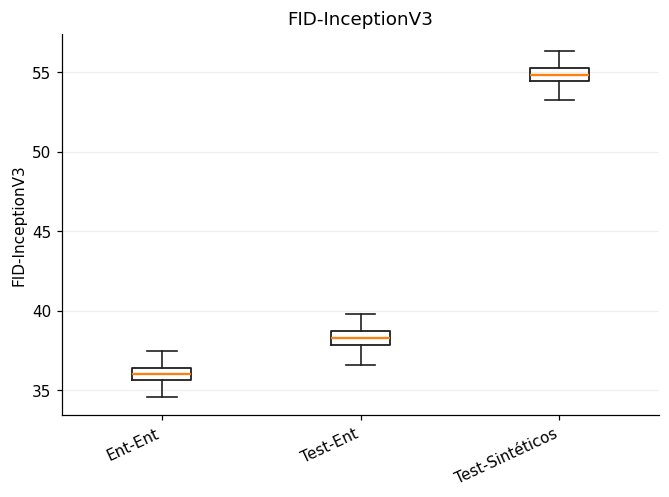

In [50]:
run_block('fid', lambda: run_frechet('InceptionV3', DIR['fid']))


Ejecutando: fd_dinov2


Loading weights:   0%|          | 0/223 [00:00<?, ?it/s]

DINOv2_S train:   0%|          | 0/474 [00:00<?, ?it/s]

DINOv2_S test_final:   0%|          | 0/53 [00:00<?, ?it/s]

DINOv2_S conjunto_1260:   0%|          | 0/158 [00:00<?, ?it/s]

Distancias DINOv2_S:   0%|          | 0/1000 [00:00<?, ?it/s]

,comparison,n,mean,sd,median,p025,q25,q75,p975,interval_type,comparison_label
0,train_train,1000,81.966953,2.280678,81.889666,77.746255,80.382851,83.541529,86.677737,percentiles de submuestreo; no IC poblacional,Ent-Ent
1,test_train,1000,96.483727,3.111893,96.402795,90.768493,94.305970,98.411177,103.248587,percentiles de submuestreo; no IC poblacional,Test-Ent
2,test_conjunto_1260,1000,189.980813,2.708005,190.046054,184.847618,188.178781,191.784722,195.249767,percentiles de submuestreo; no IC poblacional,Test-Sintéticos


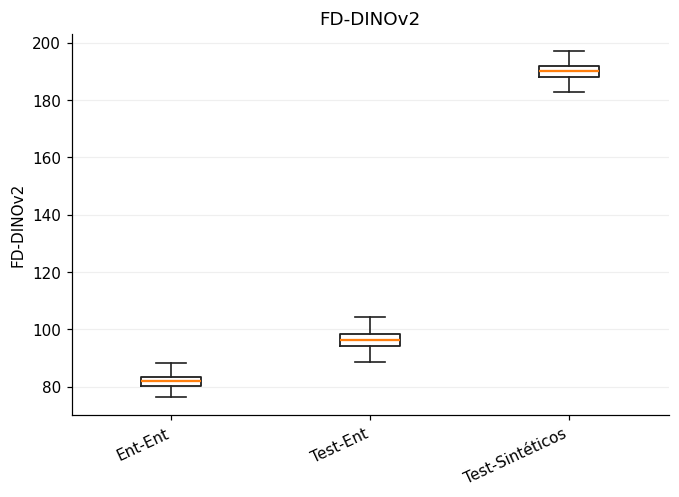

In [51]:
run_block('fd_dinov2', lambda: run_frechet('DINOv2_S', DIR['fd_dinov2']))

## Coherencia imagen–máscara

Las máscaras predichas por un segmentador externo se comparan con las máscaras disponibles mediante Dice y HD95. Se registran también ejemplos de concordancia espacial.

In [52]:
run_block('dice_y_hd95', run_segmentation_metrics, enabled=RUN['dice'] or RUN['hd95'])


Ejecutando: dice_y_hd95


Predicción SegFormer_B5_BRISC:   0%|          | 0/1680 [00:00<?, ?it/s]

[transformers] You passed `num_labels=2` which is incompatible to the `id2label` map of length `150`.


Loading weights:   0%|          | 0/1172 [00:00<?, ?it/s]

[transformers] SegformerForSemanticSegmentation LOAD REPORT from: nvidia/segformer-b5-finetuned-ade-640-640
Key                           | Status   |                                                                                                     
------------------------------+----------+-----------------------------------------------------------------------------------------------------
decode_head.classifier.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150]) vs model:torch.Size([2])                      
decode_head.classifier.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([150, 768, 1, 1]) vs model:torch.Size([2, 768, 1, 1])

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.


Métricas SegFormer_B5_BRISC:   0%|          | 0/1680 [00:00<?, ?it/s]

,case_key,basename,source,dataset,condition,tumor_code,plane_code,image_path,mask_path,original_image_path,...,hd95_diagonal,area_fraction,target_empty,prediction_empty,prediction_error,hd95_defined,p_me,p_gl,p_pi,p_no_tumor
0,test_final__brisc2025_test_00001_gl_ax_t1,brisc2025_test_00001_gl_ax_t1,test_final,test_final,gl_ax,gl,ax,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,...,0.210544,0.004364,False,False,,True,NaN,NaN,NaN,NaN
1,test_final__brisc2025_test_00002_gl_ax_t1,brisc2025_test_00002_gl_ax_t1,test_final,test_final,gl_ax,gl,ax,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,...,NaN,0.008362,False,True,,False,NaN,NaN,NaN,NaN
2,test_final__brisc2025_test_00003_gl_ax_t1,brisc2025_test_00003_gl_ax_t1,test_final,test_final,gl_ax,gl,ax,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,...,0.307749,0.022018,False,False,,True,NaN,NaN,NaN,NaN
3,test_final__brisc2025_test_00004_gl_ax_t1,brisc2025_test_00004_gl_ax_t1,test_final,test_final,gl_ax,gl,ax,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,...,0.263758,0.015198,False,False,,True,NaN,NaN,NaN,NaN
4,test_final__brisc2025_test_00005_gl_ax_t1,brisc2025_test_00005_gl_ax_t1,test_final,test_final,gl_ax,gl,ax,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,K:\Tesis\Github\data\BRISC2025\segmentation_ta...,...,0.152358,0.004501,False,False,,True,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1675,lote_01__pi_sa__intento_00046,NaN,synthetic,conjunto_1260,pi_sa,pi,sa,K:\Tesis\Github\results\OE4\01_generacion\conj...,K:\Tesis\Github\results\OE4\01_generacion\conj...,NaN,...,0.053677,0.012405,False,False,,True,NaN,NaN,NaN,NaN
1676,lote_01__pi_sa__intento_00047,NaN,synthetic,conjunto_1260,pi_sa,pi,sa,K:\Tesis\Github\results\OE4\01_generacion\conj...,K:\Tesis\Github\results\OE4\01_generacion\conj...,NaN,...,0.015686,0.011749,False,False,,True,NaN,NaN,NaN,NaN
1677,lote_01__pi_sa__intento_00048,NaN,synthetic,conjunto_1260,pi_sa,pi,sa,K:\Tesis\Github\results\OE4\01_generacion\conj...,K:\Tesis\Github\results\OE4\01_generacion\conj...,NaN,...,0.014735,0.023331,False,False,,True,NaN,NaN,NaN,NaN
1678,lote_01__pi_sa__intento_00049,NaN,synthetic,conjunto_1260,pi_sa,pi,sa,K:\Tesis\Github\results\OE4\01_generacion\conj...,K:\Tesis\Github\results\OE4\01_generacion\conj...,NaN,...,0.021118,0.015442,False,False,,True,NaN,NaN,NaN,NaN



Ejecutando: ejemplos_segformer
Advertencia: ningún caso restante alcanza Dice >= 0.970 para bueno; se utiliza el mayor disponible (0.969).


Predicción SegFormer_B5_BRISC:   0%|          | 0/1260 [00:00<?, ?it/s]

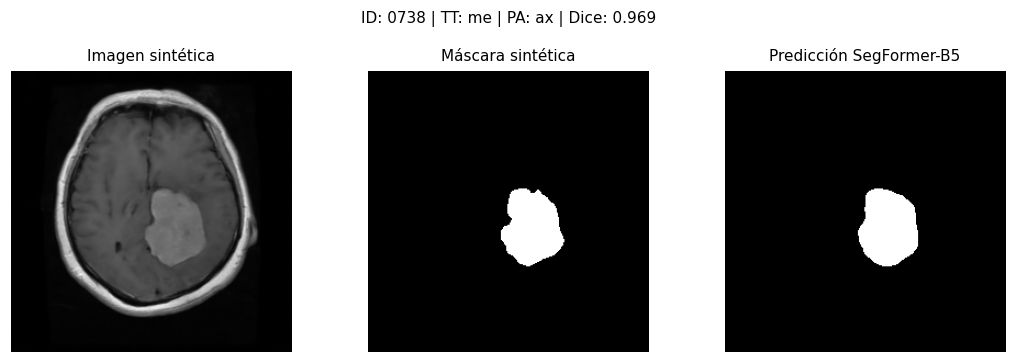

Ejemplo SegFormer generado: K:\Tesis\Github\results\OE4\graficos\ejemplo_segmentacion_SegFormer_B5_BRISC_bueno.pdf


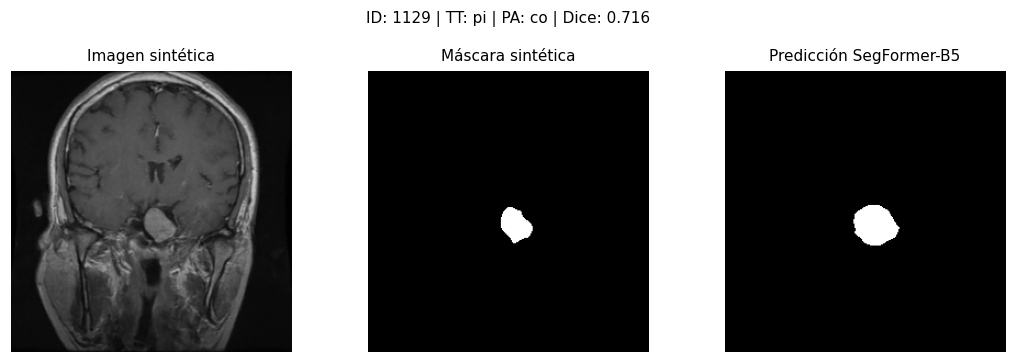

Ejemplo SegFormer generado: K:\Tesis\Github\results\OE4\graficos\ejemplo_segmentacion_SegFormer_B5_BRISC_mediano.pdf


In [53]:
run_block(
    'ejemplos_segformer',
    lambda: run_segformer_examples(
        dice_min_bueno=0.97,
        dice_min_mediano=0.67,
    )
)


## Distribuciones de intensidad

Se construyen histogramas normalizados de 128 intervalos para la región completa, tumoral y no tumoral. Las distribuciones se agregan por condición, tipo tumoral y plano anatómico, y se comparan mediante Wasserstein y Energy Distance.


Ejecutando: intensidades


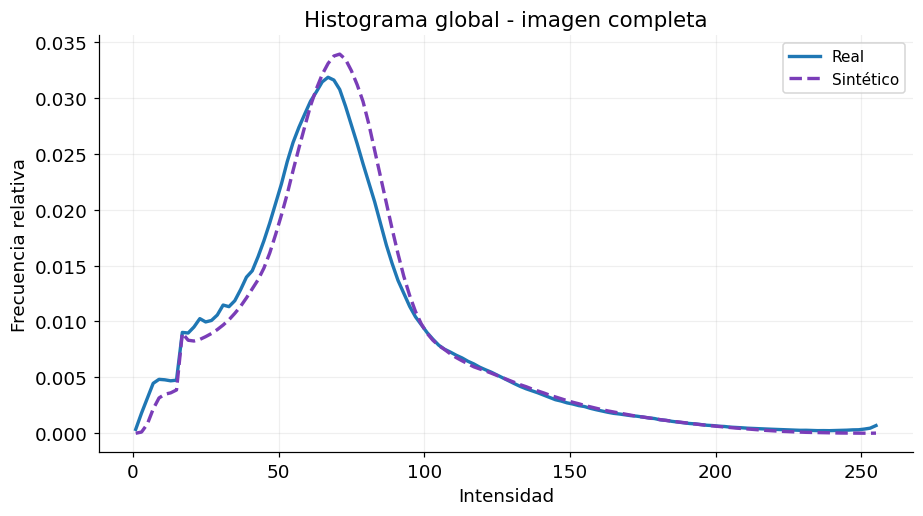

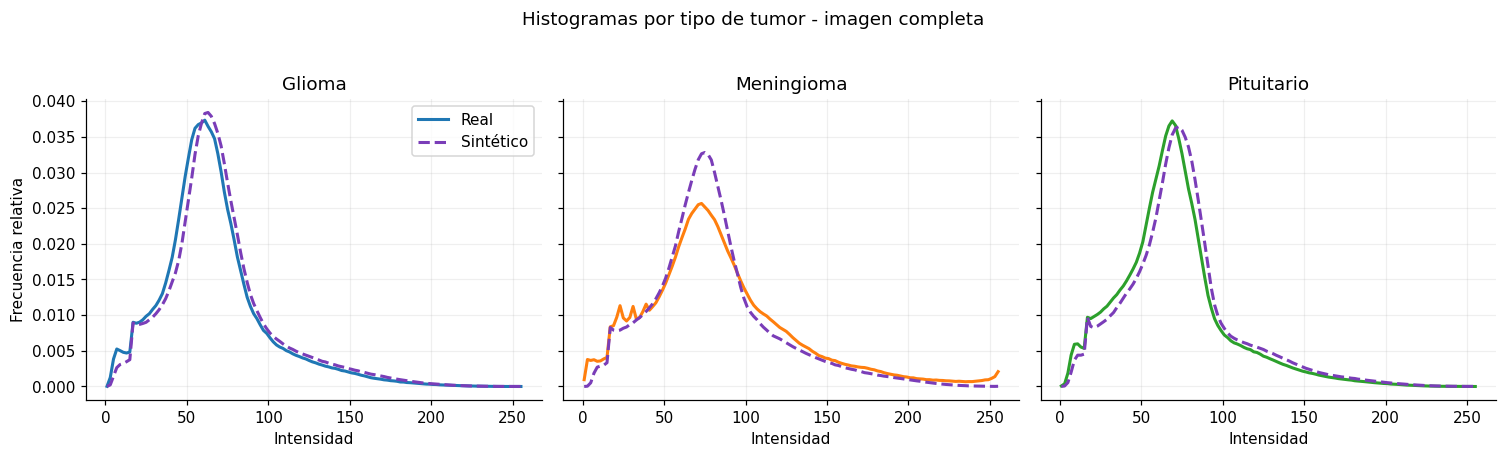

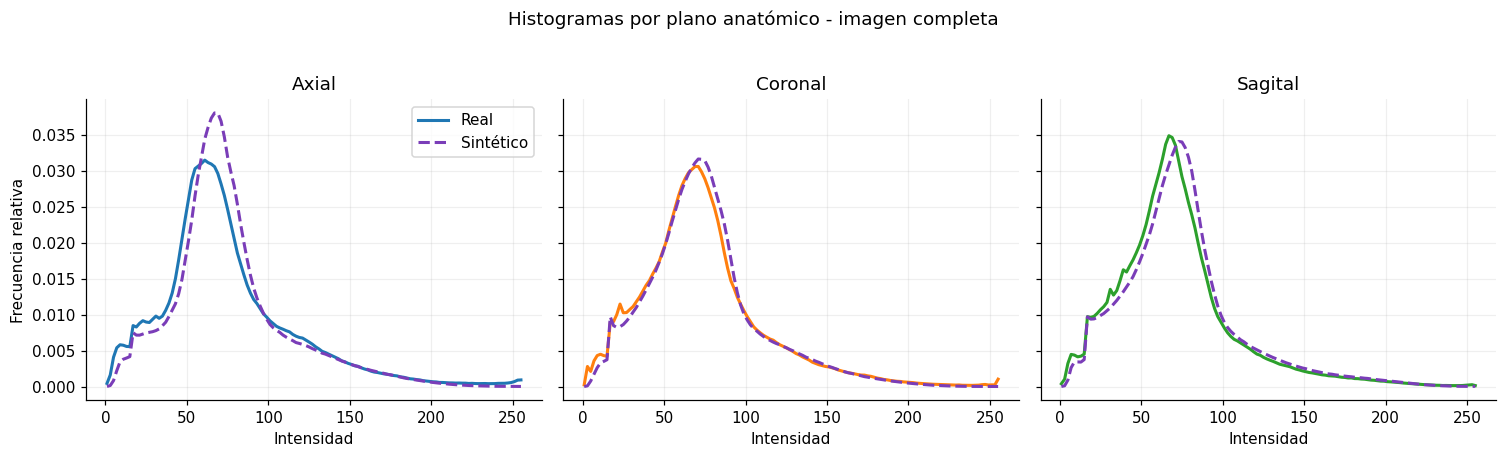

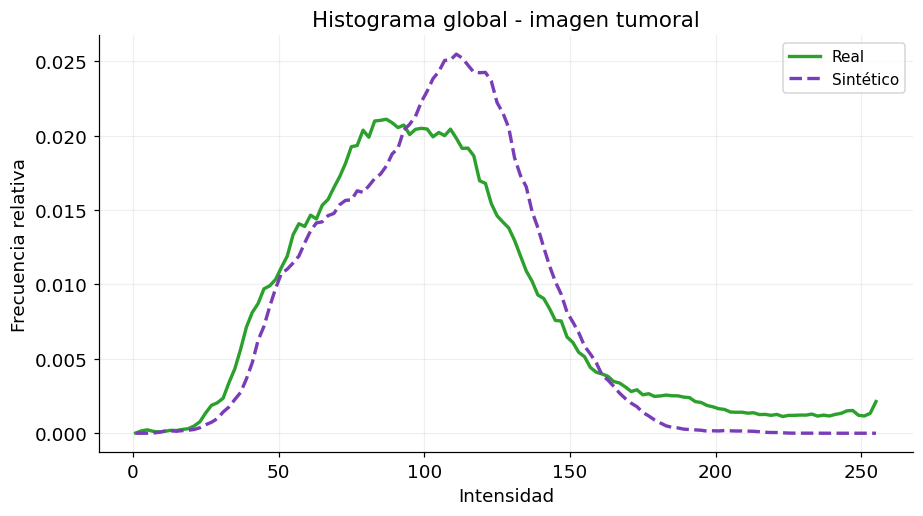

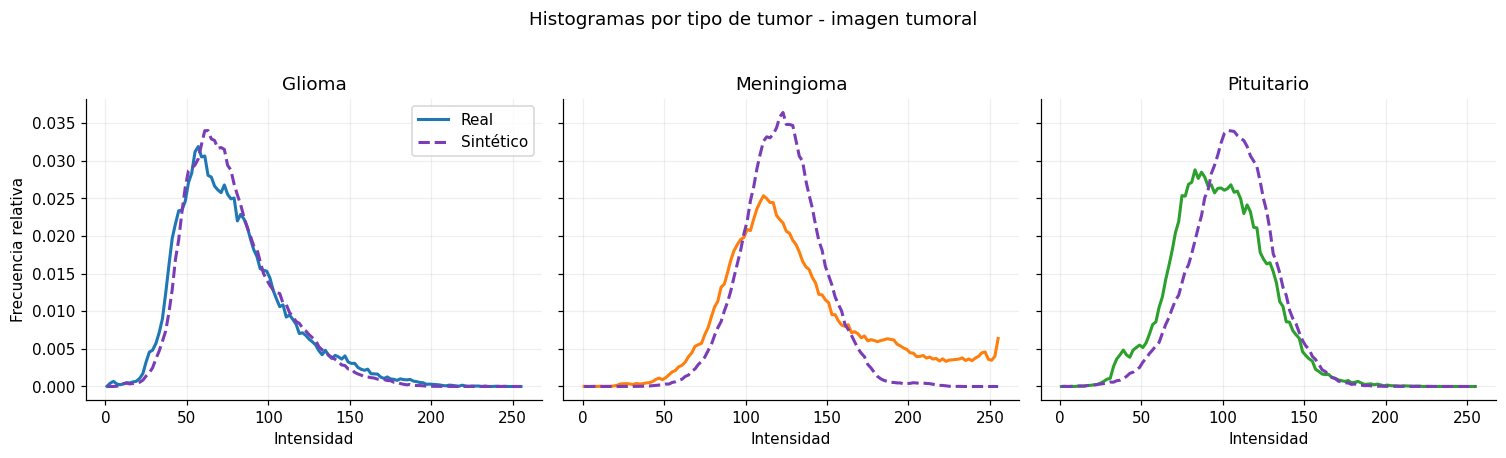

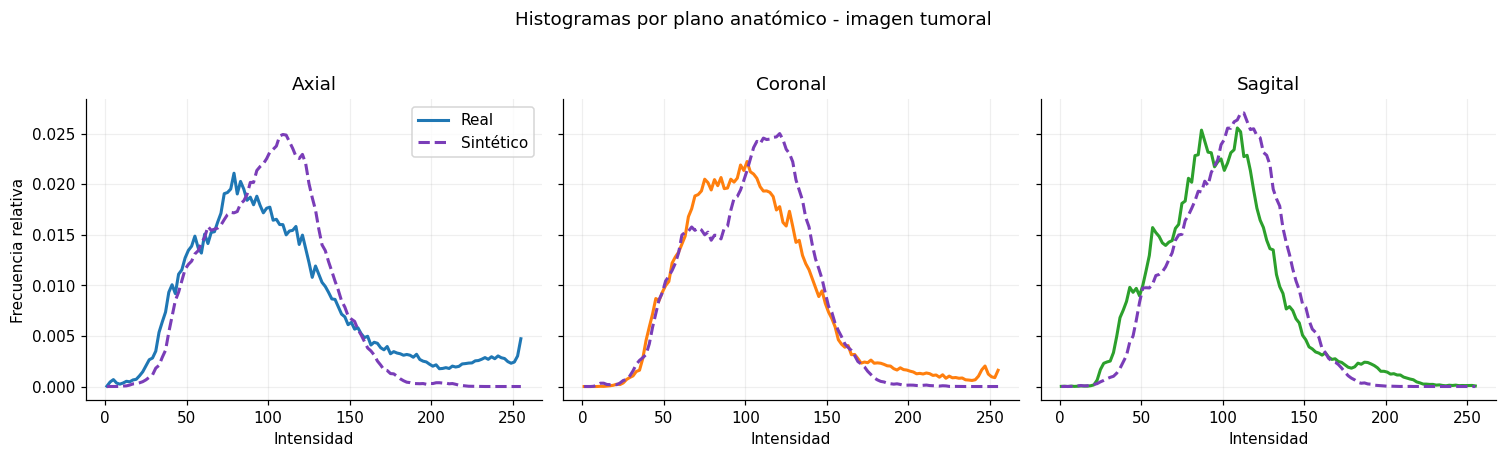

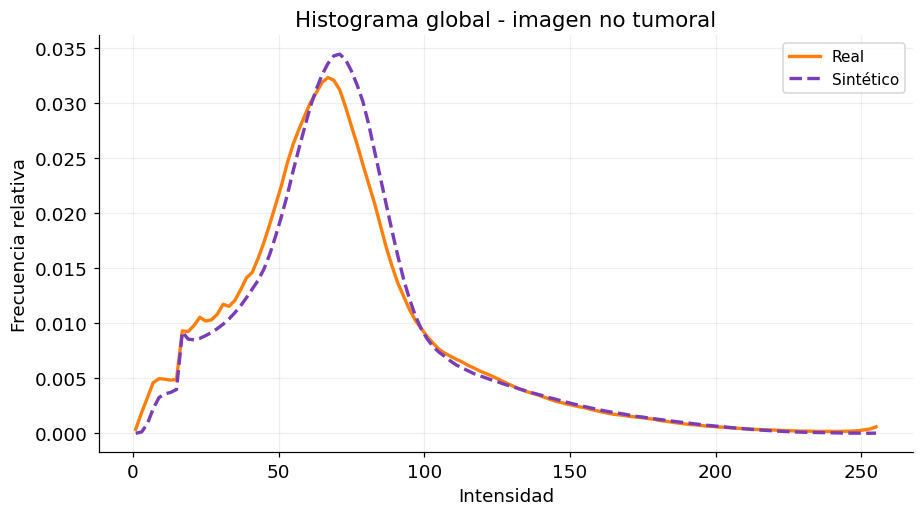

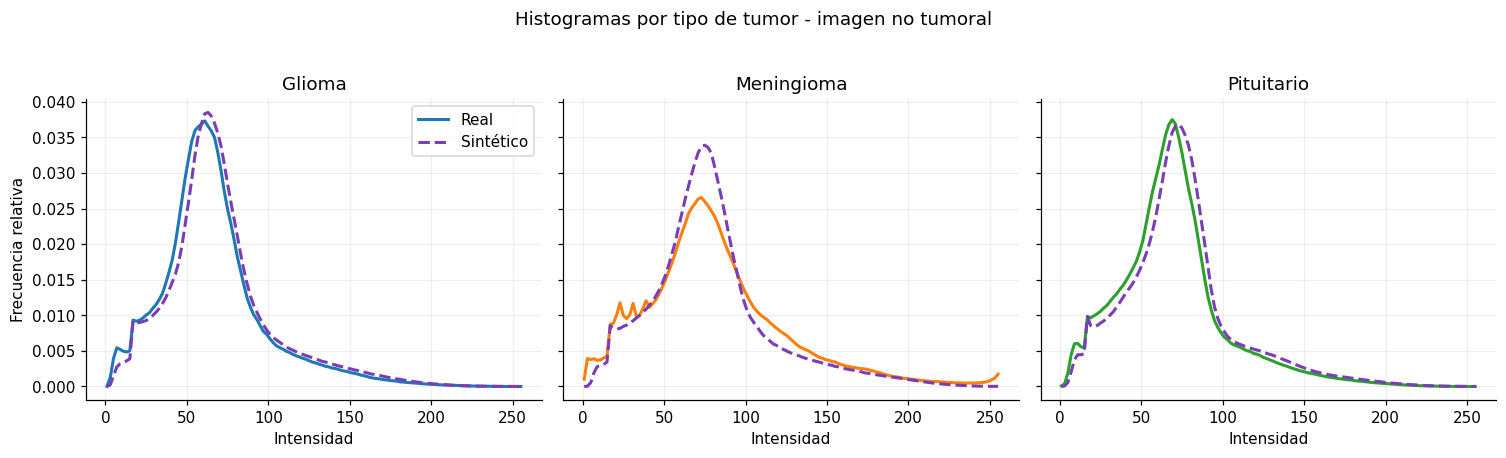

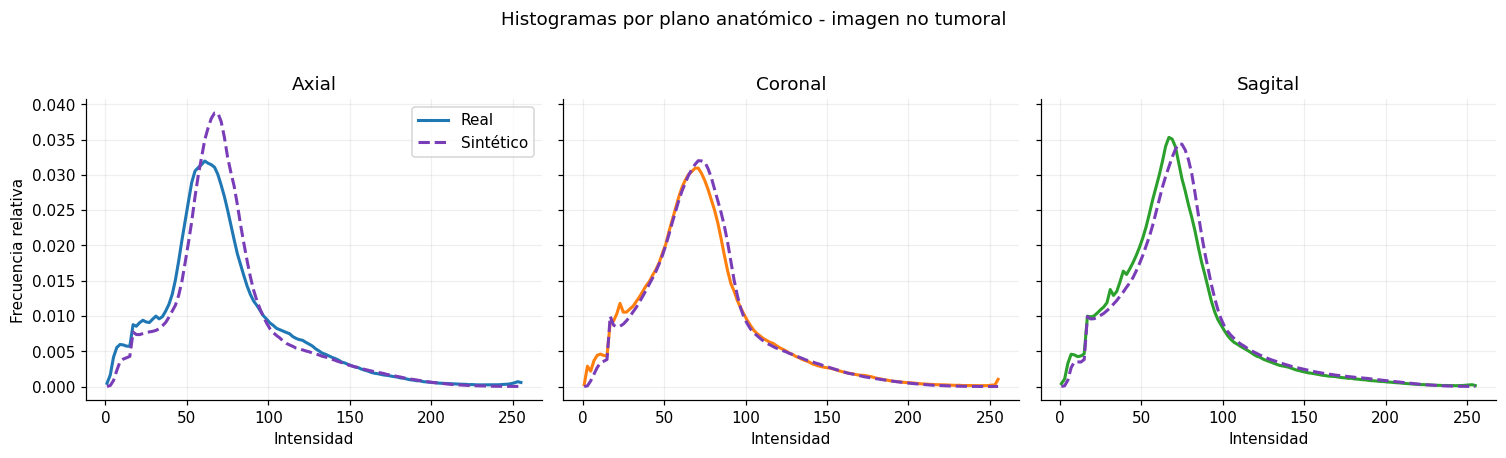

In [54]:
run_block('intensidades', run_intensities)

## Diversidad y cobertura distribucional

Se estiman la densidad y la cobertura en el espacio de características DINOv2, utilizando comparaciones con tamaños y composición controlados.


Ejecutando: densidad_cobertura


Densidad y cobertura:   0%|          | 0/200 [00:00<?, ?it/s]

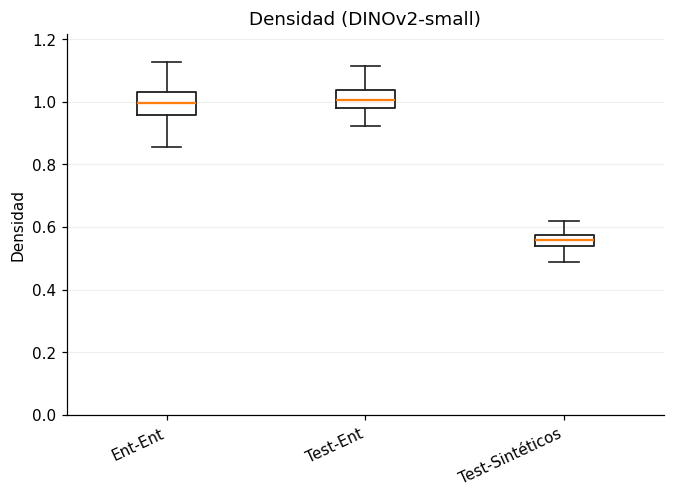

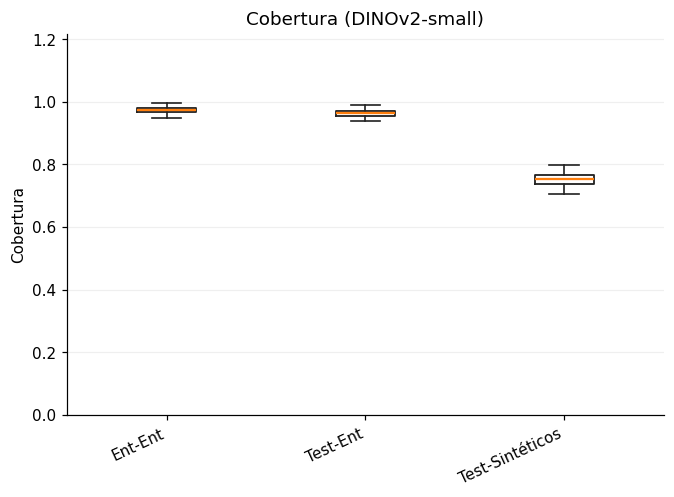

In [55]:
run_block('densidad_cobertura', run_diversity)

## Consistencia condicional

Se comparan las condiciones de tipo tumoral con las predicciones de un clasificador externo DenseNet-121.


Ejecutando: clasificacion


Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Clasificación DenseNet-121:   0%|          | 0/105 [00:00<?, ?it/s]

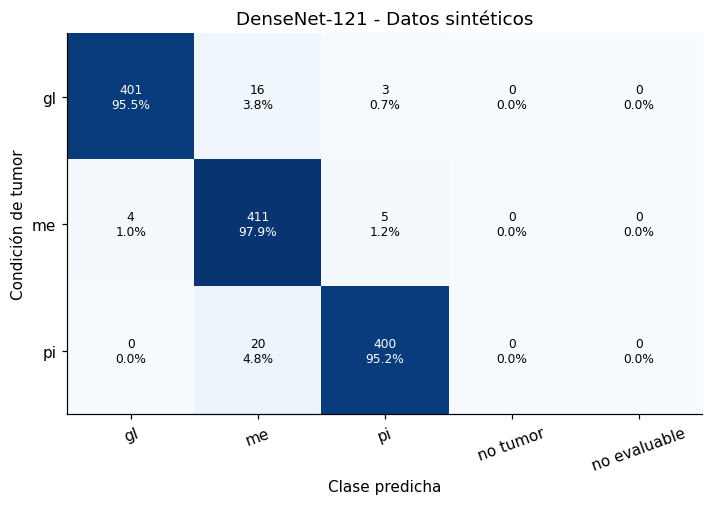

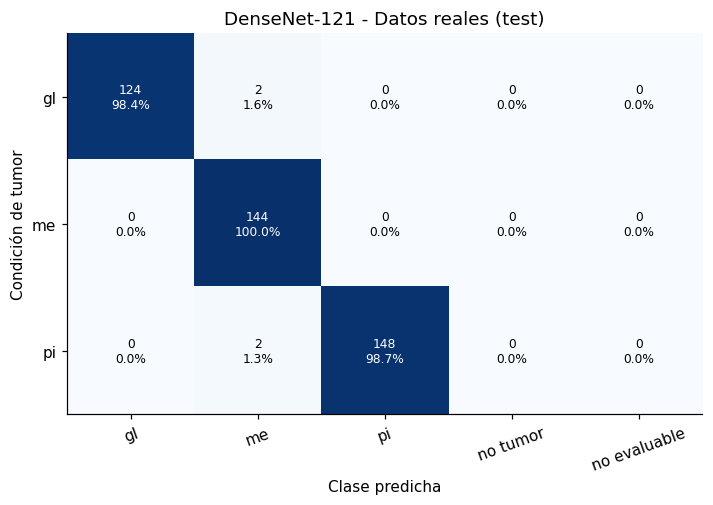

,model,dataset_real,accuracy_evaluable_real,accuracy_contando_fallos_real,macro_9_accuracy_real,macro_f1_3_tumores_real,n_total_real,n_evaluable_real,n_errores_tecnicos_real,n_pred_no_tumor_real,dataset_sintetico,accuracy_evaluable_sintetico,accuracy_contando_fallos_sintetico,macro_9_accuracy_sintetico,macro_f1_3_tumores_sintetico,n_total_sintetico,n_evaluable_sintetico,n_errores_tecnicos_sintetico,n_pred_no_tumor_sintetico,delta_macro_9_sintetico_menos_real
0,Purino_DenseNet121,test_final,0.990476,0.990476,0.990333,0.99053,420,420,0,0,conjunto_1260,0.961905,0.961905,0.961905,0.962134,1260,1260,0,0,-0.028428


,model,dataset,accuracy_evaluable,accuracy_contando_fallos,macro_9_accuracy,macro_f1_3_tumores,n_total,n_evaluable,n_errores_tecnicos,n_pred_no_tumor
0,Purino_DenseNet121,conjunto_1260,0.961905,0.961905,0.961905,0.962134,1260,1260,0,0
1,Purino_DenseNet121,test_final,0.990476,0.990476,0.990333,0.990530,420,420,0,0


Clasificación con DenseNet-121 guardada en: K:\Tesis\Github\results\OE4\11_consistencia_condicional\Purino_DenseNet121


,model,dataset,accuracy_evaluable,accuracy_contando_fallos,macro_9_accuracy,macro_f1_3_tumores,n_total,n_evaluable,n_errores_tecnicos,n_pred_no_tumor
0,Purino_DenseNet121,conjunto_1260,0.961905,0.961905,0.961905,0.962134,1260,1260,0,0
1,Purino_DenseNet121,test_final,0.990476,0.990476,0.990333,0.990530,420,420,0,0


In [56]:
run_block('clasificacion', run_classification)


Ejecutando: actualizar_figuras


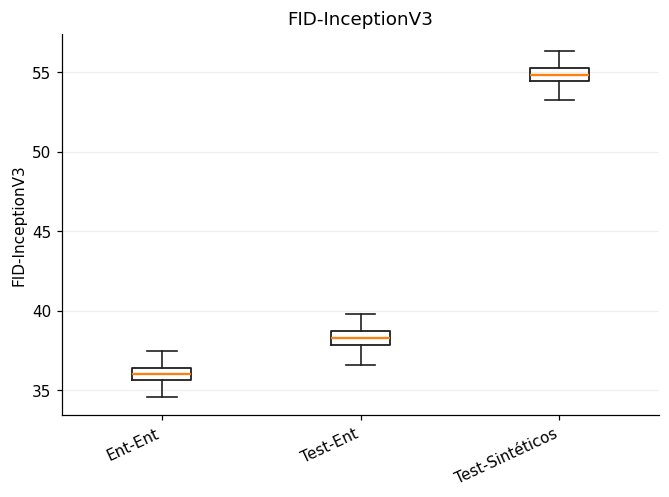

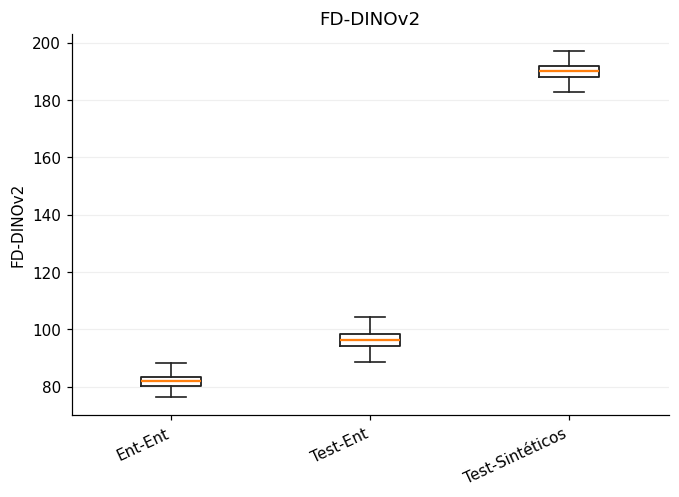

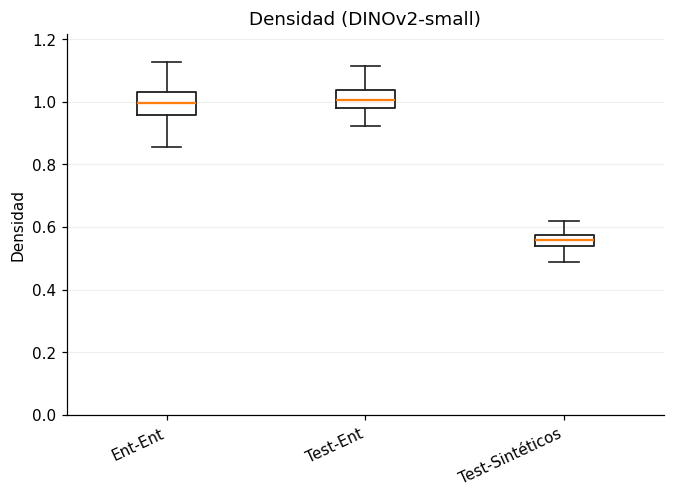

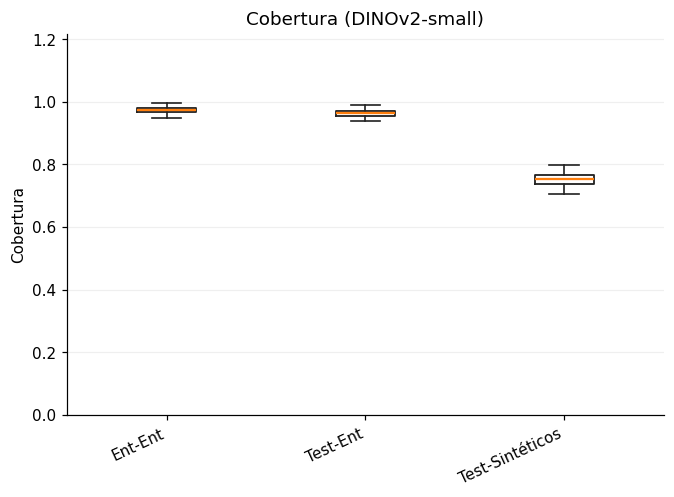

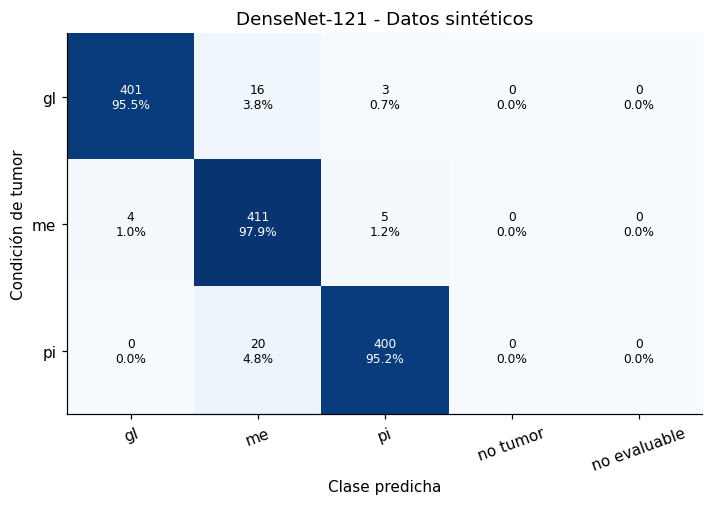

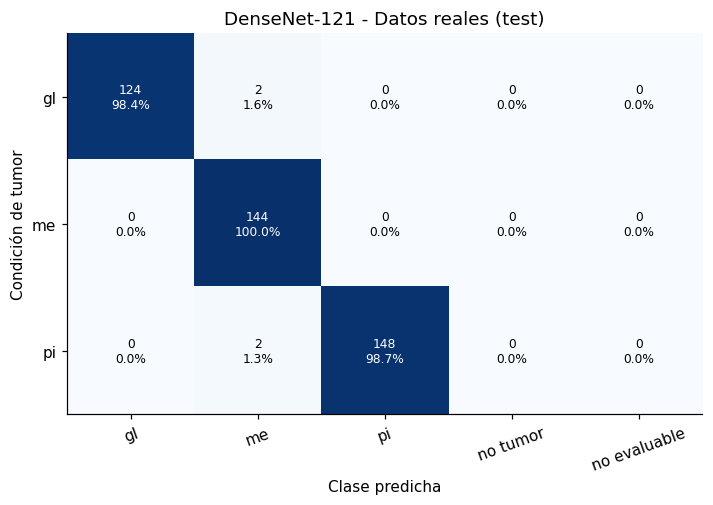

In [57]:
run_block('actualizar_figuras', run_refresh_figures)

## Galería de pares sintéticos

Se seleccionan 20 observaciones de manera reproducible para representar las nueve condiciones. Un inventario permite vincular los identificadores mostrados con sus archivos originales.


Ejecutando: galeria_sinteticos


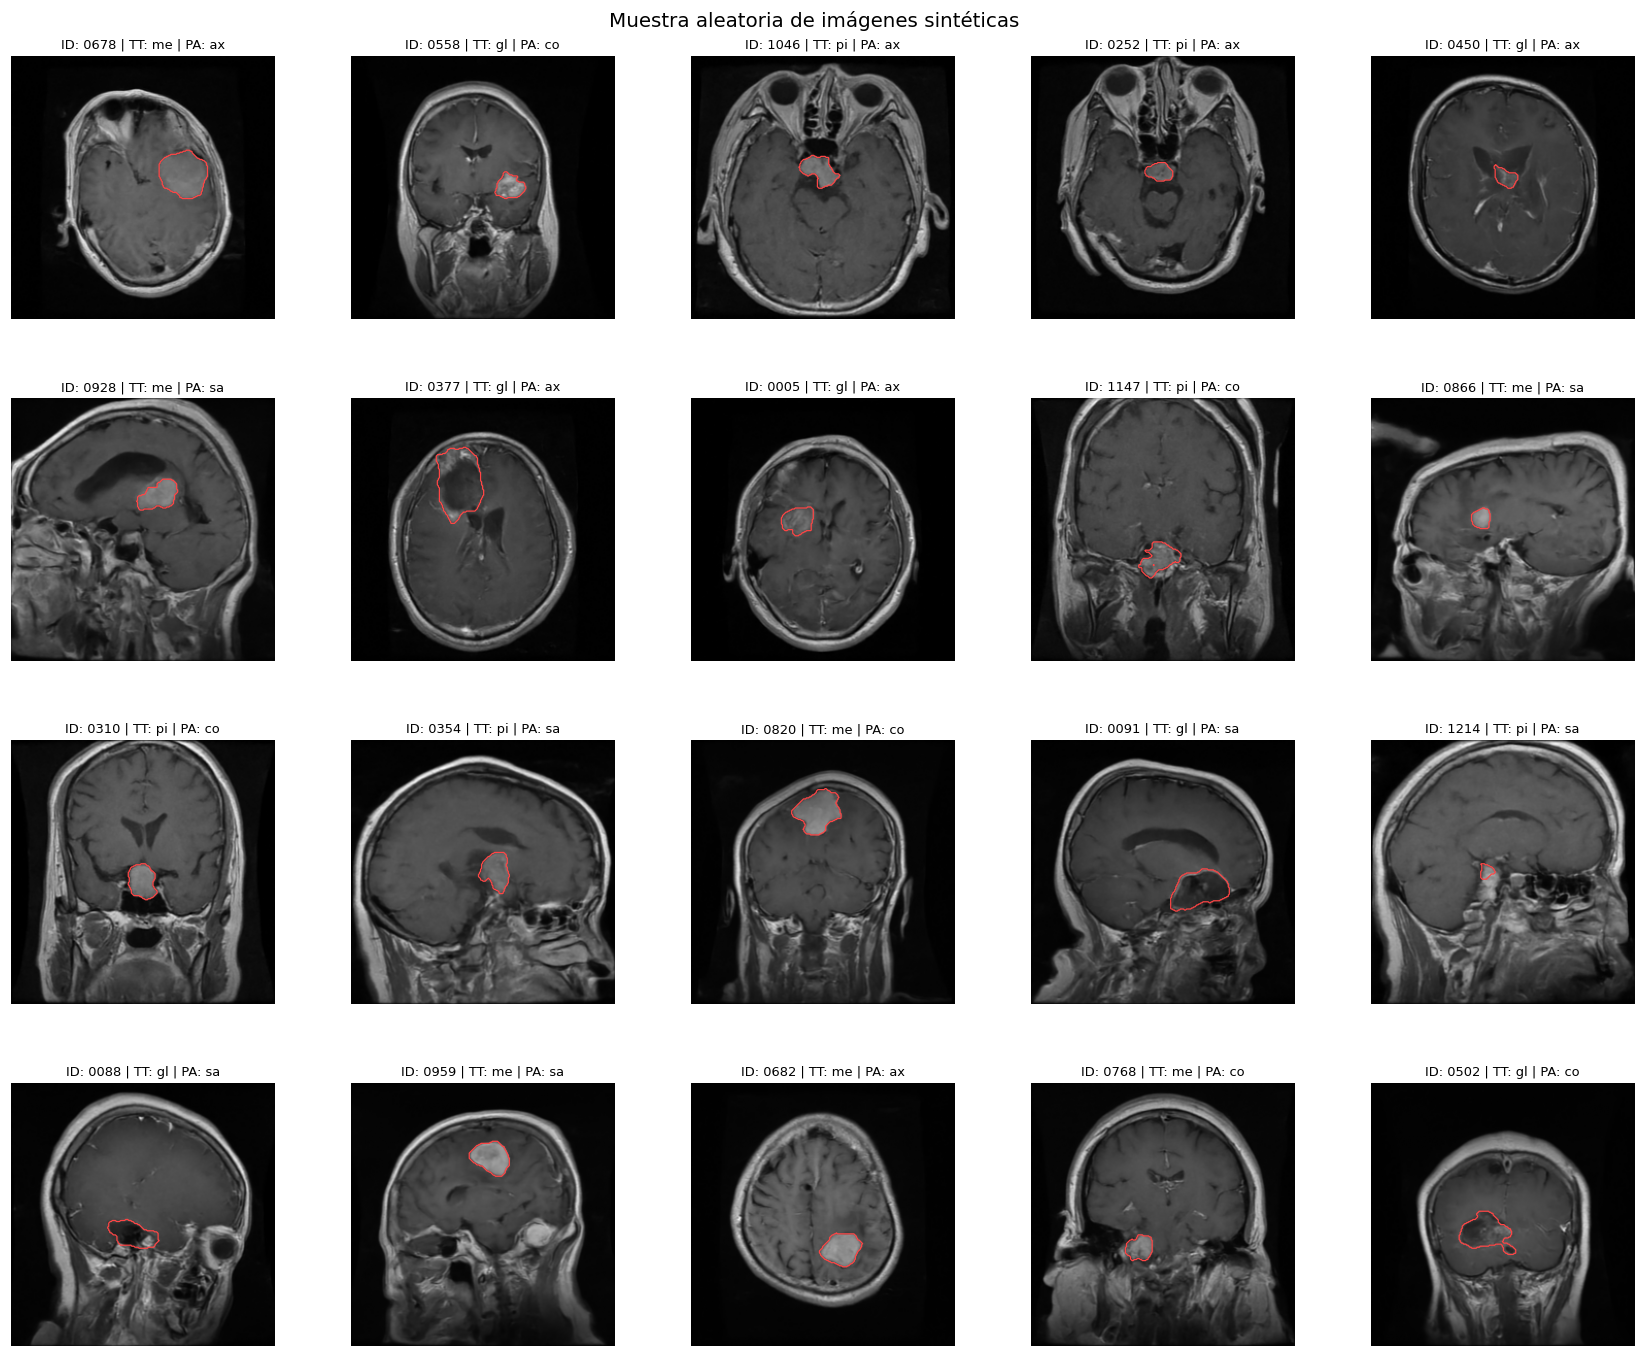

Galería guardada en: K:\Tesis\Github\results\OE4\graficos\sinteticos.pdf


In [58]:
run_block('galeria_sinteticos', run_synthetic_gallery)

## Registro de resultados

Se guarda el estado de ejecución, el inventario de archivos y un índice de las figuras generadas.

In [59]:
finalize_run()

,region,p_value,familia,p_holm_familia_3
0,completa,0.0005,tres_regiones_de_intensidad,0.0015
1,tumor,0.0005,tres_regiones_de_intensidad,0.0015
2,no_tumoral,0.0005,tres_regiones_de_intensidad,0.0015
